In [14]:
# Import required libraries for data analysis and visualization
import os, glob, pandas as pd, seaborn as sns, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

In [15]:
import re

# Load master heatmap CSV files from current directory
csv_files = glob.glob("master_heatmap*.csv")  # Find all CSV files in current directory

def extract_teff_bin(filename):
    match = re.search(r'(\d{4})_(\d{4})_K', filename)
    if match:
        return f"{match.group(1)}_{match.group(2)}"
    return None

# Load and combine all CSV files into a single dataframe, adding temperature bin
df = pd.DataFrame()
for f in csv_files:
    temp_bin = extract_teff_bin(f)
    temp_df = pd.read_csv(f)
    temp_df['teff_bin'] = temp_bin
    df = pd.concat([df, temp_df], ignore_index=True)

print(f"Combined dataframe shape: {df.shape}")
print(f"Columns: {list(df.columns)}")
print(df.head())



Combined dataframe shape: (336, 7)
Columns: ['radius_bin_center', 'period_bin_center', 'detections', 'trials', 'transit_prob', 'detection_rate', 'teff_bin']
   radius_bin_center  period_bin_center  detections  trials  transit_prob  \
0           1.923851           0.786000          35      41      0.223672   
1           1.923851           1.336168          23      32      0.159946   
2           1.923851           2.271888          19      26      0.111589   
3           1.923851           3.863276          24      40      0.081419   
4           1.923851           6.569863          16      31      0.055436   

   detection_rate   teff_bin  
0        0.853659  4000_4500  
1        0.718750  4000_4500  
2        0.730769  4000_4500  
3        0.600000  4000_4500  
4        0.516129  4000_4500  


Period values: [ 0.786       1.33616763  2.2718882   3.86327637  6.56986297 11.17286733
 18.99781387]
Period log values: [-0.10457745  0.12586095  0.35638696  0.58695578  0.81755631  1.04816464
  1.27870363]
Period bin edges: [0.6028417826212565, 1.0248062058899103, 1.7423040703393378, 2.9625887317403348, 5.037975426914379, 8.567625539322146, 14.56914733367361, 24.772687354491236]
Number of bins: 7


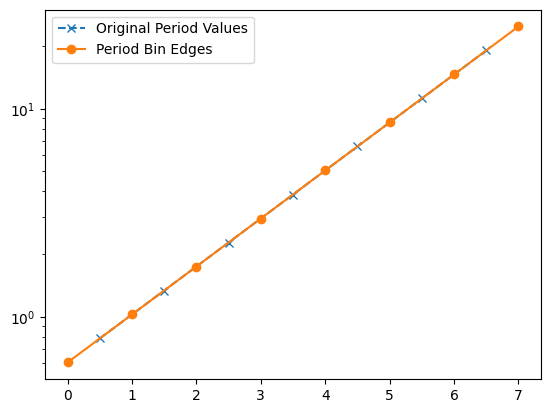

Radius values: [1.92385113 2.1977049  2.51054084 2.86790793 3.27614504 3.74249332]
Radius log values: [0.28417146 0.34196938 0.39976729 0.45756521 0.51536312 0.57316103]
Radius bin edges: [1.7999999999999998, 2.056223979157517, 2.348920584701318, 2.6832815729997477, 3.065237729574213, 3.501564067427134, 3.999999999999999]
Number of bins: 6


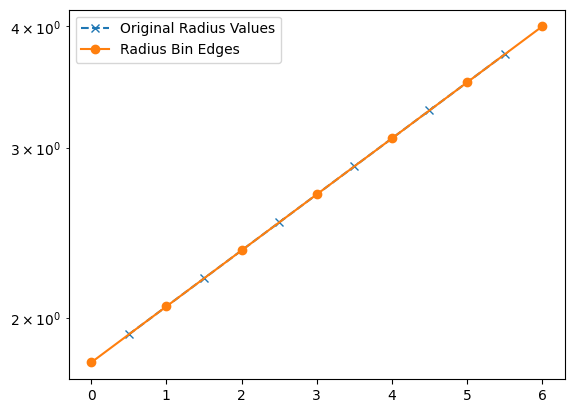


radius grid shared across Teff slices? True
period grid shared across Teff slices? True


In [16]:
# Generate log-spaced bin edges for True Period values
period_vals = np.array(sorted(df['period_bin_center'].unique()))  # Get unique period values

# Calculate log-space halfway points between adjacent values
period_log = np.log10(period_vals)  # Convert to log space
period_bin_edges = []

# First edge: extrapolate backward using same log spacing as first interval
log_step = period_log[1] - period_log[0]  # Log spacing between first two values
first_edge = 10**(period_log[0] - log_step/2)  # Extrapolate backward by half step
period_bin_edges.append(first_edge)

# Middle edges: halfway points in log space between adjacent values
for i in range(len(period_log) - 1):
    halfway_log = (period_log[i] + period_log[i+1]) / 2  # Midpoint in log space
    period_bin_edges.append(10**halfway_log)  # Convert back to linear space

# Last edge: extrapolate forward using same log spacing as last interval
log_step = period_log[-1] - period_log[-2]  # Log spacing between last two values
last_edge = 10**(period_log[-1] + log_step/2)  # Extrapolate forward by half step
period_bin_edges.append(last_edge)

# Print results for verification
print(f"Period values: {period_vals}")
print(f"Period log values: {period_log}")
print(f"Period bin edges: {period_bin_edges}")
print(f"Number of bins: {len(period_bin_edges) - 1}")

# Plot to visualize period values vs bin edges
period_vals_x_axis = np.arange(len(period_vals)) + 0.5  # Offset for visualization
plt.plot(period_vals_x_axis, period_vals, 'x--', label='Original Period Values')
plt.plot(period_bin_edges, 'o-', label='Period Bin Edges')
plt.legend()
plt.yscale('log')  # Log scale for better visualization
plt.show()

# Generate log-spaced bin edges for True Radius values (same method as periods)
radius_vals = np.array(sorted(df['radius_bin_center'].unique()))  # Get unique radius values

# Calculate log-space halfway points between adjacent values
radius_log = np.log10(radius_vals)  # Convert to log space
radius_bin_edges = []

# First edge: extrapolate backward using same log spacing as first interval
log_step = radius_log[1] - radius_log[0]  # Log spacing between first two values
first_edge = 10**(radius_log[0] - log_step/2)  # Extrapolate backward by half step
radius_bin_edges.append(first_edge)

# Middle edges: halfway points in log space between adjacent values
for i in range(len(radius_log) - 1):
    halfway_log = (radius_log[i] + radius_log[i+1]) / 2  # Midpoint in log space
    radius_bin_edges.append(10**halfway_log)  # Convert back to linear space

# Last edge: extrapolate forward using same log spacing as last interval
log_step = radius_log[-1] - radius_log[-2]  # Log spacing between last two values
last_edge = 10**(radius_log[-1] + log_step/2)  # Extrapolate forward by half step
radius_bin_edges.append(last_edge)

# Print results for verification
print(f"Radius values: {radius_vals}")
print(f"Radius log values: {radius_log}")
print(f"Radius bin edges: {radius_bin_edges}")
print(f"Number of bins: {len(radius_bin_edges) - 1}")

# Plot to visualize radius values vs bin edges
radius_vals_x_axis = np.arange(len(radius_vals)) + 0.5  # Offset for visualization
plt.plot(radius_vals_x_axis, radius_vals, 'x--', label='Original Radius Values')
plt.plot(radius_bin_edges, 'o-', label='Radius Bin Edges')
plt.legend()
plt.yscale('log')  # Log scale for better visualization
plt.show()



# --- Per-Teff bin edges ----------------------------------------------------
# The radius grid is NOT necessarily shared across Teff slices. With an
# empirical lower boundary it shifts with stellar type, so the global
# radius_bin_edges above becomes the UNION of several different grids and
# matches none of them exactly -- which makes the completeness merge below fail
# silently. Build the edges each Teff slice actually uses, with exactly the same
# log-midpoint rule as above, and key the merge off these instead.
def _log_edges(vals):
    v = np.asarray(sorted(np.unique(np.asarray(vals, dtype=float))), dtype=float)
    lg = np.log10(v)
    e = [10 ** (lg[0] - (lg[1] - lg[0]) / 2)]
    e += [10 ** ((lg[i] + lg[i + 1]) / 2) for i in range(len(lg) - 1)]
    e += [10 ** (lg[-1] + (lg[-1] - lg[-2]) / 2)]
    return np.asarray(e, dtype=float)

radius_edges_by_teff = {tb: _log_edges(gg['radius_bin_center'].unique())
                        for tb, gg in df.groupby('teff_bin')}
period_edges_by_teff = {tb: _log_edges(gg['period_bin_center'].unique())
                        for tb, gg in df.groupby('teff_bin')}

_shared_r = len({tuple(np.round(v, 6)) for v in radius_edges_by_teff.values()}) == 1
_shared_p = len({tuple(np.round(v, 6)) for v in period_edges_by_teff.values()}) == 1
print(f"\nradius grid shared across Teff slices? {_shared_r}")
print(f"period grid shared across Teff slices? {_shared_p}")
if not _shared_r:
    for tb in sorted(radius_edges_by_teff):
        print(f"  {tb}: {np.round(radius_edges_by_teff[tb], 4)}")


In [17]:
# Assign every heatmap row the bin edges of ITS OWN Teff slice. Using one
# global grid here is what silently broke the merge when the radius grid varies
# with Teff: rows get labelled with edges that exist in no single slice, so the
# join on (teff_bin, radius_bin_min/max, period_bin_min/max) finds nothing.
def _edges_for(centers, edges):
    e = np.asarray(edges, dtype=float)
    k = np.clip(np.searchsorted(e, np.asarray(centers, dtype=float), side='right') - 1,
                0, len(e) - 2)
    return e[k], e[k + 1]

for _c in ['radius_bin_min', 'radius_bin_max', 'period_bin_min', 'period_bin_max']:
    df[_c] = np.nan

for _tb, _idx in df.groupby('teff_bin').groups.items():
    _rmin, _rmax = _edges_for(df.loc[_idx, 'radius_bin_center'], radius_edges_by_teff[_tb])
    _pmin, _pmax = _edges_for(df.loc[_idx, 'period_bin_center'], period_edges_by_teff[_tb])
    df.loc[_idx, 'radius_bin_min'], df.loc[_idx, 'radius_bin_max'] = _rmin, _rmax
    df.loc[_idx, 'period_bin_min'], df.loc[_idx, 'period_bin_max'] = _pmin, _pmax

print(df.head())


   radius_bin_center  period_bin_center  detections  trials  transit_prob  \
0           1.923851           0.786000          35      41      0.223672   
1           1.923851           1.336168          23      32      0.159946   
2           1.923851           2.271888          19      26      0.111589   
3           1.923851           3.863276          24      40      0.081419   
4           1.923851           6.569863          16      31      0.055436   

   detection_rate   teff_bin  radius_bin_min  radius_bin_max  period_bin_min  \
0        0.853659  4000_4500             1.8        2.056224        0.602842   
1        0.718750  4000_4500             1.8        2.056224        1.024806   
2        0.730769  4000_4500             1.8        2.056224        1.742304   
3        0.600000  4000_4500             1.8        2.056224        2.962589   
4        0.516129  4000_4500             1.8        2.056224        5.037975   

   period_bin_max  
0        1.024806  
1        1.74230

673
completeness match: 672/673 rows (99.9%)


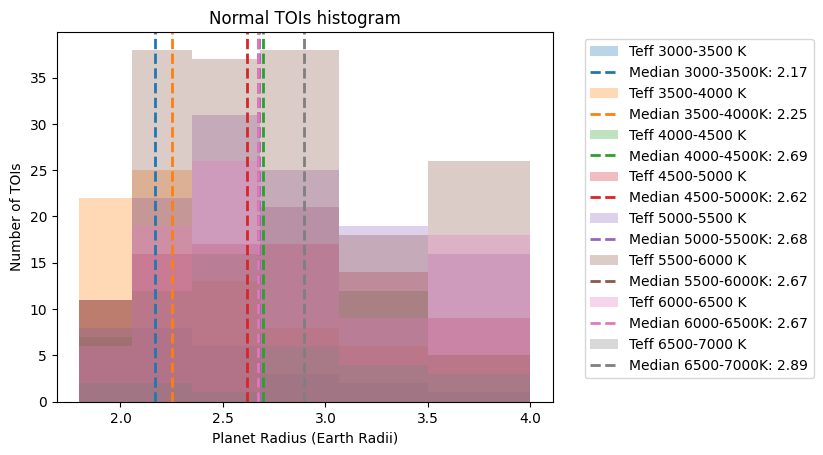

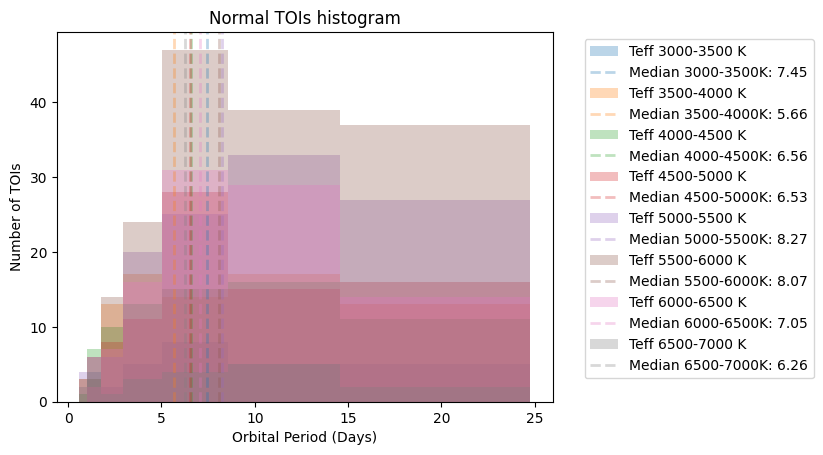

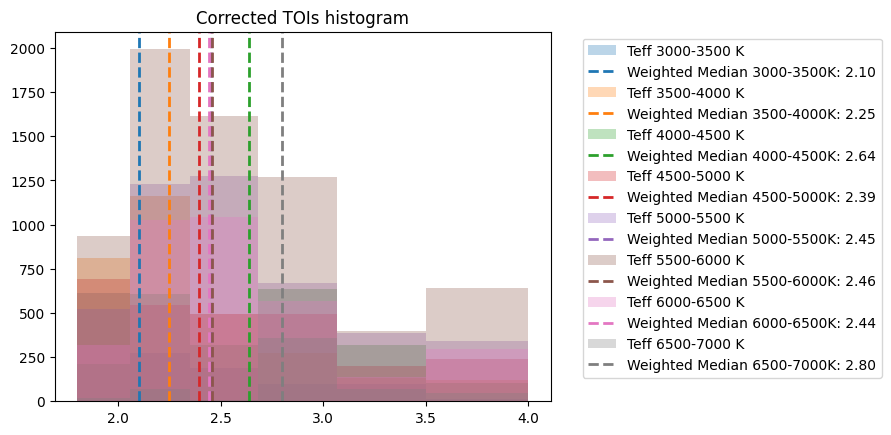

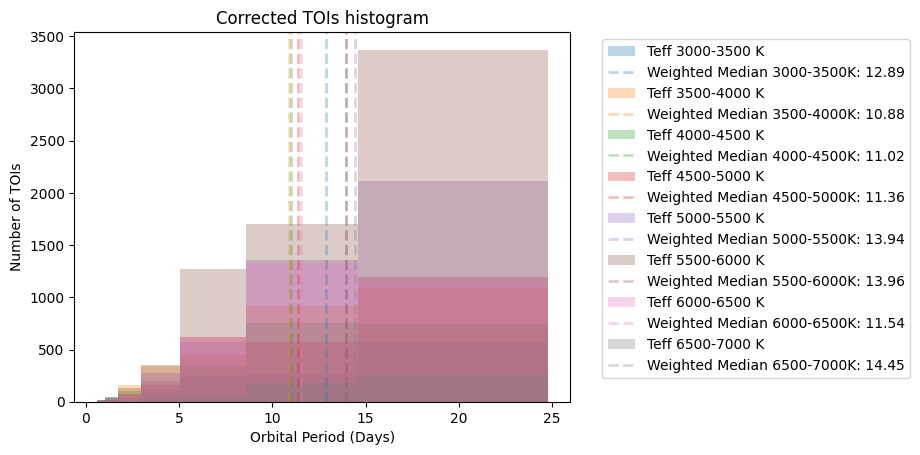

Rows with any NaNs in merged_df: 1
Rows with NaNs in merged_df:
         toi  st_teff  pl_rade  pl_orbper   teff_bin  radius_bin_min  \
598  1873.01   5699.0  3.93465  24.934188  5500_6000        3.501564   

     radius_bin_max  period_bin_min  period_bin_max  radius_bin_center  \
598             4.0             NaN             NaN                NaN   

     period_bin_center  detections  trials  transit_prob  detection_rate  \
598                NaN         NaN     NaN           NaN             NaN   

     detection_inverse  transit_inverse  weight  
598                NaN              NaN     1.0  
         toi  st_teff   pl_rade  pl_orbper   teff_bin  radius_bin_min  \
0    5165.01  4642.10  3.300100   3.577501  4500_5000        3.065238   
1    6944.01  5181.10  2.609860  12.302750  5000_5500        2.348921   
2    5789.01  5132.00  2.537040  12.925605  5000_5500        2.348921   
3    5319.01  3580.00  3.746810   4.078527  3500_4000        3.501564   
4    5082.01  5670.00  2

In [18]:
 
TOIs = pd.read_csv('../TOI_Mar2025_1pt5to4_R_detected_real_only.csv')

# Define temperature ranges matching our completeness data
teff_ranges = [(3000, 3500), (3500, 4000), (4000, 4500), (4500, 5000), 
               (5000, 5500), (5500, 6000), (6000, 6500), (6500, 7000)]

#teff_ranges = [(t, t + 1000) for t in range(3000, 7000, 1000)]

# Filter TOIs data
TOIs_filtered = TOIs.dropna(subset=['st_teff', 'pl_rade'])
#print(len(TOIs_filtered))

TOIs_filtered = TOIs_filtered[(TOIs_filtered['pl_rade'] > 1.8) & (TOIs_filtered['pl_rade'] < 4.0)]
TOIs_filtered = TOIs_filtered[(TOIs_filtered['pl_orbper'] > 0.6028) & (TOIs_filtered['pl_orbper'] < 25.1)]
TOIs_filtered = TOIs_filtered[(TOIs_filtered['st_tmag'] < 13)]
#TOIs_bootstrap = TOIs_bootstrap[~TOIs_bootstrap['toi'].isin([2194.01])] #second try ones with giant corrections

#TOIs_filtered = TOIs_filtered[~TOIs_filtered['id'].isin([80224448, 370009806])] # The ones with giant corrections
#TOIs_filtered = TOIs_filtered[~TOIs_filtered['toi'].isin([2482.01, 2194.01, 2103.02])] #second try ones with giant corrections
#TOIs_filtered = TOIs_filtered[~TOIs_filtered['toi'].isin([2194.01])] #second try ones with giant corrections
#TOIs_filtered = TOIs_filtered[TOIs_filtered['tfopwg_disp'] != 'FA']


#TOIs_filtered = TOIs_filtered[(TOIs_filtered['ruwe'] <= 1.4)]

# Remove false positives if column exists
if 'tfopwg_disp' in TOIs_filtered.columns:
    TOIs_filtered = TOIs_filtered[TOIs_filtered['tfopwg_disp'] != 'FP']

TOIs_filtered = TOIs_filtered[['toi', 'st_teff', 'pl_rade', 'pl_orbper']]

radius_bins = [(radius_bin_edges[i], radius_bin_edges[i+1]) for i in range(len(radius_bin_edges)-1)]

period_bins = [(period_bin_edges[i], period_bin_edges[i+1]) for i in range(len(period_bin_edges)-1)]
print(len(TOIs_filtered))

#print(radius_bins)
#print(period_bins)

# Pre-create the key columns so the per-row assignment below can read teff_bin
# back out even when a star falls outside every Teff range.
for _c in ['teff_bin', 'radius_bin_min', 'radius_bin_max', 'period_bin_min', 'period_bin_max']:
    if _c not in TOIs_filtered.columns:
        TOIs_filtered[_c] = np.nan

for row in TOIs_filtered.itertuples():
    teff = row.st_teff
    radius = row.pl_rade
    period = row.pl_orbper
    
    # Determine which temperature bin the TOI falls into
    for teff_min, teff_max in teff_ranges:
        if teff_min <= teff < teff_max:
            teff_bin = f"{teff_min}_{teff_max}"
            TOIs_filtered.at[row.Index, 'teff_bin'] = teff_bin
    
    # Bin radius and period with the edges belonging to THIS star's Teff slice,
    # so the merge keys below resolve against a cell that actually exists.
    _tb = TOIs_filtered.at[row.Index, 'teff_bin']
    if isinstance(_tb, str) and _tb in radius_edges_by_teff:
        _re = radius_edges_by_teff[_tb]
        if _re[0] <= radius < _re[-1]:
            _k = min(int(np.searchsorted(_re, radius, side='right')) - 1, len(_re) - 2)
            TOIs_filtered.at[row.Index, 'radius_bin_min'] = _re[_k]
            TOIs_filtered.at[row.Index, 'radius_bin_max'] = _re[_k + 1]
        _pe = period_edges_by_teff[_tb]
        if _pe[0] <= period < _pe[-1]:
            _k = min(int(np.searchsorted(_pe, period, side='right')) - 1, len(_pe) - 2)
            TOIs_filtered.at[row.Index, 'period_bin_min'] = _pe[_k]
            TOIs_filtered.at[row.Index, 'period_bin_max'] = _pe[_k + 1]

#print(TOIs_filtered)
  
# Merge TOIs with completeness data
merged_df = pd.merge(TOIs_filtered, df, on=['teff_bin', 'radius_bin_min', 'radius_bin_max', 'period_bin_min', 'period_bin_max'], how='left')

# Fail LOUDLY on a bad merge. Unmatched rows get weight 1 further down via
# .fillna(1), which silently turns "no completeness information" into "needs no
# correction" -- producing entirely plausible-looking medians built on nothing.
_matched = merged_df['detection_rate'].notna().sum()
print(f"completeness match: {_matched}/{len(merged_df)} rows "
      f"({100 * _matched / len(merged_df):.1f}%)")
if _matched < 0.95 * len(merged_df):
    print("  *** WARNING: >5% of TOIs have no completeness cell. Their weights "
          "default to 1 and the corrected medians are NOT trustworthy. ***")
#print(merged_df)

#### REGULAR HISTOGRAM
for temp_range in teff_ranges:
    teff_df = merged_df[(merged_df['st_teff'] >= temp_range[0]) & (merged_df['st_teff'] < temp_range[1])]
    n, bins, patches = plt.hist(teff_df['pl_rade'], bins=radius_bin_edges, alpha=.3,  label=f'Teff {temp_range[0]}-{temp_range[1]} K')
    hist_color = patches[0].get_facecolor()
    median_val = teff_df['pl_rade'].median()
    plt.axvline(median_val, linestyle='--', linewidth=2, color=hist_color, label=f'Median {temp_range[0]}-{temp_range[1]}K: {median_val:.2f}', alpha=1)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xlabel('Planet Radius (Earth Radii)')
    plt.ylabel('Number of TOIs')
    plt.title('Normal TOIs histogram')
plt.show()

for temp_range in teff_ranges:
    teff_df = merged_df[(merged_df['st_teff'] >= temp_range[0]) & (merged_df['st_teff'] < temp_range[1])]
    n, bins, patches = plt.hist(teff_df['pl_orbper'], bins=period_bin_edges, alpha=0.3, label=f'Teff {temp_range[0]}-{temp_range[1]} K')
    hist_color = patches[0].get_facecolor()
    median_val = teff_df['pl_orbper'].median()
    plt.axvline(median_val, linestyle='--', linewidth=2, color=hist_color, label=f'Median {temp_range[0]}-{temp_range[1]}K: {median_val:.2f}')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xlabel('Orbital Period (Days)')
    plt.ylabel('Number of TOIs')
    plt.title('Normal TOIs histogram')
plt.show()
########

# calculate inverse detection and transit probabilities
for row in merged_df.itertuples():
    detection_rate = row.detection_rate
    transit_prob = row.transit_prob

    # Only update detection_inverse and transit_inverse, leave other columns untouched
    if pd.notnull(detection_rate) and detection_rate > 0:
        merged_df.at[row.Index, 'detection_inverse'] = 1/detection_rate
    else:
        merged_df.at[row.Index, 'detection_inverse'] = np.nan

    if pd.notnull(transit_prob) and transit_prob > 0:
        merged_df.at[row.Index, 'transit_inverse'] = 1/transit_prob
    else:
        merged_df.at[row.Index, 'transit_inverse'] = np.nan
#print(merged_df)

#merged_df to csv
#merged_df[['toi', 'detection_inverse', 'transit_inverse']].to_csv('merged_df.csv', index=False)

# Duplicate each row of merged_df according to a per-row count value in a new column 'row_count'
# First, define how you want to calculate 'weight' for each row. 
# Example: here we use detection_inverse * transit_inverse rounded to nearest int, but you can change this logic.
merged_df['weight'] = (merged_df['detection_inverse'] * merged_df['transit_inverse']).fillna(1)
#merged_df['mult_count'] = np.where(merged_df['mult_count'] >= 1, merged_df['mult_count'] - 1, merged_df['mult_count'])
#print(merged_df[['toi', 'detection_rate', 'transit_prob', 'detection_inverse', 'transit_inverse', 'mult_count']])

#print(merged_df)
#print(merged_df[['toi', 'detection_inverse', 'transit_inverse', 'row_count']])
# Now repeat each row according to its 'row_count' value
#merged_df_corrected = merged_df#.loc[merged_df.index.repeat(merged_df['mult_count'])].reset_index(drop=True)

radius_medians = pd.DataFrame(columns=['Teff Range', 'Weighted Median Radius (Earth Radii)'])
###CORRECTED HISTOGRAM
for temp_range in teff_ranges:
    teff_df = merged_df[(merged_df['st_teff'] >= temp_range[0]) & (merged_df['st_teff'] < temp_range[1])]
    n, bins, patches = plt.hist(teff_df['pl_rade'], bins=radius_bin_edges, alpha=0.3,  label=f'Teff {temp_range[0]}-{temp_range[1]} K', weights=teff_df['weight'])
    hist_color = patches[0].get_facecolor()
    # Calculate weighted median
    vals = teff_df['pl_rade'].values
    weights = teff_df['weight'].values
    if len(vals) > 0 and weights.sum() > 0:
        sorted_idx = np.argsort(vals)
        vals_sorted = vals[sorted_idx]
        weights_sorted = weights[sorted_idx]
        cumsum = np.cumsum(weights_sorted)
        cutoff = weights_sorted.sum() / 2.0
        weighted_median = vals_sorted[np.searchsorted(cumsum, cutoff)]
        radius_medians = pd.concat([
            radius_medians,
            pd.DataFrame({
            'Teff Range': [f"{temp_range[0]}-{temp_range[1]}K"],
            'Weighted Median Radius (Earth Radii)': [weighted_median]
            })], ignore_index=True)
        plt.axvline(weighted_median, linestyle='--', linewidth=2, color=hist_color, label=f'Weighted Median {temp_range[0]}-{temp_range[1]}K: {weighted_median:.2f}', alpha=1)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.title('Corrected TOIs histogram')
plt.show()

#radius_medians.to_csv('corrected_medians.csv', index=False)

for temp_range in teff_ranges:
    teff_df = merged_df[(merged_df['st_teff'] >= temp_range[0]) & (merged_df['st_teff'] < temp_range[1])]
    n, bins, patches = plt.hist(teff_df['pl_orbper'], bins=period_bin_edges, alpha=0.3,  label=f'Teff {temp_range[0]}-{temp_range[1]} K', weights=teff_df['weight'])
    hist_color = patches[0].get_facecolor()
    # Calculate weighted median
    vals = teff_df['pl_orbper'].values
    weights = teff_df['weight'].values
    if len(vals) > 0 and weights.sum() > 0:
        sorted_idx = np.argsort(vals)
        vals_sorted = vals[sorted_idx]
        weights_sorted = weights[sorted_idx]
        cumsum = np.cumsum(weights_sorted)
        cutoff = weights_sorted.sum() / 2.0
        weighted_median = vals_sorted[np.searchsorted(cumsum, cutoff)]
        plt.axvline(weighted_median, linestyle='--', linewidth=2, color=hist_color, label=f'Weighted Median {temp_range[0]}-{temp_range[1]}K: {weighted_median:.2f}')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.xlabel('Orbital Period (Days)')
    plt.ylabel('Number of TOIs')
    plt.title('Corrected TOIs histogram')
plt.show()
#######

#print how many rows have NaNs in merged_df
print("Rows with any NaNs in merged_df:", merged_df.isnull().any(axis=1).sum())
print("Rows with NaNs in merged_df:")
print(merged_df[merged_df.isnull().any(axis=1)])
print(merged_df)

673 TOIs for bootstrapping


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


   Teff Range  Weighted Median Radius (Earth Radii)  \
0  3000-3500K                              2.102385   
1  3500-4000K                              2.249375   
2  4000-4500K                              2.635094   
3  4500-5000K                              2.391080   
4  5000-5500K                              2.451420   
5  5500-6000K                              2.458634   
6  6000-6500K                              2.443170   
7  6500-7000K                              2.797790   

   Weighted Median Error (Earth Radii)  
0                             0.096598  
1                             0.035731  
2                             0.094517  
3                             0.088473  
4                             0.037751  
5                             0.061000  
6                             0.046068  
7                             0.101832  


(-0.0, 0.07)

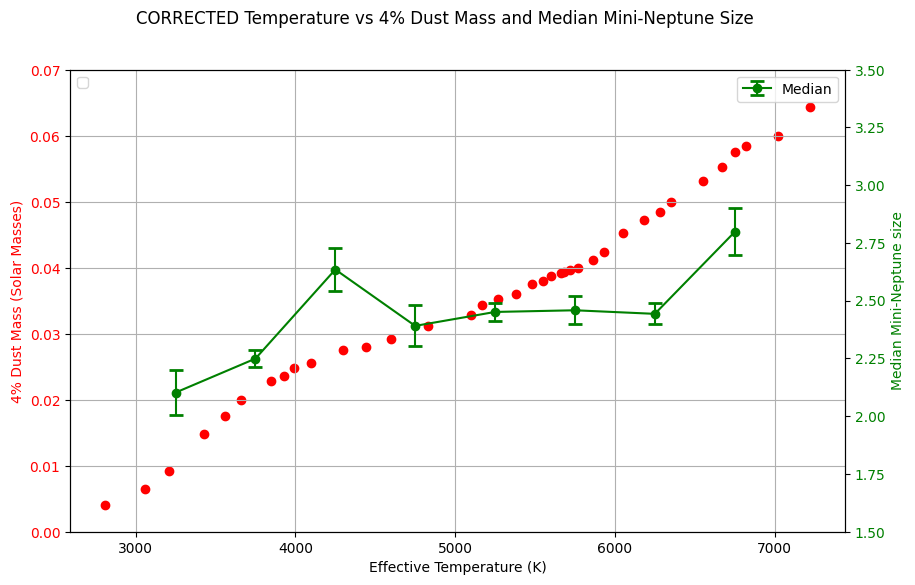

In [19]:
n_bootstrap = 1000
teff_ranges = [(3000, 3500), (3500, 4000), (4000, 4500), (4500, 5000), 
               (5000, 5500), (5500, 6000), (6000, 6500), (6500, 7000)]

# Calculate bootstrapping errors for weighted medians
def calculate_weighted_median(vals, weights):
    """Calculate weighted median"""
    if len(vals) == 0 or weights.sum() == 0:
        return np.nan
    sorted_idx = np.argsort(vals)
    vals_sorted = vals[sorted_idx]
    weights_sorted = weights[sorted_idx]
    cumsum = np.cumsum(weights_sorted)
    cutoff = weights_sorted.sum() / 2.0
    return vals_sorted[np.searchsorted(cumsum, cutoff)]

# Load TOI data for bootstrapping
TOIs_bootstrap = TOIs_filtered
TOIs_bootstrap = TOIs_bootstrap.dropna(subset=['st_teff', 'pl_rade'])
TOIs_bootstrap = TOIs_bootstrap[(TOIs_bootstrap['pl_rade'] > 1.8) & (TOIs_bootstrap['pl_rade'] < 4.0)]
TOIs_bootstrap = TOIs_bootstrap[(TOIs_bootstrap['pl_orbper'] > 0.6028) & (TOIs_bootstrap['pl_orbper'] < 25.1)]
#TOIs_bootstrap = TOIs_bootstrap[TOIs_bootstrap['tfopwg_disp'] == 'FP']


print(len(TOIs_bootstrap), "TOIs for bootstrapping")
if 'tfopwg_disp' in TOIs_bootstrap.columns:
    TOIs_bootstrap = TOIs_bootstrap[TOIs_bootstrap['tfopwg_disp'] != 'FP']

# Calculate weighted median errors using bootstrapping
#print(teff_ranges)
weighted_median_errors = []
for temp_range in teff_ranges:
    teff_df = merged_df[(merged_df['st_teff'] >= temp_range[0]) & (merged_df['st_teff'] < temp_range[1])]
    
    # Get original data for this temperature bin
    bin_mask = (TOIs_bootstrap['st_teff'] >= temp_range[0]) & (TOIs_bootstrap['st_teff'] < temp_range[1])
    toi_indices = TOIs_bootstrap.loc[bin_mask].index
    n_tois = len(toi_indices)
    
    if n_tois == 0:
        weighted_median_errors.append(np.nan)
        continue
    
    # Bootstrap resampling
    bootstrap_medians = []
    for _ in range(n_bootstrap):
        # Resample TOI indices with replacement
        bootstrap_indices = np.random.choice(toi_indices, size=n_tois, replace=True)
        
        # Get corresponding rows from merged_df for these TOIs
        bootstrap_teff_df = merged_df[merged_df['toi'].isin(TOIs_bootstrap.loc[bootstrap_indices, 'toi'])]
        bootstrap_teff_df = bootstrap_teff_df[(bootstrap_teff_df['st_teff'] >= temp_range[0]) & 
                                               (bootstrap_teff_df['st_teff'] < temp_range[1])]
         
        if len(bootstrap_teff_df) > 0:
            vals = bootstrap_teff_df['pl_rade'].values
            weights = bootstrap_teff_df['weight'].values
            bootstrap_median = calculate_weighted_median(vals, weights)
            bootstrap_medians.append(bootstrap_median)
    
    median_error = np.std(bootstrap_medians)
    weighted_median_errors.append(median_error)
    #print(weighted_median_errors)
    #print(f"Teff {temp_range[0]}-{temp_range[1]} K: N={n_tois}, Error={median_error:.3f} R_Earth")

# Add errors to radius_medians dataframe
radius_medians['Weighted Median Error (Earth Radii)'] = weighted_median_errors
print(radius_medians)
#print(radius_medians)

fig, ax1 = plt.subplots(figsize=(10, 6))



median_df = radius_medians#
#print(median_df)

median_df['Teff Range Average'] = median_df['Teff Range'].apply(
    lambda x: sum(map(int, x.replace('K', '').split('-'))) / 2
)

corrected_mean_median_df = median_df
# corrected_mean_median_df['Teff Range Average'] = corrected_mean_median_df['Teff Range'].apply(
#     lambda x: sum(map(int, x.replace('K', '').split('-'))) / 2
# )

# Create a secondary y-axis for Median
ax2 = ax1.twinx()
ax2.errorbar(corrected_mean_median_df['Teff Range Average'], 
             corrected_mean_median_df['Weighted Median Radius (Earth Radii)'], 
             yerr=corrected_mean_median_df['Weighted Median Error (Earth Radii)'],
             color='g', label='Median', marker='o', linestyle='-', capsize=5, capthick=2)
ax2.set_ylabel('Median Mini-Neptune size', color='g')
ax2.tick_params(axis='y', labelcolor='g')
ax2.set_ylim(1.5,3.50)

# Add a title and legend
fig.suptitle('CORRECTED Temperature vs 4% Dust Mass and Median Mini-Neptune Size')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')





data = {
    'Stellar Type': ['M0V', 'M1V', 'M2V', 'M3V', 'M4V', 'M5V', 'M6V', 'K0V', 'K1V', 'K2V', 'K3V', 'K4V', 'K5V', 'K6V', 'K7V', 'K8V', 'K9V',
                     'G0V', 'G1V', 'G2V', 'G3V', 'G4V', 'G5V', 'G6V', 'G7V', 'G8V', 'G9V',
                     'F0V', 'F1V', 'F2V', 'F3V', 'F4V', 'F5V', 'F6V', 'F7V', 'F8V', 'F9V'],
    'Mass': [0.57, 0.50, 0.44, 0.37, 0.23, 0.162, 0.102, 0.88, 0.86, 0.82, 0.78, 0.73, 0.70, 0.69, 0.64, 0.62, 0.59,
             1.06, 1.03, 1.00, 0.99, 0.985, 0.98, 0.97, 0.95, 0.94, 0.90,
             1.61, 1.50, 1.46, 1.44, 1.38, 1.33, 1.25, 1.21, 1.18, 1.13],
    'Radius': [0.588, 0.501, 0.446, 0.361, 0.274, 0.196, 0.137, 0.813, 0.797, 0.783, 0.755, 0.713, 0.701, 0.669, 0.630, 0.615, 0.608,
               1.100, 1.060, 1.012, 1.002, 0.991, 0.977, 0.949, 0.927, 0.914, 0.853,
               1.728, 1.679, 1.622, 1.578, 1.533, 1.473, 1.359, 1.324, 1.221, 1.167],
    'Luminosity': [0.069, 0.041, 0.029, 0.016, 7.2e-3, 3.0e-3, 1.0e-3, 0.46, 0.41, 0.37, 0.28, 0.20, 0.17, 0.14, 0.10, 0.087, 0.079,
                   1.35, 1.20, 1.02, 0.98, 0.91, 0.89, 0.79, 0.74, 0.68, 0.55,
                   7.24, 6.17, 5.13, 4.68, 4.17, 3.63, 2.69, 2.45, 1.95, 1.66],
    'Effective Temperature': [3850, 3660, 3560, 3430, 3210, 3060, 2810, 5270, 5170, 5100, 4830, 4600, 4440, 4300, 4100, 3990, 3930,
                              5930, 5860, 5770, 5720, 5680, 5660, 5600, 5550, 5480, 5380,
                              7220, 7020, 6820, 6750, 6670, 6550, 6350, 6280, 6180, 6050],
    'B-V Index': [1.42, 1.49, 1.51, 1.53, 1.65, 1.83, 2.01, 0.82, 0.86, 0.88, 0.99, 1.09, 1.15, 1.24, 1.34, 1.36, 1.40,
                  0.60, 0.62, 0.65, 0.66, 0.67, 0.68, 0.70, 0.71, 0.73, 0.78,
                  0.30, 0.33, 0.37, 0.39, 0.41, 0.44, 0.49, 0.50, 0.53, 0.56]
}
data['4% Dust Mass'] = [mass * 0.04 for mass in data['Mass']]
data['1/R^2'] = [1 / (radius ** 2) for radius in data['Radius']]

stellar_df = pd.DataFrame(data)
stellar_df = stellar_df.sort_values(by='Effective Temperature', ascending=True)



# Plot 4% Dust Mass on the primary y-axis
ax1.scatter(stellar_df['Effective Temperature'], stellar_df['4% Dust Mass'], color='r', label='4% Dust Mass')
ax1.set_xlabel('Effective Temperature (K)')
ax1.set_ylabel('4% Dust Mass (Solar Masses)', color='r')
ax1.tick_params(axis='y', labelcolor='r')
ax1.grid(True)
ax1.set_ylim(-.00,.07)
#ax1.set_ylim(-.01,.0)



687
Teff 3000-3500 K: N=41, Median=2.22, Error=0.166 R_Earth
Teff 3500-4000 K: N=80, Median=2.25, Error=0.042 R_Earth
Teff 4000-4500 K: N=75, Median=2.71, Error=0.077 R_Earth
Teff 4500-5000 K: N=85, Median=2.62, Error=0.084 R_Earth
Teff 5000-5500 K: N=121, Median=2.68, Error=0.060 R_Earth
Teff 5500-6000 K: N=168, Median=2.67, Error=0.053 R_Earth
Teff 6000-6500 K: N=99, Median=2.67, Error=0.098 R_Earth
Teff 6500-7000 K: N=18, Median=2.89, Error=0.140 R_Earth

Total bins: 8, 8, 8
Uncorrected Bin centers: [3250.0, 3750.0, 4250.0, 4750.0, 5250.0, 5750.0, 6250.0, 6750.0], Medians: [2.2168828, 2.2532166, 2.70505, 2.62025, 2.6757659, 2.668915, 2.67352, 2.8943008], Errors: [0.1657559716423926, 0.04236967499416488, 0.0767679664963423, 0.08378774796015857, 0.060426504367905656, 0.053202516235682555, 0.0983445053763993, 0.13956808412478244]


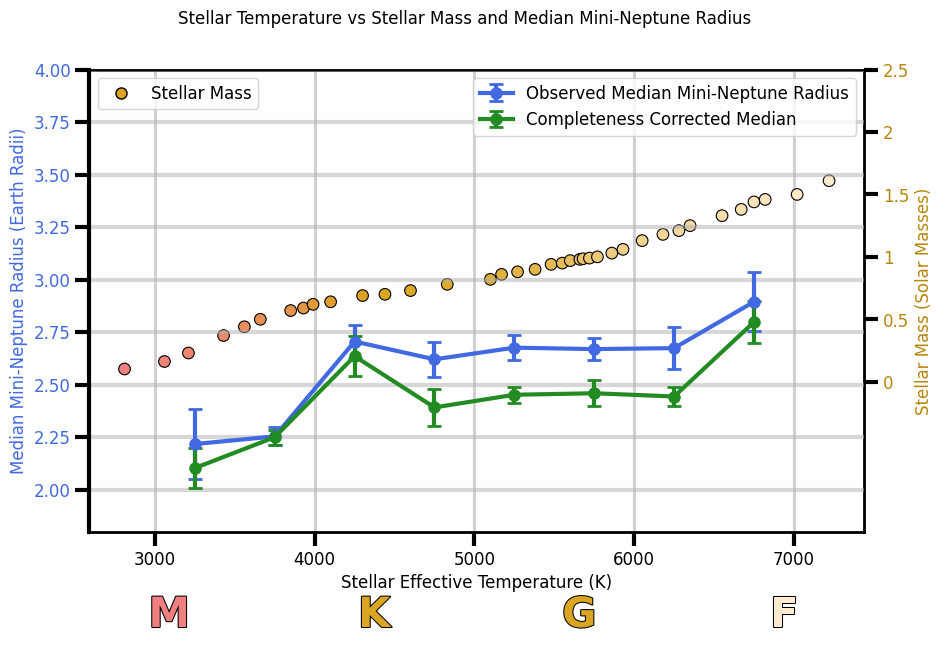

In [20]:
#### PRESENTATION VERSION ####

# Bootstrap error calculation
n_bootstrap = 1000

# Load TOI data for bootstrapping
TOIs = pd.read_csv('../TOI_Mar2025_1pt5to4_R_detected_real_only.csv')
TOIs = TOIs.dropna(subset=['st_teff', 'pl_rade'])
TOIs = TOIs[(TOIs['pl_rade'] > 1.8) & (TOIs['pl_rade'] < 4.0)]
TOIs = TOIs[(TOIs['pl_orbper'] > 0.6028) & (TOIs['pl_orbper'] < 25.1)]
if 'tfopwg_disp' in TOIs.columns:
    TOIs = TOIs[TOIs['tfopwg_disp'] != 'FP']
print(len(TOIs))

# Define temperature bins matching mean_median_df
bins_teff = [3000, 3500, 4000, 4500, 5000, 5500, 6000, 6500, 7000]

planet_radii_medians = []
planet_radii_errors = []
bin_centers = []

for i in range(len(bins_teff)-1):
    bin_mask = (TOIs['st_teff'] >= bins_teff[i]) & (TOIs['st_teff'] < bins_teff[i+1])
    planet_radii = TOIs.loc[bin_mask, 'pl_rade']
    planet_radii_n = len(planet_radii)
    
    if planet_radii_n == 0:
        planet_radii_errors.append(np.nan)
        planet_radii_medians.append(np.nan)
        bin_centers.append((bins_teff[i] + bins_teff[i+1]) / 2)
        continue
    
    # Bootstrap resampling
    bootstrap_medians = []
    for _ in range(n_bootstrap):
        bootstrap_sample = planet_radii.sample(n=planet_radii_n, replace=True)
        bootstrap_medians.append(np.median(bootstrap_sample))
    
    planet_radii_error = np.std(bootstrap_medians)
    planet_radii_median = np.median(planet_radii)
    
    print(f"Teff {bins_teff[i]}-{bins_teff[i+1]} K: N={planet_radii_n}, Median={planet_radii_median:.2f}, Error={planet_radii_error:.3f} R_Earth")
    
    planet_radii_medians.append(planet_radii_median)
    planet_radii_errors.append(planet_radii_error)
    bin_centers.append((bins_teff[i] + bins_teff[i+1]) / 2)

print(f"\nTotal bins: {len(planet_radii_medians)}, {len(planet_radii_errors)}, {len(bin_centers)}")

# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

import matplotlib.colors as mcolors

# Gradual color transition for scatter points
n_points = len(stellar_df)
colors = []
for i in range(n_points):
    ratio = i / (n_points - 1)
    if ratio <= 0.3:
        local_ratio = ratio / 0.3
        r = 240 + (218 - 240) * local_ratio
        g = 128 + (165 - 128) * local_ratio
        b = 128 + (32 - 128) * local_ratio
    else:
        local_ratio = (ratio - 0.3) / 0.7
        r = 218 + (255 - 218) * local_ratio
        g = 165 + (235 - 165) * local_ratio
        b = 32 + (205 - 32) * local_ratio
    colors.append((r/255, g/255, b/255))

from matplotlib.lines import Line2D


legend_elements = [Line2D([0], [0], marker='o', color='w', label='Stellar Mass',
                          markerfacecolor='goldenrod', markeredgecolor='black', markersize=8, linewidth=.1)]
ax1.scatter(stellar_df['Effective Temperature'], stellar_df['Mass'], 
           c=colors, edgecolor='black', linewidth=0.8, s=70, zorder = 3)
ax1.set_xlabel('Stellar Effective Temperature (K)', size=12)
ax1.set_ylabel('Stellar Mass (Solar Masses)', color='darkgoldenrod', size=12)
ax1.tick_params(axis='y', labelcolor='darkgoldenrod')
ax1.set_ylim(-1.2,2.5)
# Show only positive y-ticks on the stellar-mass axis
ax1.set_yticks([t for t in ax1.get_yticks() if t >= 0])
ax1.set_yticklabels([f"{t:g}" for t in ax1.get_yticks() if t >= 0])

# Secondary y-axis for Median with error bars
ax2 = ax1.twinx()
# Force vertical grid lines from the shared x-axis
ax1.grid(True, axis='x', which='major', linewidth=2.2, alpha=0.6, color='0.7')
ax1.xaxis.grid(True, which='major', linewidth=2.2, alpha=0.6, color='0.7')
# Keep horizontal grid lines on the radius axis
ax2.grid(True, axis='y', which='major', linewidth=3, alpha=.5)
ax2.set_axisbelow(True)

# Add individual planet radii as grey transparent dots
#ax2.scatter(TOIs['st_teff'], TOIs['pl_rade'], 
#           color='grey', alpha=0.25, s=20, zorder=1, label='Individual Planets')

print(f"Uncorrected Bin centers: {bin_centers}, Medians: {planet_radii_medians}, Errors: {planet_radii_errors}")

ax2.errorbar(
    bin_centers, planet_radii_medians, yerr=planet_radii_errors,
    color='royalblue', label='Observed Median Mini-Neptune Radius', marker='o', 
    linestyle='-', markersize=8, linewidth=3, capsize=5, capthick=2, zorder=3
)
ax2.set_ylabel('Median Mini-Neptune Radius (Earth Radii)', color='royalblue', size=12)
ax2.tick_params(axis='y', labelcolor='royalblue', size=12)
ax2.set_ylim(1.8, 4.0)

# Add completeness-corrected medians (green) in the same style
if 'corrected_mean_median_df' in globals():
    ax2.errorbar(
        corrected_mean_median_df['Teff Range Average'],
        corrected_mean_median_df['Weighted Median Radius (Earth Radii)'],
        yerr=corrected_mean_median_df['Weighted Median Error (Earth Radii)'],
        color='forestgreen', label='Completeness Corrected Median',
        marker='o', linestyle='-', markersize=8, linewidth=3,
        capsize=5, capthick=2, zorder=3
    )

# Flip y-axis positions: stellar mass axis to right, radius axis to left
ax1.yaxis.set_label_position('right')
ax1.yaxis.tick_right()
ax1.spines['right'].set_visible(True)
ax1.spines['left'].set_visible(False)

ax2.yaxis.set_label_position('left')
ax2.yaxis.tick_left()
ax2.spines['left'].set_position(('outward', 0))
ax2.spines['left'].set_visible(True)
ax2.spines['right'].set_visible(False)

fig.suptitle('Stellar Temperature vs Stellar Mass and Median Mini-Neptune Radius', size=12)
ax1.legend(handles=legend_elements, loc='upper left', fontsize=12)
ax2.legend(loc='upper right', fontsize=12)
ax1.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
ax1.tick_params(axis='both', which='minor', width=2, length=6, labelsize=12)
ax2.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
ax2.tick_params(axis='both', which='minor', width=2, length=6, labelsize=12)
for spine in ax1.spines.values():
    spine.set_linewidth(2)
ax2.spines['left'].set_linewidth(3)
plt.show()


fig.savefig('stellar_temp_vs_disk_mass_and_median_radius.png', dpi=300, bbox_inches='tight')

--- Slopes of Corrected Median Line ---
Slope between 1st & 3rd points (Stellar Mass ~0.38 to 0.68): 1.437
Slope between 3rd & 7th points (Stellar Mass ~0.68 to 1.27): -0.203
Slope between 7th & 8th points (Stellar Mass ~1.27 to 1.43): 2.498


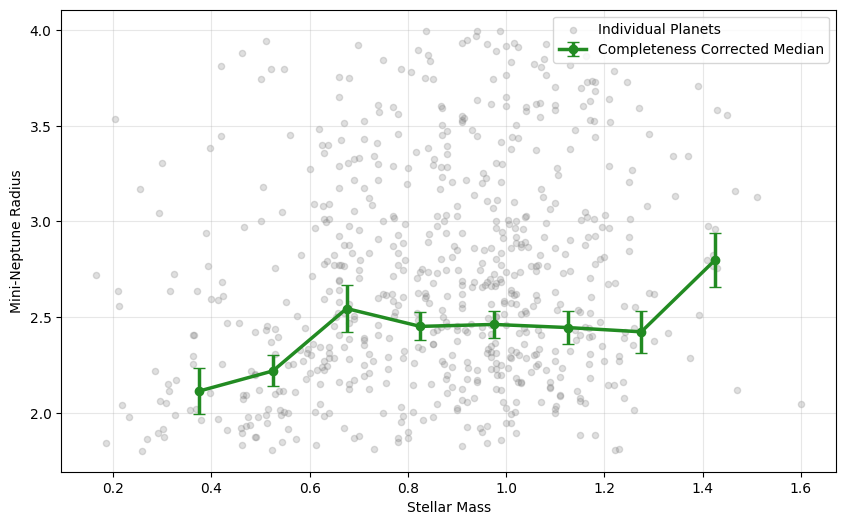

In [21]:

# Prepare TOI table with mass
TOIs_mass = TOIs.copy()
if 'mst' not in TOIs_mass.columns and 'st_mass' not in TOIs_mass.columns:
    TOIs_mass = pd.read_csv('../TOI_Mar2025_1pt5to4_R_detected_real_only.csv')

mass_col = 'mst' if 'mst' in TOIs_mass.columns else 'st_mass'

TOIs_mass = TOIs_mass.dropna(subset=['st_teff', 'pl_rade', mass_col])
TOIs_mass = TOIs_mass[(TOIs_mass['pl_rade'] > 1.8) & (TOIs_mass['pl_rade'] < 4.0)]
TOIs_mass = TOIs_mass[(TOIs_mass['pl_orbper'] > 0.6028) & (TOIs_mass['pl_orbper'] < 25.1)]
if 'tfopwg_disp' in TOIs_mass.columns:
    TOIs_mass = TOIs_mass[TOIs_mass['tfopwg_disp'] != 'FP']

# Build 8 mass bins (same count as temperature bins)
n_bins = len(bins_teff) - 1
mass_edges = np.linspace(0.3, 1.5, n_bins + 1)
if len(mass_edges) < 3:
    mass_edges = np.linspace(TOIs_mass[mass_col].min(), TOIs_mass[mass_col].max(), n_bins + 1)

def weighted_median(vals, weights):
    vals = np.asarray(vals)
    weights = np.asarray(weights)
    if len(vals) == 0 or np.nansum(weights) <= 0:
        return np.nan
    s = np.argsort(vals)
    vals_s = vals[s]
    w_s = weights[s]
    cdf = np.cumsum(w_s)
    return vals_s[np.searchsorted(cdf, 0.5 * cdf[-1])]

# Observed medians + bootstrap errors (unweighted)
obs_centers, obs_medians, obs_errs = [], [], []
for i in range(len(mass_edges) - 1):
    lo, hi = mass_edges[i], mass_edges[i + 1]
    m = TOIs_mass[(TOIs_mass[mass_col] >= lo) & (TOIs_mass[mass_col] < hi)]
    vals = m['pl_rade'].values
    obs_centers.append(0.5 * (lo + hi))
    if len(vals) == 0:
        obs_medians.append(np.nan)
        obs_errs.append(np.nan)
        continue
    obs_medians.append(np.median(vals))
    boot = [np.median(np.random.choice(vals, size=len(vals), replace=True)) for _ in range(n_bootstrap)]
    obs_errs.append(np.std(boot))

# Corrected medians + bootstrap errors (weighted)
mass_map = TOIs_mass[['toi', mass_col]].drop_duplicates(subset='toi')
merged_mass = merged_df.merge(mass_map, on='toi', how='left').dropna(subset=[mass_col, 'pl_rade', 'weight'])

cor_centers, cor_medians, cor_errs = [], [], []
for i in range(len(mass_edges) - 1):
    lo, hi = mass_edges[i], mass_edges[i + 1]
    m = merged_mass[(merged_mass[mass_col] >= lo) & (merged_mass[mass_col] < hi)]
    vals = m['pl_rade'].values
    w = m['weight'].values
    cor_centers.append(0.5 * (lo + hi))
    if len(vals) == 0 or np.nansum(w) <= 0:
        cor_medians.append(np.nan)
        cor_errs.append(np.nan)
        continue
    cor_medians.append(weighted_median(vals, w))
    idx = np.arange(len(vals))
    boot = []
    for _ in range(n_bootstrap):
        bidx = np.random.choice(idx, size=len(idx), replace=True)
        boot.append(weighted_median(vals[bidx], w[bidx]))
    cor_errs.append(np.nanstd(boot))

# Plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, alpha=0.3)

ax.scatter(TOIs_mass[mass_col], TOIs_mass['pl_rade'],
           color='grey', alpha=0.25, s=20, label='Individual Planets')


ax.errorbar(cor_centers, cor_medians, yerr=cor_errs,
            color='forestgreen', marker='o', linestyle='-',
            linewidth=2.5, capsize=4, label='Completeness Corrected Median')

# Calculate slopes for specific segments of the green line (Completeness Corrected Median)
slope1_3 = (cor_medians[2] - cor_medians[0]) / (cor_centers[2] - cor_centers[0])
slope3_7 = (cor_medians[6] - cor_medians[2]) / (cor_centers[6] - cor_centers[2])
slope7_8 = (cor_medians[7] - cor_medians[6]) / (cor_centers[7] - cor_centers[6])

print("--- Slopes of Corrected Median Line ---")
print(f"Slope between 1st & 3rd points (Stellar Mass ~{cor_centers[0]:.2f} to {cor_centers[2]:.2f}): {slope1_3:.3f}")
print(f"Slope between 3rd & 7th points (Stellar Mass ~{cor_centers[2]:.2f} to {cor_centers[6]:.2f}): {slope3_7:.3f}")
print(f"Slope between 7th & 8th points (Stellar Mass ~{cor_centers[6]:.2f} to {cor_centers[7]:.2f}): {slope7_8:.3f}")

ax.set_xlabel('Stellar Mass')
ax.set_ylabel('Mini-Neptune Radius')
ax.legend()
plt.show()

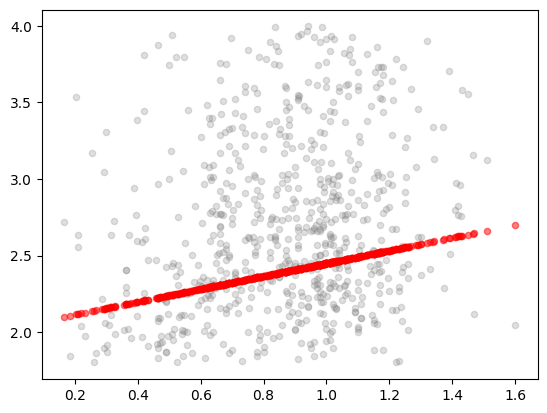

In [22]:
plt.scatter(TOIs_mass[mass_col], TOIs_mass['pl_rade'], color='grey', alpha=0.25, s=20, label='Individual Planets')

x_sorted = TOIs_mass[mass_col].sort_values().values

lower_bound = 2.1
upper_bound = 2.7

# Linear interpolation: y goes from lower_bound to upper_bound
# as x goes from x_sorted.min() to x_sorted.max()
x_min, x_max = x_sorted.min(), x_sorted.max()
straight_line = lower_bound + (x_sorted - x_min) / (x_max - x_min) * (upper_bound - lower_bound)

plt.scatter(x_sorted, straight_line, color='red', alpha=0.5, s=20, label='Reference Line (y=1)')

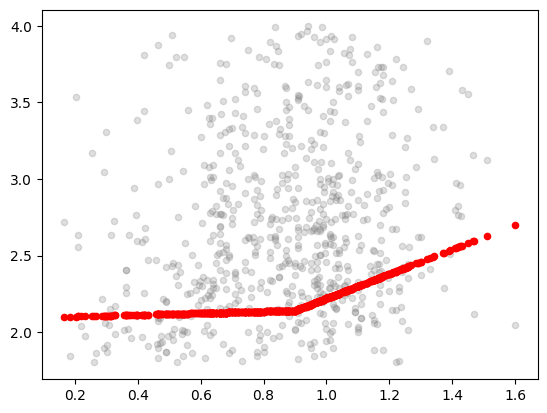

In [23]:
plt.scatter(TOIs_mass[mass_col], TOIs_mass['pl_rade'], color='grey', alpha=0.25, s=20, label='Individual Planets')


x = np.sort(TOIs_mass[mass_col].values)

x0 = x.min()
x1 = .9
x2 = x.max()

y0 = 2.1
y2 = 2.7

slope2 = 0.8   # choose this

# Solve for slope1 so the line ends at y2
slope1 = (y2 - y0 - slope2 * (x2 - x1)) / (x1 - x0)

y = np.empty_like(x)

mask = x <= x1
y[mask] = y0 + slope1 * (x[mask] - x0)

y_break = y0 + slope1 * (x1 - x0)

y[~mask] = y_break + slope2 * (x[~mask] - x1)

plt.scatter(x, y, color='red', s=20, label='Fitted Line')

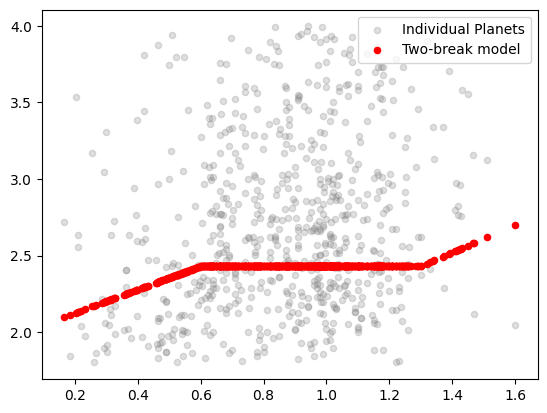

In [24]:
plt.scatter(TOIs_mass[mass_col], TOIs_mass['pl_rade'], color='grey', alpha=0.25, s=20, label='Individual Planets')

x = np.sort(TOIs_mass[mass_col].values)

# Endpoints
x0 = x.min()
x3 = x.max()

y0 = 2.1
y3 = 2.7

# Break locations
x1 = 0.6
x2 = 1.3

# Choose these slopes
slope2 = 0
slope3 = 0.90

# Solve for slope1 so the line ends at y3
slope1 = (
    y3 - y0
    - slope2 * (x2 - x1)
    - slope3 * (x3 - x2)
) / (x1 - x0)

# Build the piecewise line
y = np.empty_like(x)

mask1 = x <= x1
mask2 = (x > x1) & (x <= x2)
mask3 = x > x2

# First segment
y[mask1] = y0 + slope1 * (x[mask1] - x0)

# Value at first break
y1 = y0 + slope1 * (x1 - x0)

# Second segment
y[mask2] = y1 + slope2 * (x[mask2] - x1)

# Value at second break
y2 = y1 + slope2 * (x2 - x1)

# Third segment
y[mask3] = y2 + slope3 * (x[mask3] - x2)

plt.scatter(x, y, color='red', s=20, label='Two-break model')
plt.legend()

N data points: 677

Model                 chi2     p-value   dof    reduced chi2
Straight ramp       75.638           1   675          0.1121
One-break           75.207           1   674          0.1116
Two-break           75.416           1   673          0.1121


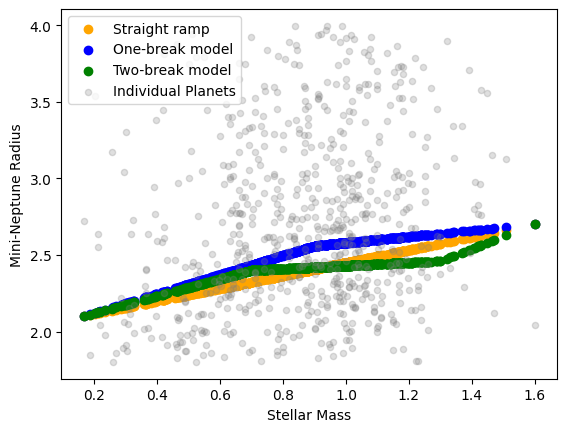

In [25]:
# Compare the three model fits (straight ramp, one-break, two-break) to the data
# via scipy.stats.chisquare. Each model predicts a mini-Neptune radius as a function
# of stellar mass; we evaluate it at every observed mass and compare to pl_rade.
from scipy.stats import chisquare

# Observed data (align mass and radius on the same rows, drop any NaNs)
_fit = TOIs_mass[[mass_col, 'pl_rade']].dropna()
x_obs = _fit[mass_col].values
y_obs = _fit['pl_rade'].values
x_min, x_max = x_obs.min(), x_obs.max()

# --- Model A: single straight ramp (cell 52387c8d) ---
def model_straight(x):
    lower_bound, upper_bound = 2.1, 2.7
    return lower_bound + (x - x_min) / (x_max - x_min) * (upper_bound - lower_bound)

# --- Model B: one-break piecewise line (cell 91092e8c) ---
def model_one_break(x):
    x0, x1, x2 = x_min, 0.9, x_max
    y0, y2 = 2.1, 2.7
    slope2 = 0.2
    slope1 = (y2 - y0 - slope2 * (x2 - x1)) / (x1 - x0)
    y_break = y0 + slope1 * (x1 - x0)
    return np.where(x <= x1, y0 + slope1 * (x - x0), y_break + slope2 * (x - x1))

# --- Model C: two-break piecewise line (cell 83175ba8) ---
def model_two_break(x):
    x0, x3 = x_min, x_max
    y0, y3 = 2.1, 2.7
    x1, x2 = 0.7, 1.3
    slope2, slope3 = 0.1, 0.80
    slope1 = (y3 - y0 - slope2 * (x2 - x1) - slope3 * (x3 - x2)) / (x1 - x0)
    y1 = y0 + slope1 * (x1 - x0)
    y2 = y1 + slope2 * (x2 - x1)
    return np.select(
        [x <= x1, (x > x1) & (x <= x2), x > x2],
        [y0 + slope1 * (x - x0), y1 + slope2 * (x - x1), y2 + slope3 * (x - x2)]
    )

# Number of free parameters per model (for reduced chi-square / dof bookkeeping)
models = {
    'Straight ramp':  (model_straight,  2),   # y0, y1
    'One-break':      (model_one_break, 3),   # y0, y2, slope2
    'Two-break':      (model_two_break, 4),   # y0, y3, slope2, slope3
}

print(f"N data points: {len(y_obs)}\n")
print(f"{'Model':<14}{'chi2':>12}{'p-value':>12}{'dof':>6}{'reduced chi2':>16}")

for name, (func, n_params) in models.items():
    y_exp = func(x_obs)
    # scipy.chisquare requires sum(f_exp) == sum(f_obs); rescale expected to the
    # observed total so the statistic reflects the shape mismatch, not a normalization offset.
    y_exp_scaled = y_exp * (y_obs.sum() / y_exp.sum())
    chi2, p = chisquare(f_obs=y_obs, f_exp=y_exp_scaled)
    dof = len(y_obs) - n_params
    print(f"{name:<14}{chi2:>12.3f}{p:>12.3g}{dof:>6}{chi2/dof:>16.4f}")

#print("\nLower chi2 / reduced chi2 => better fit to the data.")

plt.scatter(x_obs, model_straight(x_obs), color='orange', label='Straight ramp')
plt.scatter(x_obs, model_one_break(x_obs), color='blue', label='One-break model')
plt.scatter(x_obs, model_two_break(x_obs), color='green', label='Two-break model')
plt.scatter(x_obs, y_obs, color='grey', alpha=0.25, s=20, label='Individual Planets')
plt.xlabel('Stellar Mass')
plt.ylabel('Mini-Neptune Radius')
plt.legend()    

In [26]:
# Completeness-weighted chi-square (injection/recovery weights).
# Each detected planet's `weight` (= detection_inverse * transit_inverse) says how many
# planets it represents in the true population, so it MULTIPLIES its squared residual.
# scipy.chisquare can't take weights, so we form the weighted statistic by hand.
# Reuses model_straight / model_one_break / model_two_break and the `models` dict above.

# Pull the inj/rec weight onto each TOI by matching on `toi` (merged_df has one row per TOI)
_wt = merged_df[['toi', 'weight']].drop_duplicates(subset='toi')
_w = TOIs_mass[[mass_col, 'pl_rade', 'toi']].merge(_wt, on='toi', how='left')
_w = _w.dropna(subset=[mass_col, 'pl_rade', 'weight'])
_w = _w[_w['weight'] > 0]

xw = _w[mass_col].values
yw = _w['pl_rade'].values
w  = _w['weight'].values

print(f"N data points (with valid weight): {len(yw)}")
print(f"Sum of weights (effective population size): {w.sum():.1f}\n")
print(f"{'Model':<14}{'weighted chi2':>16}{'dof':>6}{'reduced chi2':>16}")
print("-" * 52)

for name, (func, n_params) in models.items():
    y_exp = func(xw)
    chi2_w = np.sum(w * (yw - y_exp) ** 2)   # completeness-weighted sum of squared residuals
    dof = len(yw) - n_params
    print(f"{name:<14}{chi2_w:>16.3f}{dof:>6}{chi2_w/dof:>16.4f}")

print("\nLower weighted chi2 => model better matches the completeness-corrected population.")
print("(inj/rec weights are importance weights, so this is a weighted sum of squared")
print(" residuals for ranking models, not calibrated to the chi-square distribution -> no p-value.)")


N data points (with valid weight): 666
Sum of weights (effective population size): 23989.7

Model            weighted chi2   dof    reduced chi2
----------------------------------------------------
Straight ramp         6696.615   664         10.0853
One-break             6226.128   663          9.3908
Two-break             6592.319   662          9.9582

Lower weighted chi2 => model better matches the completeness-corrected population.
(inj/rec weights are importance weights, so this is a weighted sum of squared
 residuals for ranking models, not calibrated to the chi-square distribution -> no p-value.)


N bins (with valid median/error): 8

Model                 chi2     p-value   dof    reduced chi2
------------------------------------------------------------
Straight ramp        8.731       0.189     6          1.4552
One-break           14.777      0.0114     5          2.9554
Two-break            6.878       0.143     4          1.7194

Lower reduced chi2 / higher p-value => model better matches the binned
completeness-corrected medians.


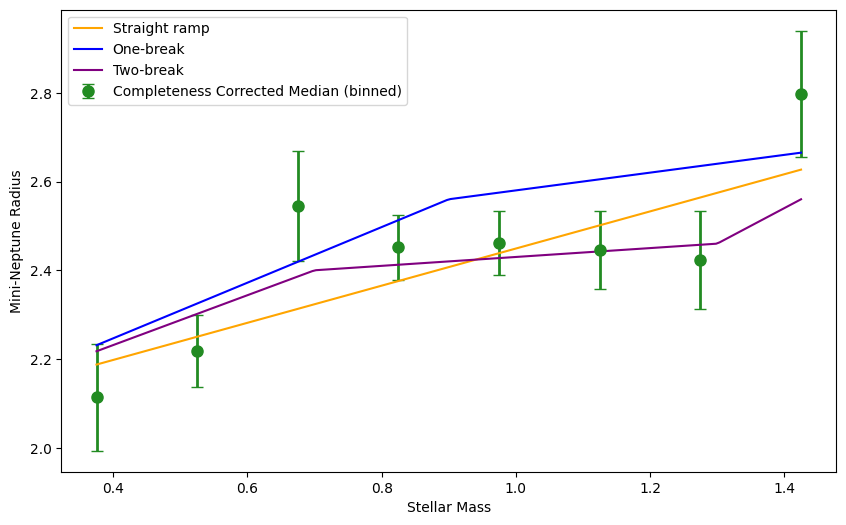

In [27]:
# Chi-square fits to the BINNED data (the 8 mass-bin medians from cell 178beddb),
# rather than to every individual TOI. Each bin has a real uncertainty (cor_errs,
# from bootstrap resampling of the weighted median), so this is a proper
# chi2 = sum(((y_obs - y_model) / sigma)^2) with a calibrated p-value -- unlike the
# per-planet weighted sum in the previous cell, which isn't on the chi-square scale.
from scipy.stats import chi2 as chi2_dist

cor_centers_arr = np.array(cor_centers)
cor_medians_arr = np.array(cor_medians)
cor_errs_arr = np.array(cor_errs)

# Drop any empty bins (nan median/error)
_valid = ~(np.isnan(cor_medians_arr) | np.isnan(cor_errs_arr) | (cor_errs_arr == 0))
xb = cor_centers_arr[_valid]
yb = cor_medians_arr[_valid]
eb = cor_errs_arr[_valid]

print(f"N bins (with valid median/error): {len(yb)}\n")
print(f"{'Model':<14}{'chi2':>12}{'p-value':>12}{'dof':>6}{'reduced chi2':>16}")
print("-" * 60)

binned_fit_results = {}
for name, (func, n_params) in models.items():
    y_model = func(xb)
    chi2_val = np.sum(((yb - y_model) / eb) ** 2)
    dof = len(yb) - n_params
    p_val = chi2_dist.sf(chi2_val, dof) if dof > 0 else np.nan
    binned_fit_results[name] = (chi2_val, dof, p_val)
    print(f"{name:<14}{chi2_val:>12.3f}{p_val:>12.3g}{dof:>6}{chi2_val/dof:>16.4f}")

print("\nLower reduced chi2 / higher p-value => model better matches the binned")
print("completeness-corrected medians.")

# Plot the three models against the binned data with error bars
fig, ax = plt.subplots(figsize=(10, 6))
ax.errorbar(xb, yb, yerr=eb, fmt='o', color='forestgreen', capsize=4,
            markersize=8, linewidth=2, label='Completeness Corrected Median (binned)')

x_line = np.linspace(xb.min(), xb.max(), 200)
ax.plot(x_line, model_straight(x_line), color='orange', label='Straight ramp')
ax.plot(x_line, model_one_break(x_line), color='blue', label='One-break')
ax.plot(x_line, model_two_break(x_line), color='purple', label='Two-break')

ax.set_xlabel('Stellar Mass')
ax.set_ylabel('Mini-Neptune Radius')
ax.legend()
plt.show()

Model                 chi2   dof    reduced chi2     p-value
Flat                21.343     7          3.0489     0.00329
Straight ramp        8.516     6          1.4194       0.203
One-break            5.729     4          1.4322        0.22
Two-break            0.935     2          0.4676       0.627


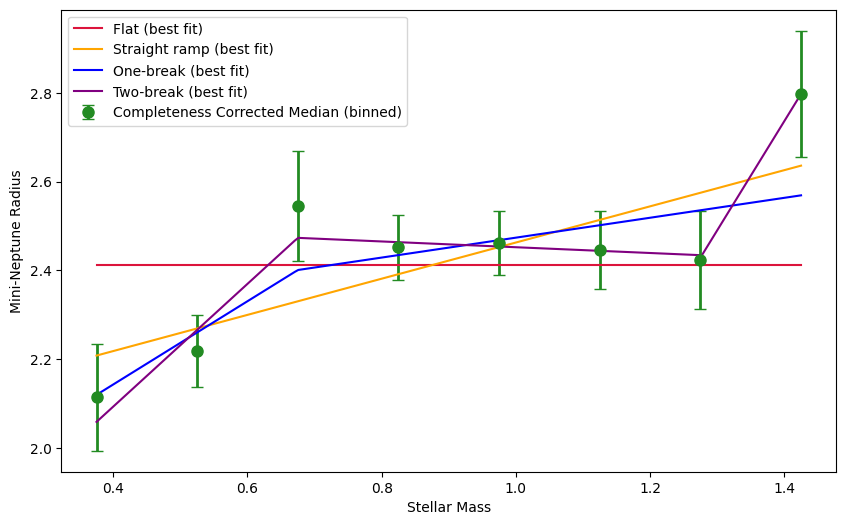

In [28]:
# ===========================================================================
# GOAL
# ---------------------------------------------------------------------------
# The cells above (52387c8d, 91092e8c, 83175ba8) used HAND-PICKED breakpoints
# and slopes for the straight/one-break/two-break lines -- e.g. the one-break
# model always broke at stellar mass = 0.9 and always used slope2 = 0.2,
# whether or not that's actually where the data bends.
#
# This cell instead lets scipy find the best possible version of each shape:
# it searches over breakpoint locations AND slopes to minimize chi-square
# against the binned data (xb, yb, eb from the previous cell). That way when
# we compare "flat vs straight vs one-break vs two-break" later (AIC/BIC cell),
# we're comparing each shape's BEST case, not an arbitrary guess.
#
# The flat (zero-slope) model is the baseline the others have to beat: if it
# survives the comparison, the data don't even require radius to depend on
# stellar mass, never mind to bend.
# ===========================================================================
from scipy.optimize import curve_fit

# x0_fit/x3_fit anchor the piecewise lines to the first/last binned mass point.
# slope_guess is just a straight-line-between-endpoints estimate, used as the
# starting guess (p0) for curve_fit -- it doesn't have to be accurate, curve_fit
# will refine it, it just needs to be in the right ballpark so the optimizer
# doesn't get lost.
x0_fit, x3_fit = xb.min(), xb.max()
slope_guess = (yb[-1] - yb[0]) / (x3_fit - x0_fit)

# --- Flat line: y = y0 (zero slope) ---
# 1 free parameter: the single height that best matches every bin. This is the
# "no trend at all" hypothesis -- mini-Neptune radius independent of stellar
# mass. Every other model below contains it as the special case slope = 0, so
# it sits at the bottom of the same nested ladder.
def fit_flat(x, y0):
    return np.full_like(np.asarray(x, dtype=float), y0)

# --- Straight line: y = y0 + slope*(x - x0) ---
# 2 free parameters: y0 (starting height) and slope.
def fit_straight(x, y0, slope):
    return y0 + slope * (x - x0_fit)

# --- One-break piecewise line: y0 at x0, ONE break at a free location x1 ---
# 4 free parameters: y0, x1 (break location), slope1 (before break), slope2 (after).
# Unlike the hand-picked version above, x1 is no longer fixed at 0.9 -- curve_fit
# decides where the bend actually belongs.
def fit_one_break(x, y0, x1, slope1, slope2):
    y1 = y0 + slope1 * (x1 - x0_fit)   # height of the line right at the break
    return np.where(x <= x1, y0 + slope1 * (x - x0_fit), y1 + slope2 * (x - x1))

# --- Two-break piecewise line: y0 at x0, breaks at free x1 < x2 ---
# 6 free parameters: y0, x1, x2 (both break locations), slope1/slope2/slope3
# (one slope per segment). More flexible than one-break, but also more prone
# to overfitting with only 8 binned points -- that tradeoff gets checked
# properly in the AIC/BIC cell below.
def fit_two_break(x, y0, x1, x2, slope1, slope2, slope3):
    y1 = y0 + slope1 * (x1 - x0_fit)   # height at the first break
    y2 = y1 + slope2 * (x2 - x1)       # height at the second break
    return np.select(
        [x <= x1, (x > x1) & (x <= x2), x > x2],
        [y0 + slope1 * (x - x0_fit), y1 + slope2 * (x - x1), y2 + slope3 * (x - x2)]
    )

# Each entry is (model function, initial guess p0, parameter bounds).
# Bounds keep the break locations (x1, x2) inside the actual data range
# [x0_fit, x3_fit] -- otherwise curve_fit could "solve" the fit by placing a
# break outside the data, which is meaningless. Slopes and y0 are left
# unbounded (-inf, inf) since there's no physical reason to restrict them.
fit_specs = {
    'Flat': (
        fit_flat, [np.median(yb)],
        (-np.inf, np.inf),
    ),
    'Straight ramp': (
        fit_straight, [yb[0], slope_guess],
        (-np.inf, np.inf),
    ),
    'One-break': (
        fit_one_break, [yb[0], 0.5 * (x0_fit + x3_fit), slope_guess, slope_guess],
        ([-np.inf, x0_fit, -np.inf, -np.inf], [np.inf, x3_fit, np.inf, np.inf]),
    ),
    'Two-break': (
        fit_two_break,
        [yb[0], x0_fit + (x3_fit - x0_fit) / 3, x0_fit + 2 * (x3_fit - x0_fit) / 3, slope_guess, slope_guess, slope_guess],
        ([-np.inf, x0_fit, x0_fit, -np.inf, -np.inf, -np.inf], [np.inf, x3_fit, x3_fit, np.inf, np.inf, np.inf]),
    ),
}
best_fit_results = {}
print(f"{'Model':<14}{'chi2':>12}{'dof':>6}{'reduced chi2':>16}{'p-value':>12}")

for name, (func, p0, bounds) in fit_specs.items():
    # curve_fit does the actual optimization: it searches parameter space to
    # minimize sum(((yb - func(xb, *params)) / eb)**2) -- i.e. weighted
    # least-squares, same statistic as chi-square. sigma=eb weights each bin
    # by its bootstrap uncertainty (see the earlier "where are the weights"
    # question -- same mechanism as before, just now driving an optimizer
    # instead of evaluating a fixed model). absolute_sigma=True tells it eb
    # is a real physical uncertainty (not just a relative weight), which
    # matters for how pcov (the parameter covariance matrix) gets scaled.
    # We don't use pcov here, but it's what you'd read parameter uncertainties
    # off of if you wanted error bars on the fitted slopes/breakpoints.
    popt, pcov = curve_fit(func, xb, yb, p0=p0, sigma=eb, absolute_sigma=False, bounds=bounds)

    # Re-evaluate chi-square at the best-fit parameters (popt) -- same formula
    # as the hand-picked-model cell above, just with the OPTIMIZED parameters
    # plugged in instead of guessed ones.
    y_model = func(xb, *popt)
    chi2_val = np.sum(((yb - y_model) / eb) ** 2)
    dof = len(yb) - len(popt)   # degrees of freedom = data points minus fitted parameters
    p_val = chi2_dist.sf(chi2_val, dof) if dof > 0 else np.nan
    best_fit_results[name] = {'popt': popt, 'chi2': chi2_val, 'dof': dof, 'p': p_val}
    print(f"{name:<14}{chi2_val:>12.3f}{dof:>6}{chi2_val/dof:>16.4f}{p_val:>12.3g}")

# print("\nBest-fit parameters:")
# for name, res in best_fit_results.items():
#     print(f"  {name}: {np.round(res['popt'], 3)}")

# Plot the binned data with each best-fit curve overlaid, so you can eyeball
# how much (or little) each shape actually bends once it's allowed to fit freely.
fig, ax = plt.subplots(figsize=(10, 6))
ax.errorbar(xb, yb, yerr=eb, fmt='o', color='forestgreen', capsize=4,
            markersize=8, linewidth=2, label='Completeness Corrected Median (binned)')

x_line = np.linspace(x0_fit, x3_fit, 200)
colors = {'Flat': 'crimson', 'Straight ramp': 'orange', 'One-break': 'blue', 'Two-break': 'purple'}
for name, (func, _, _) in fit_specs.items():
    ax.plot(x_line, func(x_line, *best_fit_results[name]['popt']), color=colors[name], label=f'{name} (best fit)')

ax.set_xlabel('Stellar Mass')
ax.set_ylabel('Mini-Neptune Radius')
ax.legend()
plt.show()

In [29]:
# AIC/BIC comparison of the four best-fit models above (flat, straight,
# one-break, two-break). The loop below is driven by best_fit_results, so the
# flat model is picked up automatically with k = 1.
# For weighted-least-squares fits with known Gaussian errors, chi2 IS -2*lnL up to
# an additive constant that's the same for every model here (it only depends on the             
# data/errors, not on the model), so it's valid to build AIC/BIC directly from chi2:
#   AIC = chi2 + 2k
#   BIC = chi2 + k*ln(n)
# where k = number of free parameters and n = number of binned data points.
# Unlike the raw chi2/p-value comparison, AIC/BIC explicitly penalize the extra
# breakpoint parameters, so they answer "is the improved fit worth the added
# complexity?" rather than just "does it fit better?".
n_data = len(yb)

print(f"n data points = {n_data}\n")
print(f"{'Model':<14}{'k':>4}{'chi2':>10}{'AIC':>10}{'BIC':>10}")
print("-" * 48)

aic_bic = {}
for name, res in best_fit_results.items():
    k = len(res['popt'])
    chi2_val = res['chi2']
    aic = chi2_val + 2 * k
    bic = chi2_val + k * np.log(n_data)
    aic_bic[name] = {'k': k, 'chi2': chi2_val, 'AIC': aic, 'BIC': bic}
    print(f"{name:<14}{k:>4}{chi2_val:>10.3f}{aic:>10.3f}{bic:>10.3f}")

best_aic = min(v['AIC'] for v in aic_bic.values())
best_bic = min(v['BIC'] for v in aic_bic.values())

print(f"\n{'Model':<14}{'dAIC':>10}{'dBIC':>10}{'Akaike weight':>16}")
print("-" * 50)

# Akaike weights: relative likelihood of each model given the candidate set,
# normalized to sum to 1. exp(-0.5*dAIC) is the relative likelihood; dividing by
# the sum of all of them turns that into a probability-like weight.
rel_likelihoods = {name: np.exp(-0.5 * (v['AIC'] - best_aic)) for name, v in aic_bic.items()}
norm = sum(rel_likelihoods.values())

for name, v in aic_bic.items():
    dAIC = v['AIC'] - best_aic
    dBIC = v['BIC'] - best_bic
    weight = rel_likelihoods[name] / norm
    print(f"{name:<14}{dAIC:>10.3f}{dBIC:>10.3f}{weight:>16.3f}")

print("\nRules of thumb (Burnham & Anderson): dAIC < 2 -> substantial support,")
print("4-7 -> considerably less support, > 10 -> essentially no support.")
print("BIC penalizes extra parameters more heavily than AIC (log(n) vs 2),")
print("so it favors simpler models more strongly, especially with few data points.")

n data points = 8

Model            k      chi2       AIC       BIC
------------------------------------------------
Flat             1    21.343    23.343    23.422
Straight ramp    2     8.516    12.516    12.675
One-break        4     5.729    13.729    14.047
Two-break        6     0.935    12.935    13.412

Model               dAIC      dBIC   Akaike weight
--------------------------------------------------
Flat              10.826    10.747           0.002
Straight ramp      0.000     0.000           0.424
One-break          1.212     1.371           0.231
Two-break          0.419     0.736           0.344

Rules of thumb (Burnham & Anderson): dAIC < 2 -> substantial support,
4-7 -> considerably less support, > 10 -> essentially no support.
BIC penalizes extra parameters more heavily than AIC (log(n) vs 2),
so it favors simpler models more strongly, especially with few data points.


Fixed breakpoints: 0.7 and 1.3   |   n bins = 8
Bins below 0.7: 3   between: 4   above 1.3: 1
Model           k     chi2  dof  red.chi2      AIC      BIC
--------------------------------------------------------------------------------------------
Plateau         1   21.343    7     3.049   23.343   23.422
Plateau+M       2    6.641    6     1.107   10.641   10.800
Plateau+M+F     3    1.286    5     0.257    7.286    7.525
Slope           2    8.516    6     1.419   12.516   12.675

Model              dAIC     dBIC
--------------------------------
Plateau          16.056   15.897
Plateau+M         3.355    3.275
Plateau+M+F       0.000    0.000
Slope             5.230    5.151

Nested likelihood-ratio tests (analytic chi2 valid: breakpoints fixed)
------------------------------------------------------------------------
comparison                            dchi2  dk           p
Plateau -> Plateau+M                 14.701   1    0.000126
Plateau+M -> Plateau+M+F              5.355   1  

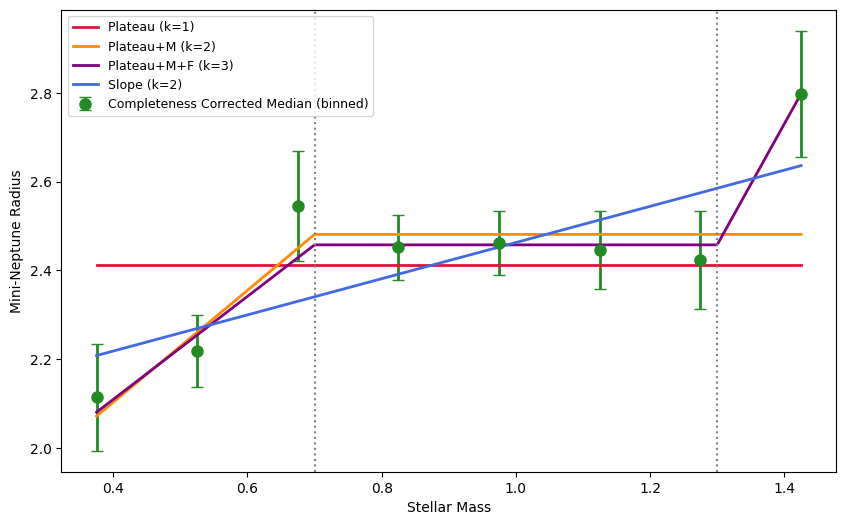

In [30]:
# ===========================================================================
# FIXED-BREAKPOINT MODEL COMPARISON  (breaks pinned at M = 0.7 and M = 1.3)
# ---------------------------------------------------------------------------
# Four physically-motivated shapes, all continuous, all fit to the binned
# data (xb, yb, eb):
#
#   1. Plateau                       k=1   flat everywhere
#   2. Plateau + M dwarf slope       k=2   rises below 0.7, flat above
#   3. Plateau + M dwarf + F slope   k=3   rises below 0.7, flat, rises above 1.3
#   4. Slope                         k=2   single straight line, no plateau
#
# WHY FIXING THE BREAKPOINTS MATTERS STATISTICALLY:
# In the free-breakpoint cells above, the break location was a parameter that
# vanishes under the null (if the slopes match, the breakpoint means nothing).
# That is the Davies problem, and it made the analytic chi2 likelihood-ratio
# test invalid -- hence the parametric bootstrap.
#
# Here 0.7 and 1.3 are FIXED by prior/physical choice, not fitted. Every
# remaining parameter is identified under every null, so the ordinary
# likelihood-ratio test IS valid: delta-chi2 ~ chi2(delta_k), no bootstrap
# required. That is a real gain in rigour, bought by committing to the
# breakpoints in advance.
# ===========================================================================
XB1, XB2 = 0.7, 1.3          # fixed breakpoints (M dwarf edge, F star edge)
X0 = xb.min()

# --- Model 1: plateau, k=1 -------------------------------------------------
def m_plateau(x, c):
    return np.full_like(np.asarray(x, dtype=float), c)

# --- Model 2: plateau + M dwarf slope, k=2 ---------------------------------
# Below XB1 the line rises with slope s1 and joins the plateau exactly at XB1
# (continuity is built in, not fitted). At and above XB1 it is flat at c.
def m_plateau_M(x, c, s1):
    x = np.asarray(x, dtype=float)
    return np.where(x < XB1, c + s1 * (x - XB1), c)

# --- Model 3: plateau + M dwarf slope + F star slope, k=3 ------------------
# Adds a third segment above XB2 rising with slope s3, again joined
# continuously at XB2.
def m_plateau_M_F(x, c, s1, s3):
    x = np.asarray(x, dtype=float)
    return np.select(
        [x < XB1, (x >= XB1) & (x <= XB2), x > XB2],
        [c + s1 * (x - XB1), np.full_like(x, c), c + s3 * (x - XB2)],
    )

# --- Model 4: plain slope, k=2 ---------------------------------------------
def m_slope(x, y0, s):
    return y0 + s * (np.asarray(x, dtype=float) - X0)

_slope_guess = (yb[-1] - yb[0]) / (xb[-1] - xb[0])
fixed_models = {
    'Plateau':          (m_plateau,     [np.median(yb)]),
    'Plateau+M':        (m_plateau_M,   [np.median(yb), _slope_guess]),
    'Plateau+M+F':      (m_plateau_M_F, [np.median(yb), _slope_guess, _slope_guess]),
    'Slope':            (m_slope,       [yb[0], _slope_guess]),
}

n_data = len(yb)
fixed_results = {}

print(f"Fixed breakpoints: {XB1} and {XB2}   |   n bins = {n_data}")
print(f"Bins below {XB1}: {(xb < XB1).sum()}   between: {((xb >= XB1) & (xb <= XB2)).sum()}"
      f"   above {XB2}: {(xb > XB2).sum()}")
print("=" * 92)
print(f"{'Model':<14}{'k':>3}{'chi2':>9}{'dof':>5}{'red.chi2':>10}{'AIC':>9}{'BIC':>9}")
print("-" * 92)

for name, (func, p0) in fixed_models.items():
    # All four models are LINEAR in their parameters, so curve_fit converges to
    # the unique global weighted-least-squares solution -- no multistart or
    # local-minimum worries like the free-breakpoint fits had.
    popt, _ = curve_fit(func, xb, yb, p0=p0, sigma=eb, absolute_sigma=True, maxfev=20000)
    chi2_val = np.sum(((yb - func(xb, *popt)) / eb) ** 2)
    k = len(popt)
    dof = n_data - k
    aic = chi2_val + 2 * k
    bic = chi2_val + k * np.log(n_data)
    fixed_results[name] = {'popt': popt, 'chi2': chi2_val, 'k': k, 'dof': dof,
                           'AIC': aic, 'BIC': bic}
    # reduced chi2 = chi2/dof: an absolute fit check, not a model comparison.
    # ~1 means the model matches the data to within the error bars; >>1 means it
    # genuinely misses; <1 means it is fitting noise (too many free parameters).
    print(f"{name:<14}{k:>3}{chi2_val:>9.3f}{dof:>5}{chi2_val/dof:>10.3f}"
          f"{aic:>9.3f}{bic:>9.3f}")

# --- Relative support: differences from the best model --------------------
print(f"\n{'Model':<14}{'dAIC':>9}{'dBIC':>9}")
print("-" * 32)
bA = min(r['AIC'] for r in fixed_results.values())
bB = min(r['BIC'] for r in fixed_results.values())
for name, r in fixed_results.items():
    print(f"{name:<14}{r['AIC']-bA:>9.3f}{r['BIC']-bB:>9.3f}")

# --- Nested likelihood-ratio tests ----------------------------------------
# Valid analytically here BECAUSE the breakpoints are fixed. Only genuinely
# nested pairs are listed: Plateau sits inside everything (all slopes -> 0),
# Plateau+M sits inside Plateau+M+F (s3 -> 0). Plateau+M vs Slope are NOT
# nested (both k=2, neither is a special case of the other) and Plateau+M+F vs
# Slope likewise -- compare those with AIC/BIC above, not with a p-value.
print("\nNested likelihood-ratio tests (analytic chi2 valid: breakpoints fixed)")
print("-" * 72)
print(f"{'comparison':<34}{'dchi2':>9}{'dk':>4}{'p':>12}")
NESTED = [('Plateau', 'Plateau+M'), ('Plateau+M', 'Plateau+M+F'),
          ('Plateau', 'Plateau+M+F'), ('Plateau', 'Slope')]
for null_n, alt_n in NESTED:
    d = fixed_results[null_n]['chi2'] - fixed_results[alt_n]['chi2']
    dk = fixed_results[alt_n]['k'] - fixed_results[null_n]['k']
    print(f"{null_n + ' -> ' + alt_n:<34}{d:>9.3f}{dk:>4}{chi2_dist.sf(max(d, 0), dk):>12.3g}")

print("\nBest-fit parameters:")
for name, r in fixed_results.items():
    print(f"  {name:<14}{np.round(r['popt'], 4)}")

# --- Plot ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))
ax.errorbar(xb, yb, yerr=eb, fmt='o', color='forestgreen', capsize=4,
            markersize=8, linewidth=2, label='Completeness Corrected Median (binned)')
x_line = np.linspace(xb.min(), xb.max(), 400)
fixed_colors = {'Plateau': 'crimson', 'Plateau+M': 'darkorange',
                'Plateau+M+F': 'purple', 'Slope': 'royalblue'}
for name, (func, _) in fixed_models.items():
    ax.plot(x_line, func(x_line, *fixed_results[name]['popt']),
            color=fixed_colors[name], lw=2,
            label=f"{name} (k={fixed_results[name]['k']})")
for xv in (XB1, XB2):
    ax.axvline(xv, color='grey', ls=':', lw=1.5)
ax.set_xlabel('Stellar Mass')
ax.set_ylabel('Mini-Neptune Radius')
ax.legend(fontsize=9)
#to png

ax.figure.savefig("statistical_analysis.png", dpi=300, bbox_inches="tight")

plt.show()


In [31]:
# ===========================================================================
# TEFF-BINNED COMPLETENESS-CORRECTED MEDIANS  (shared input, no model in sight)
# ---------------------------------------------------------------------------
# Pulled out of the fixed-breakpoint cell so that nothing downstream has to run
# it to get its data. xt / yt / et are just the binned points -- the pinned
# breakpoints TB1/TB2 never touched them -- and both the fixed-breakpoint and
# the free-breakpoint analyses read them from here.
#
# Same recipe as the mass binning: weighted median of pl_rade inside each bin
# using the injection/recovery `weight`, with bootstrap resampling for the
# error. bins_teff (3000-7000 K in 500 K steps) is reused from the earlier cell
# so this matches the temperature binning already used elsewhere.
#
# The bootstrap is SEEDED. It used to run off the global numpy state, so every
# re-run produced slightly different error bars (up to ~9% per bin) and hence
# slightly different chi2/AIC/BIC downstream -- enough to make two cells fitting
# the same data look like they disagreed. The medians were never affected.
# ===========================================================================
teff_rng = np.random.default_rng(11)

_mt = merged_df.dropna(subset=['st_teff', 'pl_rade', 'weight'])

t_centers, t_medians, t_errs = [], [], []
for _i in range(len(bins_teff) - 1):
    _lo, _hi = bins_teff[_i], bins_teff[_i + 1]
    _m = _mt[(_mt['st_teff'] >= _lo) & (_mt['st_teff'] < _hi)]
    _vals = _m['pl_rade'].values
    _w = _m['weight'].values
    t_centers.append(0.5 * (_lo + _hi))
    if len(_vals) == 0 or np.nansum(_w) <= 0:
        t_medians.append(np.nan)
        t_errs.append(np.nan)
        continue
    t_medians.append(weighted_median(_vals, _w))
    _boot = []
    for _ in range(n_bootstrap):
        _b = teff_rng.integers(0, len(_vals), size=len(_vals))
        _boot.append(weighted_median(_vals[_b], _w[_b]))
    t_errs.append(np.nanstd(_boot))

t_centers = np.array(t_centers, dtype=float)
t_medians = np.array(t_medians, dtype=float)
t_errs = np.array(t_errs, dtype=float)

_ok = ~(np.isnan(t_medians) | np.isnan(t_errs) | (t_errs == 0))
xt, yt, et = t_centers[_ok], t_medians[_ok], t_errs[_ok]

print(f"Teff bins with a usable median and error: {len(yt)}")
for _c, _m, _e in zip(xt, yt, et):
    print(f"  {_c:7.0f} K   median = {_m:.4f}   error = {_e:.4f} R_Earth")


Teff bins with a usable median and error: 8
     3250 K   median = 2.1024   error = 0.1238 R_Earth
     3750 K   median = 2.2494   error = 0.0502 R_Earth
     4250 K   median = 2.6351   error = 0.1225 R_Earth
     4750 K   median = 2.3911   error = 0.1126 R_Earth
     5250 K   median = 2.4514   error = 0.0573 R_Earth
     5750 K   median = 2.4586   error = 0.0784 R_Earth
     6250 K   median = 2.4432   error = 0.0607 R_Earth
     6750 K   median = 2.7978   error = 0.1261 R_Earth


Fixed breakpoints: 4440 K and 6475 K   |   n bins = 8
Bins below 4440: 3   between: 4   above 6475: 1
Model           k     chi2  dof  red.chi2      AIC      BIC
--------------------------------------------------------------------------------------------
Plateau         1   30.301    7     4.329   32.301   32.381
Plateau+M       2   10.804    6     1.801   14.804   14.963
Plateau+M+F     3    4.054    5     0.811   10.054   10.292
Slope           2   12.822    6     2.137   16.822   16.981

Model              dAIC     dBIC
--------------------------------
Plateau          22.247   22.089
Plateau+M         4.750    4.671
Plateau+M+F       0.000    0.000
Slope             6.769    6.689

Nested likelihood-ratio tests (analytic chi2 valid: breakpoints fixed)
------------------------------------------------------------------------
comparison                            dchi2  dk           p
Plateau -> Plateau+M                 19.497   1    1.01e-05
Plateau+M -> Plateau+M+F              6.7

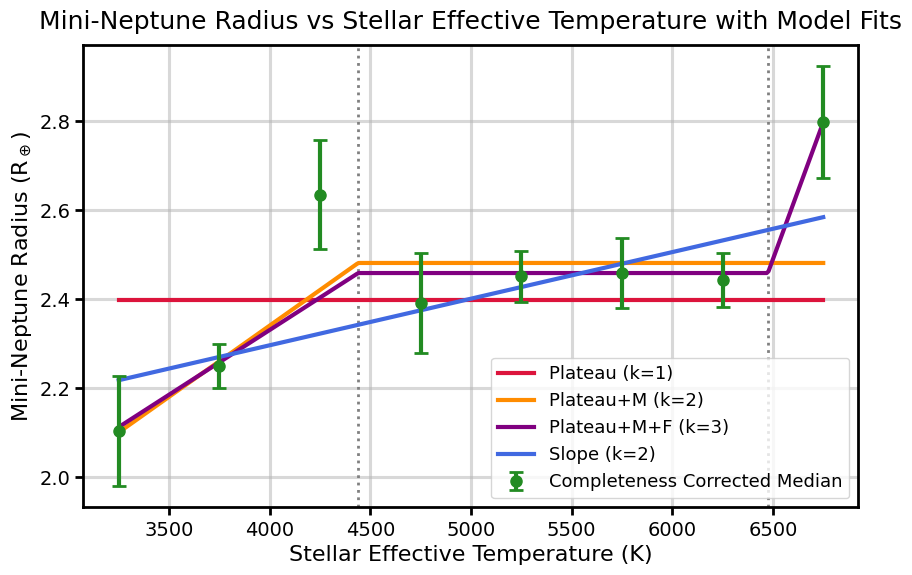

In [32]:
# ===========================================================================
# SAME FIXED-BREAKPOINT COMPARISON, BUT IN EFFECTIVE TEMPERATURE
# ---------------------------------------------------------------------------
# Identical four models and identical statistics to the cell above; the only
# change is the x axis: stellar Teff instead of stellar mass.
#
# BREAKPOINTS. The mass version pinned breaks at 0.7 and 1.3 Msun. Those are
# converted to Teff with the Mamajek (2022) dwarf sequence table already in the
# repo, so the two analyses mark the same physical boundaries:
#       0.7 Msun -> 4440 K      1.3 Msun -> 6475 K
# (Both land within ~60 K of the existing 4500 / 6500 K bin edges, so the
# choice is not sensitive to the exact interpolation.) Set them by hand below
# if you prefer round numbers or a different sequence -- but fix them BEFORE
# looking at the fit, or the analytic likelihood-ratio p-values stop being
# valid for the same reason explained in the mass cell.
# ===========================================================================
TB1, TB2 = 4440.0, 6475.0     # Teff equivalents of 0.7 and 1.3 Msun (Mamajek 2022)

# --- Teff-binned data comes from the cell above ----------------------------
# xt / yt / et are built there so this cell only owns the models, not the data.
# --- The same four shapes, now as functions of Teff ------------------------
T0 = xt.min()

def t_plateau(x, c):
    return np.full_like(np.asarray(x, dtype=float), c)

def t_plateau_M(x, c, s1):
    x = np.asarray(x, dtype=float)
    return np.where(x < TB1, c + s1 * (x - TB1), c)

def t_plateau_M_F(x, c, s1, s3):
    x = np.asarray(x, dtype=float)
    return np.select(
        [x < TB1, (x >= TB1) & (x <= TB2), x > TB2],
        [c + s1 * (x - TB1), np.full_like(x, c), c + s3 * (x - TB2)],
    )

def t_slope(x, y0, s):
    return y0 + s * (np.asarray(x, dtype=float) - T0)

# Slopes are per KELVIN here, so the numbers are ~1e-4. The starting guess is
# scaled accordingly; fitted slopes are reported per 1000 K to stay readable.
_sg = (yt[-1] - yt[0]) / (xt[-1] - xt[0])
teff_models = {
    'Plateau':     (t_plateau,     [np.median(yt)]),
    'Plateau+M':   (t_plateau_M,   [np.median(yt), _sg]),
    'Plateau+M+F': (t_plateau_M_F, [np.median(yt), _sg, _sg]),
    'Slope':       (t_slope,       [yt[0], _sg]),
}

n_t = len(yt)
teff_results = {}

print(f"Fixed breakpoints: {TB1:.0f} K and {TB2:.0f} K   |   n bins = {n_t}")
print(f"Bins below {TB1:.0f}: {(xt < TB1).sum()}   between: {((xt >= TB1) & (xt <= TB2)).sum()}"
      f"   above {TB2:.0f}: {(xt > TB2).sum()}")
print("=" * 92)
print(f"{'Model':<14}{'k':>3}{'chi2':>9}{'dof':>5}{'red.chi2':>10}{'AIC':>9}{'BIC':>9}")
print("-" * 92)

for name, (func, p0) in teff_models.items():
    popt, _ = curve_fit(func, xt, yt, p0=p0, sigma=et, absolute_sigma=True, maxfev=20000)
    chi2_val = np.sum(((yt - func(xt, *popt)) / et) ** 2)
    k = len(popt)
    dof = n_t - k
    aic = chi2_val + 2 * k
    bic = chi2_val + k * np.log(n_t)
    teff_results[name] = {'popt': popt, 'chi2': chi2_val, 'k': k, 'dof': dof,
                          'AIC': aic, 'BIC': bic}
    print(f"{name:<14}{k:>3}{chi2_val:>9.3f}{dof:>5}{chi2_val/dof:>10.3f}"
          f"{aic:>9.3f}{bic:>9.3f}")

print(f"\n{'Model':<14}{'dAIC':>9}{'dBIC':>9}")
print("-" * 32)
_bA = min(r['AIC'] for r in teff_results.values())
_bB = min(r['BIC'] for r in teff_results.values())
for name, r in teff_results.items():
    print(f"{name:<14}{r['AIC']-_bA:>9.3f}{r['BIC']-_bB:>9.3f}")

print("\nNested likelihood-ratio tests (analytic chi2 valid: breakpoints fixed)")
print("-" * 72)
print(f"{'comparison':<34}{'dchi2':>9}{'dk':>4}{'p':>12}")
for null_n, alt_n in [('Plateau', 'Plateau+M'), ('Plateau+M', 'Plateau+M+F'),
                      ('Plateau', 'Plateau+M+F'), ('Plateau', 'Slope')]:
    d = teff_results[null_n]['chi2'] - teff_results[alt_n]['chi2']
    dk = teff_results[alt_n]['k'] - teff_results[null_n]['k']
    print(f"{null_n + ' -> ' + alt_n:<34}{d:>9.3f}{dk:>4}{chi2_dist.sf(max(d, 0), dk):>12.3g}")

print("\nBest-fit parameters (slopes per 1000 K):")
for name, r in teff_results.items():
    _p = r['popt'].copy()
    _p[1:] = _p[1:] * 1000.0        # first param is the plateau level / intercept
    print(f"  {name:<14}{np.round(_p, 4)}")

# --- Plot ------------------------------------------------------------------
# Weights/sizes match the presentation-figure style used for the other PNGs
# (see the stellar_temp_vs_disk_mass figure): linewidth 3, capthick 2, heavy
# grid behind the data, thicker spines and larger fonts so the figure survives
# being scaled down in a paper or slide.
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)                      # grid behind the data, never over it

ax.errorbar(xt, yt, yerr=et, fmt='o', color='forestgreen', capsize=5, capthick=2,
            markersize=8, linewidth=3, zorder=4,
            label='Completeness Corrected Median')
_xl = np.linspace(xt.min(), xt.max(), 400)
_col = {'Plateau': 'crimson', 'Plateau+M': 'darkorange',
        'Plateau+M+F': 'purple', 'Slope': 'royalblue'}
for name, (func, _) in teff_models.items():
    ax.plot(_xl, func(_xl, *teff_results[name]['popt']), color=_col[name], lw=3,
            zorder=3, label=f"{name} (k={teff_results[name]['k']})")
for _xv in (TB1, TB2):
    ax.axvline(_xv, color='grey', ls=':', lw=2, zorder=2)
ax.set_title('Mini-Neptune Radius vs Stellar Effective Temperature with Model Fits',
             fontsize=18, pad=12)
ax.set_xlabel('Stellar Effective Temperature (K)', fontsize=16)
ax.set_ylabel(r'Mini-Neptune Radius (R$_\oplus$)', fontsize=16)
ax.tick_params(width=2, length=6, labelsize=14)
for _sp in ax.spines.values():
    _sp.set_linewidth(2)
ax.legend(fontsize=13)
ax.figure.savefig("statistical_analysis_teff.png", dpi=300, bbox_inches="tight")
plt.show()


AXIS: stellar mass    (n bins = 8)
Model                       k     chi2  dof  red.chi2      AIC      BIC
------------------------------------------------------------------------------
Plateau                     1   21.343    7     3.049   23.343   23.422
Sym rise-plateau-rise       4    1.867    4     0.467    9.867   10.184
  (earlier) Plateau         1   21.343    7     3.049   23.343   23.422
  (earlier) Plateau+M       2    6.641    6     1.107   10.641   10.800
  (earlier) Plateau+M+F     3    1.286    5     0.257    7.286    7.525
  (earlier) Slope           2    8.516    6     1.419   12.516   12.675

Model                          dAIC     dBIC
--------------------------------------------
Plateau+M+F                   0.000    0.000
Sym rise-plateau-rise         2.580    2.660
Plateau+M                     3.355    3.275
Slope                         5.230    5.151
Plateau                      16.056   15.897

best fit:  c = 2.4642   x1 = 0.675   x2 = 1.261   slope = 1.413



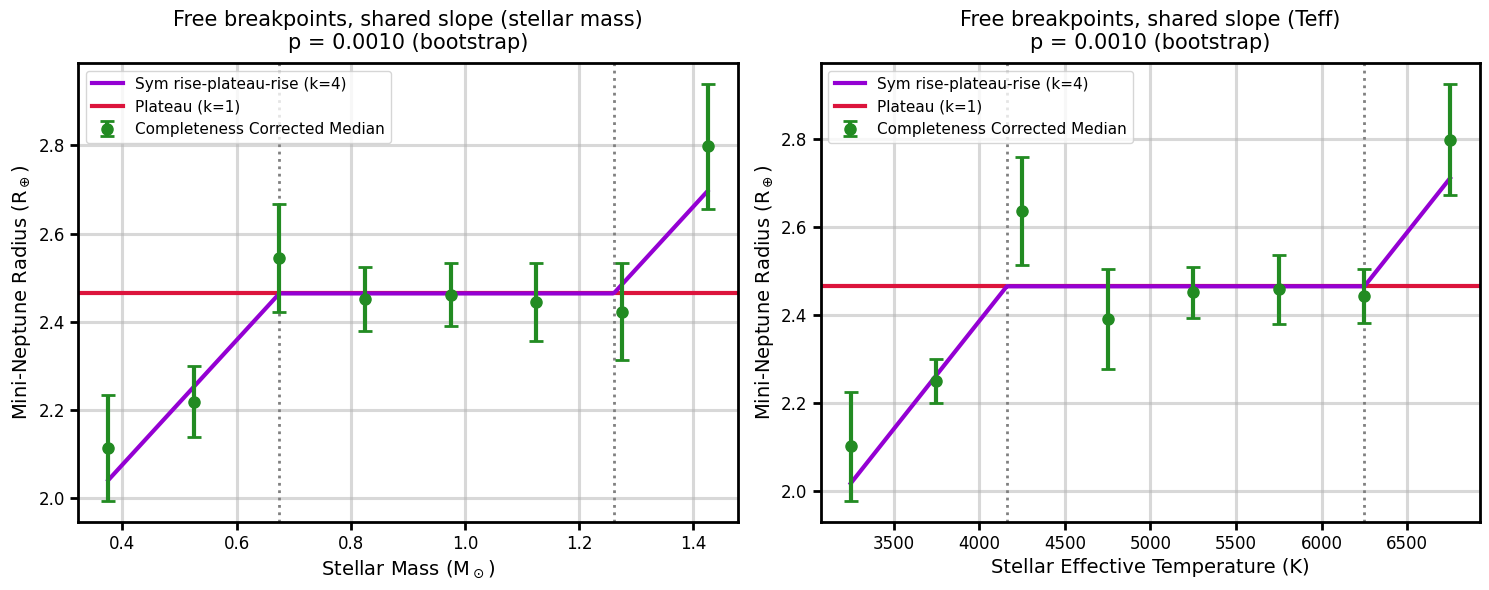

In [33]:
# ===========================================================================
# SYMMETRIC RISE-PLATEAU-RISE, WITH THE BREAKPOINTS FREE AGAIN
# ---------------------------------------------------------------------------
# Shape: rises with slope s below x1, flat at c between x1 and x2, rises with
# THE SAME slope s above x2. Continuity at both joins is built in.
#
#   k = 4:  c, x1, x2, s
#
# That is 2 fewer parameters than the free two-break model (k=6), bought by two
# physical assumptions rather than by fitting:
#   * the middle segment is exactly flat  (kills s2)
#   * the two wings share one slope       (kills s3, ties it to s1)
#
# STATISTICAL WARNING -- THE BOOTSTRAP IS BACK.
# Because x1 and x2 are fitted again, they are UNIDENTIFIED under the null
# s = 0: if the slope is zero, the model is flat everywhere and the breakpoints
# mean nothing. That is the Davies problem, so delta-chi2 does NOT follow
# chi2(3) and the analytic p-value would be wrong (and anti-conservative).
# The p-value below therefore comes from a parametric bootstrap: simulate from
# the best-fit Plateau using the real errors, refit both models each time, and
# read the observed delta-chi2 against that empirical null.
#
# Run on BOTH axes (stellar mass and Teff) so it lines up with either of the
# fixed-breakpoint cells above.
# ===========================================================================
N_SIM_SYM = 1000          # bootstrap draws per axis; ~1-2 min total
_rng = np.random.default_rng(7)


def m_sym(x, c, x1, x2, s):
    """Rise (slope s) -> flat at c -> rise (slope s). Continuous by construction."""
    x = np.asarray(x, dtype=float)
    return np.select(
        [x < x1, (x >= x1) & (x <= x2), x > x2],
        [c + s * (x - x1), np.full_like(x, c), c + s * (x - x2)],
    )


def _fit_flat(x, y, e):
    f = lambda xx, c: np.full_like(np.asarray(xx, float), c)
    p, _ = curve_fit(f, x, y, p0=[np.median(y)], sigma=e, absolute_sigma=True)
    return np.sum(((y - f(x, *p)) / e) ** 2), p


def _fit_sym(x, y, e):
    """Multistart fit. Free breakpoints make the chi2 surface multi-modal, so a
    single guess can land in a local minimum -- which would understate delta-chi2
    and bias the bootstrap. Try a spread of (x1, x2) starts and keep the best."""
    lo, hi = x.min(), x.max()
    span = hi - lo
    s0 = (y[-1] - y[0]) / span
    best_c, best_p = np.inf, None
    for f1, f2 in [(0.20, 0.80), (0.30, 0.70), (0.15, 0.55), (0.45, 0.85), (0.35, 0.60)]:
        p0 = [np.median(y), lo + f1 * span, lo + f2 * span, s0]
        try:
            p, _ = curve_fit(m_sym, x, y, p0=p0, sigma=e, absolute_sigma=True,
                             bounds=([-np.inf, lo, lo, -np.inf],
                                     [np.inf, hi, hi, np.inf]), maxfev=40000)
        except Exception:
            continue
        if p[1] > p[2]:          # breakpoints crossed -> degenerate, discard
            continue
        c = np.sum(((y - m_sym(x, *p)) / e) ** 2)
        if c < best_c:
            best_c, best_p = c, p
    return best_c, best_p


sym_results = {}
for _label, (_x, _y, _e) in [('stellar mass', (xb, yb, eb)),
                             ('Teff', (xt, yt, et))]:
    _n = len(_y)
    chi_flat, p_flat = _fit_flat(_x, _y, _e)
    chi_sym, p_sym = _fit_sym(_x, _y, _e)

    print("=" * 78)
    print(f"AXIS: {_label}    (n bins = {_n})")
    print("=" * 78)
    print(f"{'Model':<26}{'k':>3}{'chi2':>9}{'dof':>5}{'red.chi2':>10}{'AIC':>9}{'BIC':>9}")
    print("-" * 78)
    _all = []      # (display name, chi2, k) for every model on this axis
    for nm, ch, k in [('Plateau', chi_flat, 1), ('Sym rise-plateau-rise', chi_sym, 4)]:
        print(f"{nm:<26}{k:>3}{ch:>9.3f}{_n-k:>5}{ch/(_n-k):>10.3f}"
              f"{ch+2*k:>9.3f}{ch+k*np.log(_n):>9.3f}")
        _all.append((nm, ch, k))

    # Compare against the fixed-breakpoint models fitted earlier on the same axis,
    # so the reduction in parameters can be judged against what it replaced.
    # (Plateau is skipped -- it is the same fit already listed above, and printing
    # it twice in the delta table would be noise. The two rows agreeing exactly is
    # a useful check that both cells are working from identical xb/yb/eb.)
    _prev = fixed_results if _label == 'stellar mass' else teff_results
    for nm, r in _prev.items():
        print(f"{'  (earlier) ' + nm:<26}{r['k']:>3}{r['chi2']:>9.3f}{r['dof']:>5}"
              f"{r['chi2']/r['dof']:>10.3f}{r['AIC']:>9.3f}{r['BIC']:>9.3f}")
        if nm != 'Plateau':
            _all.append((nm, r['chi2'], r['k']))

    # --- dAIC / dBIC across every model on this axis ------------------------
    # CAVEAT: the free-breakpoint model is charged k=4, which INCLUDES locating
    # x1 and x2. Plateau+M / Plateau+M+F are charged k=2 / k=3 while using two
    # breakpoint values supplied from outside the fit. If those values were in
    # fact chosen by looking at this data, the fixed models are under-charged by
    # 2 parameters (~4 in AIC) and this ranking flatters them.
    _aic = {nm: ch + 2 * k for nm, ch, k in _all}
    _bic = {nm: ch + k * np.log(_n) for nm, ch, k in _all}
    _ba, _bb = min(_aic.values()), min(_bic.values())
    print(f"\n{'Model':<26}{'dAIC':>9}{'dBIC':>9}")
    print("-" * 44)
    for nm, ch, k in sorted(_all, key=lambda t: _aic[t[0]]):
        print(f"{nm:<26}{_aic[nm]-_ba:>9.3f}{_bic[nm]-_bb:>9.3f}")

    print(f"\nbest fit:  c = {p_sym[0]:.4f}   x1 = {p_sym[1]:.4g}   "
          f"x2 = {p_sym[2]:.4g}   slope = {p_sym[3]:.4g}")

    # --- Parametric bootstrap for Plateau -> symmetric model ---------------
    d_obs = max(chi_flat - chi_sym, 0.0)
    y_null = np.full_like(_y, p_flat[0])
    _d = []
    for _ in range(N_SIM_SYM):
        y_sim = y_null + _rng.normal(0.0, _e)
        cf, _ = _fit_flat(_x, y_sim, _e)
        cs, ps = _fit_sym(_x, y_sim, _e)
        if ps is None or not np.isfinite(cs):
            continue
        _d.append(max(cf - cs, 0.0))
    _d = np.asarray(_d)
    p_boot = (1 + np.sum(_d >= d_obs)) / (1 + len(_d))

    print(f"\nPlateau -> symmetric   dchi2 = {d_obs:.3f}   (nominal dk = 3)")
    print(f"  p (parametric bootstrap) = {p_boot:.4f}   <-- use this one")
    print(f"  p (naive chi2, INVALID)  = {chi2_dist.sf(d_obs, 3):.3g}")
    print(f"  95% critical dchi2: {np.percentile(_d, 95):.3f} (bootstrap) "
          f"vs {chi2_dist.ppf(0.95, 3):.3f} (chi2 assumption)\n")

    sym_results[_label] = {'popt': p_sym, 'chi2': chi_sym, 'k': 4,
                           'chi2_flat': chi_flat, 'd_obs': d_obs, 'p_boot': p_boot}

# --- Plot both axes --------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (_label, (_x, _y, _e), _xl_txt) in zip(axes, [
        ('stellar mass', (xb, yb, eb), 'Stellar Mass (M$_\\odot$)'),
        ('Teff', (xt, yt, et), 'Stellar Effective Temperature (K)')]):
    r = sym_results[_label]
    ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
    ax.set_axisbelow(True)
    ax.errorbar(_x, _y, yerr=_e, fmt='o', color='forestgreen', capsize=5,
                capthick=2, markersize=8, linewidth=3, zorder=4,
                label='Completeness Corrected Median')
    _g = np.linspace(_x.min(), _x.max(), 400)
    ax.plot(_g, m_sym(_g, *r['popt']), color='darkviolet', lw=3, zorder=3,
            label=f"Sym rise-plateau-rise (k=4)")
    ax.axhline(r['popt'][0], color='crimson', lw=3, zorder=2, label='Plateau (k=1)')
    for _xv in (r['popt'][1], r['popt'][2]):
        ax.axvline(_xv, color='grey', ls=':', lw=2, zorder=2)
    ax.set_title(f"Free breakpoints, shared slope ({_label})\n"
                 f"p = {r['p_boot']:.4f} (bootstrap)", fontsize=15, pad=10)
    ax.set_xlabel(_xl_txt, fontsize=14)
    ax.set_ylabel(r'Mini-Neptune Radius (R$_\oplus$)', fontsize=14)
    ax.tick_params(width=2, length=6, labelsize=12)
    for _sp in ax.spines.values():
        _sp.set_linewidth(2)
    ax.legend(fontsize=11)
plt.tight_layout()
fig.savefig("statistical_analysis_symmetric.png", dpi=300, bbox_inches="tight")
plt.show()


AXIS: stellar mass    (n bins = 8)    ALL BREAKPOINTS FREE
Model           k     chi2  dof  red.chi2      AIC      BIC
--------------------------------------------------------------------------------
Plateau         1   21.343    7     3.049   23.343   23.422
Slope           2    8.516    6     1.419   12.516   12.675
Plateau+M       3    6.521    5     1.304   12.521   12.759
Symmetric       4    1.867    4     0.467    9.867   10.184

Model              dAIC     dBIC
--------------------------------
Symmetric         0.000    0.000
Slope             2.650    2.491
Plateau+M         2.654    2.575
Plateau          13.476   13.238

Fitted breakpoints (compare with the pinned values used earlier):
  Plateau+M   x1 = 0.675
  Symmetric   x1 = 0.675   x2 = 1.261

Plateau -> each alternative
comparison                    dchi2  dk   p (boot)   p (chi2)
Plateau -> Slope             12.826   1     0.0010   0.000342
Plateau -> Plateau+M         14.822   2     0.0020   0.000605  <- chi2 invalid

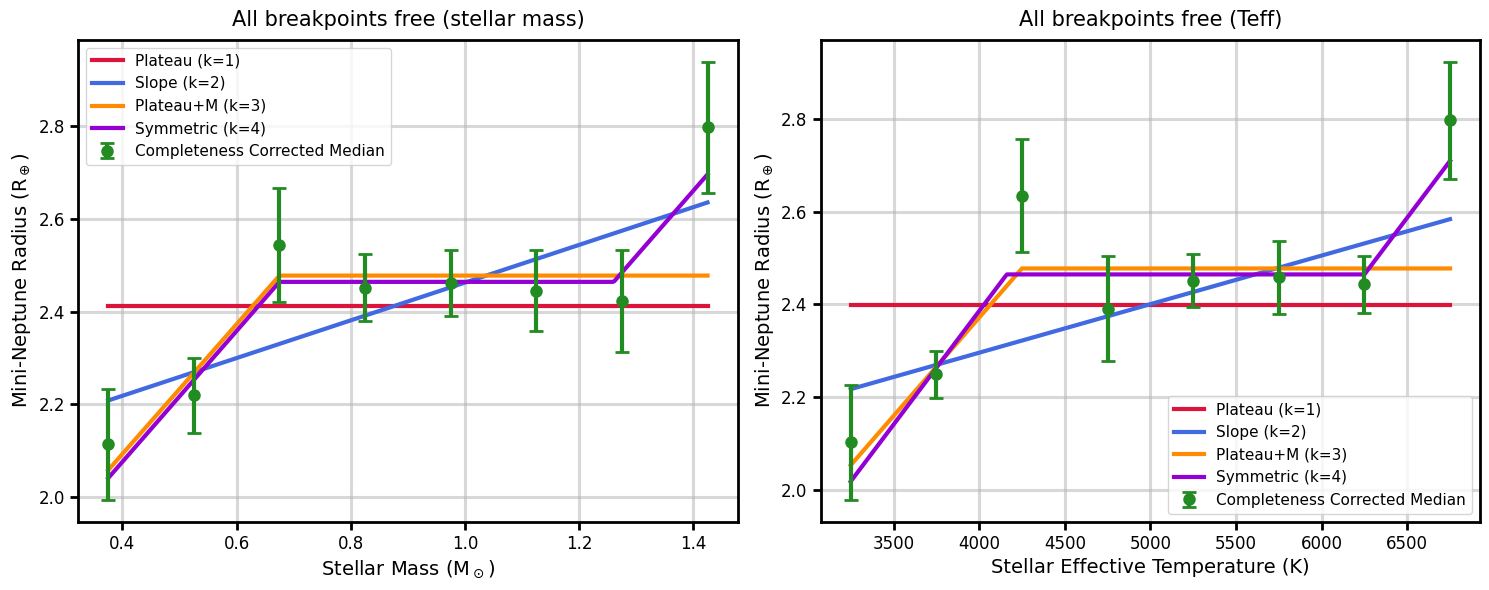

In [34]:
# ===========================================================================
# ALL FOUR MODELS WITH NOTHING PINNED -- BREAKPOINTS FITTED FROM THE DATA
# ---------------------------------------------------------------------------
#   Plateau        k=1   c                    (no breakpoint to free)
#   Slope          k=2   y0, s                (no breakpoint to free)
#   Plateau+M      k=3   c, x1, s1            (was k=2 with x1 pinned)
#   Symmetric      k=4   c, x1, x2, s         (rise / flat / rise, shared slope)
#
# This is the honest-cost version of the fixed-breakpoint cells: every model now
# PAYS for the breakpoints it uses instead of being handed them. Plateau and
# Slope are unchanged (they have no breakpoints), so any movement in the ranking
# comes purely from charging the other two properly.
#
# DAVIES PROBLEM -> BOOTSTRAP p-VALUES.
# Plateau+M and Symmetric both fit breakpoints that are UNIDENTIFIED under the
# null s = 0 (a flat line is flat wherever you put the break), so delta-chi2 does
# NOT follow chi2(dk) for those two and the analytic p-value would be wrong.
# Their p-values below come from a parametric bootstrap instead.
#
# Slope is the exception: it has no breakpoint, so it is a regular nested
# comparison and the analytic chi2 IS valid. It is bootstrapped anyway and both
# numbers printed -- they should agree, which is a free check that the bootstrap
# machinery is behaving.
# ===========================================================================
N_SIM_FREE = 1000
_rngf = np.random.default_rng(11)


def f_plateau(x, c):
    return np.full_like(np.asarray(x, dtype=float), c)


def f_plateau_M(x, c, x1, s1):
    """Rises with slope s1 below x1, flat at c above it. x1 now fitted."""
    x = np.asarray(x, dtype=float)
    return np.where(x < x1, c + s1 * (x - x1), c)


def f_sym(x, c, x1, x2, s):
    """Rise -> flat -> rise, both wings sharing one slope. x1, x2 fitted."""
    x = np.asarray(x, dtype=float)
    return np.select(
        [x < x1, (x >= x1) & (x <= x2), x > x2],
        [c + s * (x - x1), np.full_like(x, c), c + s * (x - x2)],
    )


def _specs(x, y):
    """Model table for one axis: name -> (func, [starting guesses], bounds, check).

    Several starting points are supplied for every model with a free breakpoint:
    those chi2 surfaces are multi-modal, and a single guess can settle in a local
    minimum, which would understate delta-chi2 and bias the bootstrap null.
    """
    lo, hi = x.min(), x.max()
    span = hi - lo
    s0 = (y[-1] - y[0]) / span
    med = np.median(y)

    def f_slope(xx, y0, s, _lo=lo):
        return y0 + s * (np.asarray(xx, dtype=float) - _lo)

    return {
        'Plateau':   (f_plateau, [[med]], (-np.inf, np.inf), None),
        'Slope':     (f_slope, [[y[0], s0]], (-np.inf, np.inf), None),
        'Plateau+M': (f_plateau_M,
                      [[med, lo + f * span, s0] for f in (0.2, 0.35, 0.5, 0.65, 0.8)],
                      ([-np.inf, lo, -np.inf], [np.inf, hi, np.inf]), None),
        'Symmetric': (f_sym,
                      [[med, lo + a * span, lo + b * span, s0]
                       for a, b in ((0.2, 0.8), (0.3, 0.7), (0.15, 0.55),
                                    (0.45, 0.85), (0.35, 0.6))],
                      ([-np.inf, lo, lo, -np.inf], [np.inf, hi, hi, np.inf]),
                      lambda p: p[1] <= p[2]),      # reject crossed breakpoints
    }


def _fit_one(spec, x, y, e):
    func, starts, bounds, check = spec
    best_c, best_p = np.inf, None
    for p0 in starts:
        try:
            p, _ = curve_fit(func, x, y, p0=p0, sigma=e, absolute_sigma=True,
                             bounds=bounds, maxfev=40000)
        except Exception:
            continue
        if check is not None and not check(p):
            continue
        ch = np.sum(((y - func(x, *p)) / e) ** 2)
        if ch < best_c:
            best_c, best_p = ch, p
    return best_c, best_p


free_results = {}
for _label, (_x, _y, _e) in [('stellar mass', (xb, yb, eb)), ('Teff', (xt, yt, et))]:
    _n = len(_y)
    _sp = _specs(_x, _y)
    _fit = {nm: _fit_one(_sp[nm], _x, _y, _e) for nm in _sp}
    _k = {'Plateau': 1, 'Slope': 2, 'Plateau+M': 3, 'Symmetric': 4}

    print("=" * 80)
    print(f"AXIS: {_label}    (n bins = {_n})    ALL BREAKPOINTS FREE")
    print("=" * 80)
    print(f"{'Model':<14}{'k':>3}{'chi2':>9}{'dof':>5}{'red.chi2':>10}{'AIC':>9}{'BIC':>9}")
    print("-" * 80)
    _aic, _bic = {}, {}
    for nm in ['Plateau', 'Slope', 'Plateau+M', 'Symmetric']:
        ch = _fit[nm][0]
        k = _k[nm]
        _aic[nm] = ch + 2 * k
        _bic[nm] = ch + k * np.log(_n)
        print(f"{nm:<14}{k:>3}{ch:>9.3f}{_n-k:>5}{ch/(_n-k):>10.3f}"
              f"{_aic[nm]:>9.3f}{_bic[nm]:>9.3f}")

    _ba, _bb = min(_aic.values()), min(_bic.values())
    print(f"\n{'Model':<14}{'dAIC':>9}{'dBIC':>9}")
    print("-" * 32)
    for nm in sorted(_aic, key=_aic.get):
        print(f"{nm:<14}{_aic[nm]-_ba:>9.3f}{_bic[nm]-_bb:>9.3f}")

    print("\nFitted breakpoints (compare with the pinned values used earlier):")
    print(f"  Plateau+M   x1 = {_fit['Plateau+M'][1][1]:.4g}")
    print(f"  Symmetric   x1 = {_fit['Symmetric'][1][1]:.4g}   "
          f"x2 = {_fit['Symmetric'][1][2]:.4g}")

    # --- One bootstrap loop, all three comparisons -------------------------
    # Simulate from the best-fit Plateau (the null) using the real per-bin
    # errors, refit everything, and collect delta-chi2 for each alternative.
    # Doing it in a single loop keeps the three null distributions consistent
    # with one another and costs no more than doing one of them.
    _c_null = _fit['Plateau'][0]
    _y0 = np.full_like(_y, _fit['Plateau'][1][0])
    _alts = ['Slope', 'Plateau+M', 'Symmetric']
    _dist = {a: [] for a in _alts}
    for _ in range(N_SIM_FREE):
        _ys = _y0 + _rngf.normal(0.0, _e)
        _cn, _ = _fit_one(_sp['Plateau'], _x, _ys, _e)
        for a in _alts:
            _ca, _pa = _fit_one(_sp[a], _x, _ys, _e)
            if _pa is not None and np.isfinite(_ca):
                _dist[a].append(max(_cn - _ca, 0.0))

    print("\nPlateau -> each alternative")
    print(f"{'comparison':<26}{'dchi2':>9}{'dk':>4}{'p (boot)':>11}{'p (chi2)':>11}")
    for a in _alts:
        d_obs = max(_c_null - _fit[a][0], 0.0)
        dk = _k[a] - 1
        arr = np.asarray(_dist[a])
        p_b = (1 + np.sum(arr >= d_obs)) / (1 + len(arr))
        note = '' if a == 'Slope' else '  <- chi2 invalid (Davies)'
        print(f"{'Plateau -> ' + a:<26}{d_obs:>9.3f}{dk:>4}{p_b:>11.4f}"
              f"{chi2_dist.sf(d_obs, dk):>11.3g}{note}")
    print(f"(bootstrap floor = 1/{N_SIM_FREE + 1} = {1/(N_SIM_FREE+1):.4f}; "
          f"'p = {1/(N_SIM_FREE+1):.4f}' means no simulation reached the observed value)")
    print()

    free_results[_label] = {'fit': _fit, 'k': _k, 'aic': _aic, 'specs': _sp}

# --- Plot ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
_cols = {'Plateau': 'crimson', 'Slope': 'royalblue',
         'Plateau+M': 'darkorange', 'Symmetric': 'darkviolet'}
for ax, (_label, (_x, _y, _e), _xtxt) in zip(axes, [
        ('stellar mass', (xb, yb, eb), r'Stellar Mass (M$_\odot$)'),
        ('Teff', (xt, yt, et), 'Stellar Effective Temperature (K)')]):
    R = free_results[_label]
    ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
    ax.set_axisbelow(True)
    ax.errorbar(_x, _y, yerr=_e, fmt='o', color='forestgreen', capsize=5,
                capthick=2, markersize=8, linewidth=3, zorder=5,
                label='Completeness Corrected Median')
    _g = np.linspace(_x.min(), _x.max(), 400)
    for nm in ['Plateau', 'Slope', 'Plateau+M', 'Symmetric']:
        ax.plot(_g, R['specs'][nm][0](_g, *R['fit'][nm][1]), color=_cols[nm],
                lw=3, zorder=3, label=f"{nm} (k={R['k'][nm]})")
    # for _xv in (R['fit']['Symmetric'][1][1], R['fit']['Symmetric'][1][2]):
    #     ax.axvline(_xv, color='grey', ls=':', lw=2, zorder=2)
    ax.set_title(f'All breakpoints free ({_label})', fontsize=15, pad=10)
    ax.set_xlabel(_xtxt, fontsize=14)
    ax.set_ylabel(r'Mini-Neptune Radius (R$_\oplus$)', fontsize=14)
    ax.tick_params(width=2, length=6, labelsize=12)
    for _s in ax.spines.values():
        _s.set_linewidth(2)
    ax.legend(fontsize=11)
plt.tight_layout()
fig.savefig("statistical_analysis_free_breakpoints.png", dpi=300, bbox_inches="tight")
plt.show()


AXIS: stellar mass    (n bins = 8)    all breakpoints fitted
Model         k     chi2  dof  red.chi2      AIC     AICc      BIC
------------------------------------------------------------------------------------
Plateau       1   21.343    7     3.049   23.343   24.009   23.422
Slope         2    8.516    6     1.419   12.516   14.916   12.675
Plateau+M     3    6.521    5     1.304   12.521   18.521   12.759
Symmetric     4    1.867    4     0.467    9.867   23.200   10.184

Model            dAIC    dAICc     dBICweighted(AICc)
-------------------------------------------------
Slope           2.650    0.000    2.491     0.839
Plateau+M       2.654    3.604    2.575     0.138
Symmetric       0.000    8.283    0.000     0.013
Plateau        13.476    9.093   13.238     0.009

Best by AIC : Symmetric
Best by AICc: Slope   <- use this one (n/k as low as 2.0)
Best by BIC : Symmetric

Fitted breakpoints:
  Plateau+M   x1 = 0.675
  Symmetric   x1 = 0.675   x2 = 1.261

AXIS: Teff    (n bins 

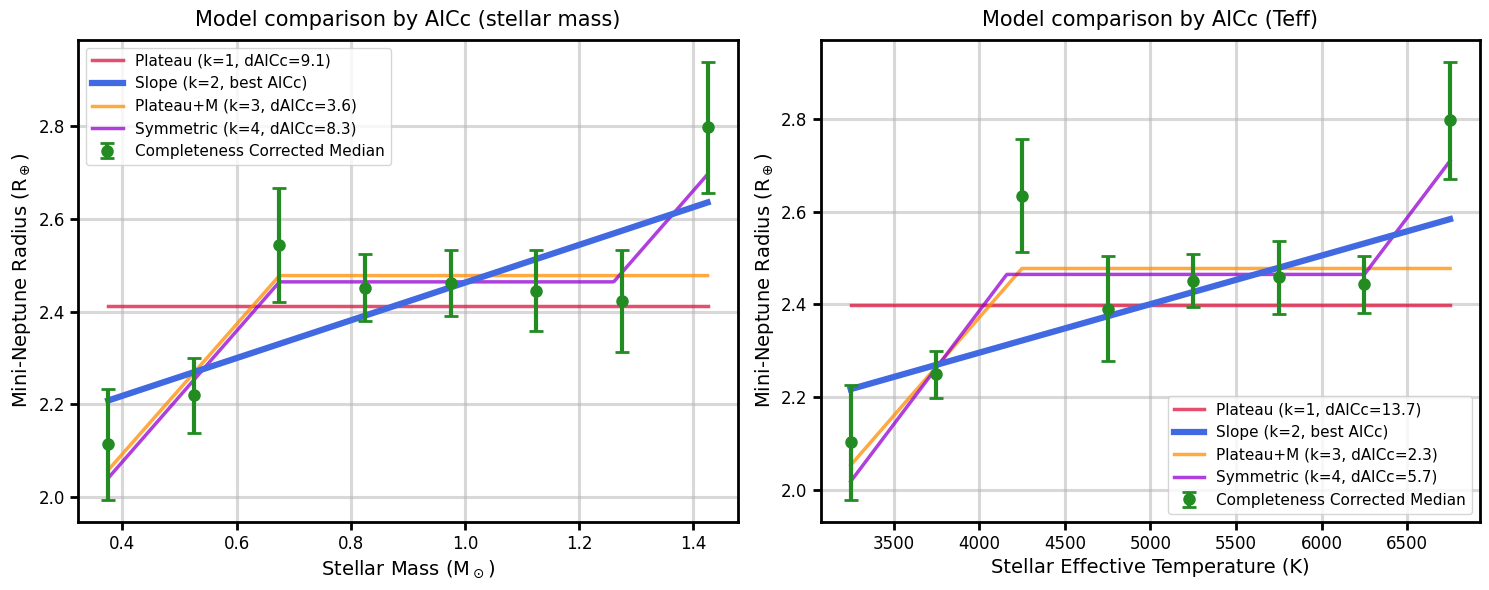

In [35]:
# ===========================================================================
# INFORMATION-CRITERION MODEL COMPARISON -- NO HYPOTHESIS TESTS
# ---------------------------------------------------------------------------
#   Plateau     k=1   c                 flat
#   Slope       k=2   y0, s             single straight line
#   Plateau+M   k=3   c, x1, s1         rise -> flat, breakpoint fitted
#   Symmetric   k=4   c, x1, x2, s      rise -> flat -> rise, breakpoints fitted
#
# All breakpoints are fitted from the data, so every model pays for the
# freedom it uses. This cell reports ONLY chi2, AIC, AICc and BIC. No p-values,
# no bootstrap: nothing here is a null-hypothesis test, so the Davies problem
# (breakpoints being meaningless under a flat null) never arises as a question
# of test validity.
#
# AICc IS THE ONE TO READ. With n = 8 bins and up to k = 4 parameters, plain
# AIC is known to under-penalise complex models -- the usual guidance is to use
# AICc whenever n/k < 40, and here n/k is 2. The correction is
#     AICc = AIC + 2k(k+1)/(n-k-1)
# which costs the k=4 model 13.3 units and the k=1 model only 0.7. Both AIC and
# AICc are printed so the size of that correction is visible rather than hidden.
#
# Depends on _specs() and _fit_one() defined in the preceding cell.
# ===========================================================================
ic_results = {}
_ORDER = ['Plateau', 'Slope', 'Plateau+M', 'Symmetric']
_KPAR = {'Plateau': 1, 'Slope': 2, 'Plateau+M': 3, 'Symmetric': 4}

for _label, (_x, _y, _e) in [('stellar mass', (xb, yb, eb)), ('Teff', (xt, yt, et))]:
    _n = len(_y)
    _sp = _specs(_x, _y)
    _fit = {nm: _fit_one(_sp[nm], _x, _y, _e) for nm in _ORDER}

    _aic, _aicc, _bic = {}, {}, {}
    for nm in _ORDER:
        ch, k = _fit[nm][0], _KPAR[nm]
        _aic[nm] = ch + 2 * k
        # AICc is undefined once k+1 >= n; guard rather than emit a silent inf
        _aicc[nm] = _aic[nm] + (2 * k * (k + 1) / (_n - k - 1)
                                if _n - k - 1 > 0 else np.nan)
        _bic[nm] = ch + k * np.log(_n)

    print("=" * 84)
    print(f"AXIS: {_label}    (n bins = {_n})    all breakpoints fitted")
    print("=" * 84)
    print(f"{'Model':<12}{'k':>3}{'chi2':>9}{'dof':>5}{'red.chi2':>10}"
          f"{'AIC':>9}{'AICc':>9}{'BIC':>9}")
    print("-" * 84)
    for nm in _ORDER:
        ch, k = _fit[nm][0], _KPAR[nm]
        print(f"{nm:<12}{k:>3}{ch:>9.3f}{_n-k:>5}{ch/(_n-k):>10.3f}"
              f"{_aic[nm]:>9.3f}{_aicc[nm]:>9.3f}{_bic[nm]:>9.3f}")

    _ba = min(_aic.values())
    _bc = np.nanmin(list(_aicc.values()))
    _bb = min(_bic.values())

    # Akaike weights from AICc: relative likelihood of each model, normalised.
    _w = {nm: np.exp(-0.5 * (_aicc[nm] - _bc)) for nm in _ORDER}
    _wsum = sum(_w.values())

    print(f"\n{'Model':<12}{'dAIC':>9}{'dAICc':>9}{'dBIC':>9}{'weighted(AICc)':>10}")
    print("-" * 49)
    for nm in sorted(_ORDER, key=lambda m: _aicc[m]):
        print(f"{nm:<12}{_aic[nm]-_ba:>9.3f}{_aicc[nm]-_bc:>9.3f}"
              f"{_bic[nm]-_bb:>9.3f}{_w[nm]/_wsum:>10.3f}")

    print(f"\nBest by AIC : {min(_aic, key=_aic.get)}")
    print(f"Best by AICc: {min(_aicc, key=lambda m: _aicc[m])}   <- use this one (n/k as low as {_n/4:.1f})")
    print(f"Best by BIC : {min(_bic, key=_bic.get)}")

    print("\nFitted breakpoints:")
    print(f"  Plateau+M   x1 = {_fit['Plateau+M'][1][1]:.4g}")
    print(f"  Symmetric   x1 = {_fit['Symmetric'][1][1]:.4g}   "
          f"x2 = {_fit['Symmetric'][1][2]:.4g}")
    print()

    ic_results[_label] = {'fit': _fit, 'k': _KPAR, 'aic': _aic,
                          'aicc': _aicc, 'bic': _bic, 'specs': _sp}

print("Interpretation guide (Burnham & Anderson): dAICc < 2 -- indistinguishable;")
print("4-7 -- clearly worse; > 10 -- essentially no support.")
print("Caveat to keep in the text: AIC/AICc/BIC penalties assume each parameter")
print("is a regular one. A fitted breakpoint is not -- it is chosen by searching")
print("for the best location, so it buys more fit from noise than the penalty")
print("charges. Plateau+M and Symmetric are therefore still mildly flattered,")
print("AICc notwithstanding.")

# --- Plot ------------------------------------------------------------------
# Legend labels carry dAICc rather than dAIC: with n = 8 that is the criterion
# the ranking should actually be read from. The AICc-preferred model on each
# axis is drawn heavier so the eye lands on it first.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
_cols = {'Plateau': 'crimson', 'Slope': 'royalblue',
         'Plateau+M': 'darkorange', 'Symmetric': 'darkviolet'}
for ax, (_label, (_x, _y, _e), _xtxt) in zip(axes, [
        ('stellar mass', (xb, yb, eb), r'Stellar Mass (M$_\odot$)'),
        ('Teff', (xt, yt, et), 'Stellar Effective Temperature (K)')]):
    R = ic_results[_label]
    _best = min(_ORDER, key=lambda m: R['aicc'][m])
    _bc = R['aicc'][_best]

    ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
    ax.set_axisbelow(True)
    ax.errorbar(_x, _y, yerr=_e, fmt='o', color='forestgreen', capsize=5,
                capthick=2, markersize=8, linewidth=3, zorder=6,
                label='Completeness Corrected Median')

    _g = np.linspace(_x.min(), _x.max(), 400)
    for nm in _ORDER:
        _d = R['aicc'][nm] - _bc
        _is_best = nm == _best
        ax.plot(_g, R['specs'][nm][0](_g, *R['fit'][nm][1]), color=_cols[nm],
                lw=4.5 if _is_best else 2.5, alpha=1.0 if _is_best else 0.75,
                zorder=5 if _is_best else 3,
                label=(f"{nm} (k={R['k'][nm]}, "
                       f"{'best AICc' if _is_best else f'dAICc={_d:.1f}'})"))

    ax.set_title(f'Model comparison by AICc ({_label})', fontsize=15, pad=10)
    ax.set_xlabel(_xtxt, fontsize=14)
    ax.set_ylabel(r'Mini-Neptune Radius (R$_\oplus$)', fontsize=14)
    ax.tick_params(width=2, length=6, labelsize=12)
    for _s in ax.spines.values():
        _s.set_linewidth(2)
    ax.legend(fontsize=11)

plt.tight_layout()
fig.savefig("statistical_analysis_ic_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


673
Teff 3000-3500 K: N=31, Median=2.10, Error=0.124 R_Earth
Teff 3500-4000 K: N=79, Median=2.25, Error=0.050 R_Earth
Teff 4000-4500 K: N=73, Median=2.64, Error=0.123 R_Earth
Teff 4500-5000 K: N=84, Median=2.39, Error=0.113 R_Earth
Teff 5000-5500 K: N=121, Median=2.45, Error=0.057 R_Earth
Teff 5500-6000 K: N=168, Median=2.46, Error=0.078 R_Earth
Teff 6000-6500 K: N=99, Median=2.44, Error=0.061 R_Earth
Teff 6500-7000 K: N=18, Median=2.80, Error=0.126 R_Earth

Radius vs Teff, 8 bins, all breakpoints fitted
Model         k     chi2  dof  red.chi2      AIC     AICc      BIC
--------------------------------------------------------------------------
Plateau       1   30.301    7     4.329   32.301   32.968   32.381
Slope         2   12.822    6     2.137   16.822   19.222   16.981
Plateau+M     3    9.535    5     1.907   15.535   21.535   15.773
Plateau+F     3   18.429    5     3.686   24.429   30.429   24.668
Symmetric     4    3.574    4     0.893   11.574   24.907   11.891

Model       

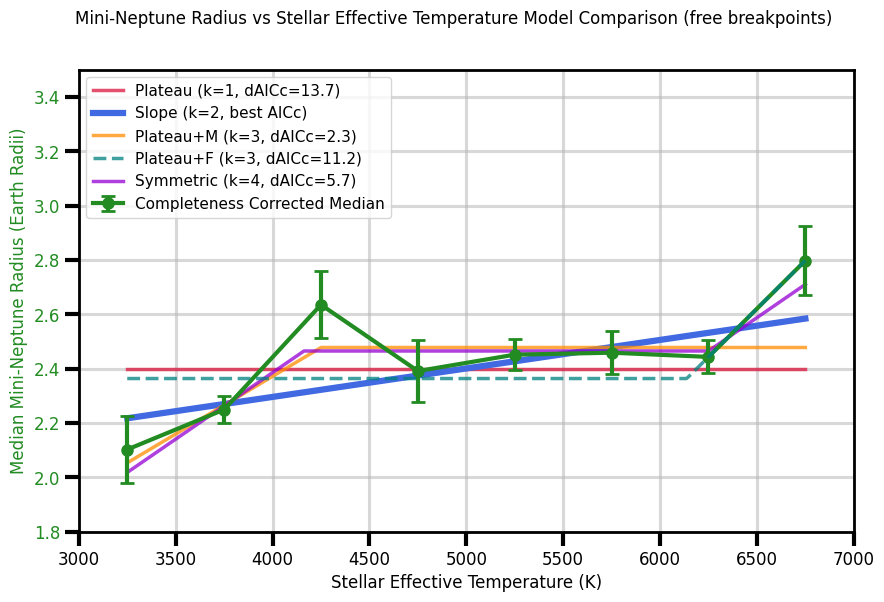

In [54]:
#### RADIUS vs TEFF: MODEL FITS + AIC/AICc/BIC ####

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Temperature bins and bootstrap settings
bins_teff_fit = [3000, 3500, 4000, 4500, 5000, 5500, 6000, 6500, 7000]
n_bootstrap_fit = 1000
rng = np.random.default_rng(11)
#merged_df = merged_df[merged_df['st_tmag'] < 13]
#print(merged_df.columns)
print(len(merged_df))
# Weighted median: value where the sorted cumulative weight passes half
def wmedian(vals, weights):
    vals = np.asarray(vals, dtype=float)
    weights = np.asarray(weights, dtype=float)
    keep = np.isfinite(vals) & np.isfinite(weights) & (weights > 0)
    if keep.sum() == 0:
        return np.nan
    vals, weights = vals[keep], weights[keep]
    order = np.argsort(vals)
    vals, weights = vals[order], weights[order]
    return float(vals[np.searchsorted(np.cumsum(weights), 0.5 * weights.sum())])


# Completeness-corrected median radius in each Teff bin.
# Each planet's `weight` says how many planets it represents, so the median is
# weighted. Errors come from bootstrap resampling the planets in the bin.
planets = merged_df.dropna(subset=['st_teff', 'pl_rade', 'weight'])

centers = []
medians = []
errors = []

for i in range(len(bins_teff_fit) - 1):
    bin_mask = (planets['st_teff'] >= bins_teff_fit[i]) & (planets['st_teff'] < bins_teff_fit[i + 1])
    radii = planets.loc[bin_mask, 'pl_rade'].values
    weights = planets.loc[bin_mask, 'weight'].values
    bin_center = (bins_teff_fit[i] + bins_teff_fit[i + 1]) / 2

    if len(radii) == 0 or np.nansum(weights) <= 0:
        centers.append(bin_center)
        medians.append(np.nan)
        errors.append(np.nan)
        continue

    bootstrap_medians = []
    for _ in range(n_bootstrap_fit):
        pick = rng.integers(0, len(radii), size=len(radii))
        bootstrap_medians.append(wmedian(radii[pick], weights[pick]))

    median = wmedian(radii, weights)
    error = np.nanstd(bootstrap_medians)

    print(f"Teff {bins_teff_fit[i]}-{bins_teff_fit[i+1]} K: N={len(radii)}, "
          f"Median={median:.2f}, Error={error:.3f} R_Earth")

    centers.append(bin_center)
    medians.append(median)
    errors.append(error)

centers = np.array(centers)
medians = np.array(medians)
errors = np.array(errors)

# Keep only bins with a usable median and error
good = ~(np.isnan(medians) | np.isnan(errors) | (errors == 0))
x = centers[good]
y = medians[good]
yerr = errors[good]
n_bins = len(y)


x_min = x.min()
x_max = x.max()
x_span = x_max - x_min
slope_guess = (y[-1] - y[0]) / x_span
median_guess = np.median(y)

# The five models. All are continuous: c is the plateau level, and it is also
# the value at the breakpoint, so the segments join without extra parameters.
def plateau(x, c):
    return np.full_like(np.asarray(x, dtype=float), c)


def slope(x, y0, s):
    return y0 + s * (np.asarray(x, dtype=float) - x_min)


def plateau_M(x, c, x1, s1):
    # Rises with slope s1 below x1, flat at c above it
    x = np.asarray(x, dtype=float)
    return np.where(x < x1, c + s1 * (x - x1), c)


def plateau_F(x, c, x2, s2):
    # Flat at c below x2, rises with slope s2 above it
    x = np.asarray(x, dtype=float)
    return np.where(x > x2, c + s2 * (x - x2), c)


def symmetric(x, c, x1, x2, s):
    # Rise, then flat between x1 and x2, then rise again with the same slope
    x = np.asarray(x, dtype=float)
    return np.select(
        [x < x1, (x >= x1) & (x <= x2), x > x2],
        [c + s * (x - x1), np.full_like(x, c), c + s * (x - x2)],
    )


# Breakpoint models get several starting guesses because their chi2 surface is
# multi-modal and one guess can land in a local minimum.
# Plateau+F is the F-side hypothesis: flat across M, K and G, rising only at the
# hot end. Its breakpoint is held above 5500 K to keep it that model. Left free it
# slides down to the first bin, the plateau covers no data, and it collapses into
# Slope with a wasted parameter. It is also drawn dashed and last so that where it
# does overlap another model the dashes stay visible.
plateau_F_min_break = 5500.0

models = {
    'Plateau': {
        'func': plateau,
        'k': 1,
        'guesses': [[median_guess]],
        'bounds': (-np.inf, np.inf),
        'color': 'crimson',
        'linestyle': '-',
        'zorder': 3,
    },
    'Slope': {
        'func': slope,
        'k': 2,
        'guesses': [[y[0], slope_guess]],
        'bounds': (-np.inf, np.inf),
        'color': 'royalblue',
        'linestyle': '-',
        'zorder': 4,
    },
    'Plateau+M': {
        'func': plateau_M,
        'k': 3,
        'guesses': [[median_guess, x_min + f * x_span, slope_guess]
                    for f in (0.2, 0.35, 0.5, 0.65, 0.8)],
        'bounds': ([-np.inf, x_min, -np.inf], [np.inf, x_max, np.inf]),
        'color': 'darkorange',
        'linestyle': '-',
        'zorder': 5,
    },
    'Plateau+F': {
        'func': plateau_F,
        'k': 3,
        'guesses': [[median_guess, plateau_F_min_break + f * (x_max - plateau_F_min_break),
                     slope_guess] for f in (0.0, 0.2, 0.4, 0.6, 0.8)],
        'bounds': ([-np.inf, plateau_F_min_break, -np.inf], [np.inf, x_max, np.inf]),
        'color': 'teal',
        'linestyle': '--',
        'zorder': 7,
    },
    'Symmetric': {
        'func': symmetric,
        'k': 4,
        'guesses': [[median_guess, x_min + a * x_span, x_min + b * x_span, slope_guess]
                    for a, b in ((0.2, 0.8), (0.3, 0.7), (0.15, 0.55),
                                 (0.45, 0.85), (0.35, 0.6))],
        'bounds': ([-np.inf, x_min, x_min, -np.inf], [np.inf, x_max, x_max, np.inf]),
        'color': 'darkviolet',
        'linestyle': '-',
        'zorder': 6,
    },
}

# Fit each model, keeping the starting guess that gives the lowest chi2
for name, model in models.items():
    best_chi2 = np.inf
    best_params = None

    for guess in model['guesses']:
        try:
            params, _ = curve_fit(model['func'], x, y, p0=guess, sigma=yerr,
                                  absolute_sigma=True, bounds=model['bounds'], maxfev=40000)
        except Exception:
            continue
        # Symmetric can fit crossed breakpoints, which are meaningless
        if name == 'Symmetric' and params[1] > params[2]:
            continue
        chi2 = np.sum(((y - model['func'](x, *params)) / yerr) ** 2)
        if chi2 < best_chi2:
            best_chi2 = chi2
            best_params = params

    k = model['k']
    model['chi2'] = best_chi2
    model['params'] = best_params
    model['AIC'] = best_chi2 + 2 * k
    # AICc corrects AIC for small samples. With n=8 bins and up to k=4 it is the
    # one to read: plain AIC under-penalises complex models unless n/k > 40.
    model['AICc'] = model['AIC'] + 2 * k * (k + 1) / (n_bins - k - 1)
    model['BIC'] = best_chi2 + k * np.log(n_bins)

best_aic = min(m['AIC'] for m in models.values())
best_aicc = min(m['AICc'] for m in models.values())
best_bic = min(m['BIC'] for m in models.values())
best_model = min(models, key=lambda name: models[name]['AICc'])

print(f"\nRadius vs Teff, {n_bins} bins, all breakpoints fitted")
print("=" * 74)
print(f"{'Model':<12}{'k':>3}{'chi2':>9}{'dof':>5}{'red.chi2':>10}{'AIC':>9}{'AICc':>9}{'BIC':>9}")
print("-" * 74)
for name, model in models.items():
    dof = n_bins - model['k']
    print(f"{name:<12}{model['k']:>3}{model['chi2']:>9.3f}{dof:>5}{model['chi2']/dof:>10.3f}"
          f"{model['AIC']:>9.3f}{model['AICc']:>9.3f}{model['BIC']:>9.3f}")

# Akaike weights: relative likelihood of each model, normalised to sum to 1
raw_weights = {name: np.exp(-0.5 * (model['AICc'] - best_aicc)) for name, model in models.items()}
weight_sum = sum(raw_weights.values())

print(f"\n{'Model':<12}{'dAIC':>9}{'dAICc':>9}{'dBIC':>9}{'weight':>9}")
print("-" * 48)
for name in sorted(models, key=lambda name: models[name]['AICc']):
    model = models[name]
    print(f"{name:<12}{model['AIC']-best_aic:>9.3f}{model['AICc']-best_aicc:>9.3f}"
          f"{model['BIC']-best_bic:>9.3f}{raw_weights[name]/weight_sum:>9.3f}")

print(f"\nBest by AIC:  {min(models, key=lambda name: models[name]['AIC'])}")
print(f"Best by AICc: {best_model}   <- use this one")
print(f"Best by BIC:  {min(models, key=lambda name: models[name]['BIC'])}")

print("\nBest fit parameters (slopes per 1000 K):")
print(f"  Plateau:    c={models['Plateau']['params'][0]:.3f}")
print(f"  Slope:      y0={models['Slope']['params'][0]:.3f}, "
      f"s={models['Slope']['params'][1]*1000:.4f}")
print(f"  Plateau+M:  c={models['Plateau+M']['params'][0]:.3f}, "
      f"x1={models['Plateau+M']['params'][1]:.0f} K, "
      f"s1={models['Plateau+M']['params'][2]*1000:.4f}")
print(f"  Plateau+F:  c={models['Plateau+F']['params'][0]:.3f}, "
      f"x2={models['Plateau+F']['params'][1]:.0f} K, "
      f"s2={models['Plateau+F']['params'][2]*1000:.4f}")
print(f"  Symmetric:  c={models['Symmetric']['params'][0]:.3f}, "
      f"x1={models['Symmetric']['params'][1]:.0f} K, "
      f"x2={models['Symmetric']['params'][2]:.0f} K, "
      f"s={models['Symmetric']['params'][3]*1000:.4f}")

print("\ndAICc < 2: models are indistinguishable, 4-7: clearly worse, >10: no support.")
print("Note: a fitted breakpoint buys more fit from noise than AICc charges for,")
print("so Plateau+M, Plateau+F and Symmetric are still mildly flattered.")


# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

# Individual planet radii as grey transparent dots
# ax.scatter(planets['st_teff'], planets['pl_rade'],
#            color='grey', alpha=0.25, s=20, zorder=1, label='Individual Planets')

# Model fits, with the AICc-preferred one drawn heavier
x_line = np.linspace(x_min, x_max, 400)
for name, model in models.items():
    is_best = name == best_model
    if is_best:
        label = f"{name} (k={model['k']}, best AICc)"
    else:
        label = f"{name} (k={model['k']}, dAICc={model['AICc']-best_aicc:.1f})"
    ax.plot(x_line, model['func'](x_line, *model['params']), color=model['color'],
            linestyle=model['linestyle'],
            linewidth=4.5 if is_best else 2.5, alpha=1.0 if is_best else 0.75,
            zorder=model['zorder'], label=label)

ax.errorbar(x, y, yerr=yerr, color='forestgreen', label='Completeness Corrected Median',
            marker='o', linestyle='-', markersize=8, linewidth=3, capsize=5,
            capthick=2, zorder=6)

ax.set_xlabel('Stellar Effective Temperature (K)', size=12)
ax.set_ylabel('Median Mini-Neptune Radius (Earth Radii)', color='forestgreen', size=12)
ax.tick_params(axis='y', labelcolor='forestgreen')
ax.set_ylim(1.8, 3.5)
ax.set_xlim(bins_teff_fit[0], bins_teff_fit[-1])

fig.suptitle('Mini-Neptune Radius vs Stellar Effective Temperature Model Comparison (free breakpoints)', size=12)
ax.legend(loc='upper left', fontsize=11)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
ax.tick_params(axis='both', which='minor', width=2, length=6, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)
plt.show()

fig.savefig('statistical_analysis_teff_presentation.png', dpi=300, bbox_inches='tight')


Plateau vs Plateau+F, 8 bins, breakpoint held above 5500 K
Model         k     chi2  dof  red.chi2      AIC     AICc      BIC
--------------------------------------------------------------------------
Plateau       1   30.301    7     4.329   32.301   32.968   32.381
Plateau+F     3   18.429    5     3.686   24.429   30.429   24.668

Model           dAICc     dBIC   weight
---------------------------------------
Plateau         2.539    7.713    0.219
Plateau+F       0.000    0.000    0.781

Preferred by AICc: Plateau+F

Best fit parameters (slopes per 1000 K):
  Plateau:    c=2.398
  Plateau+F:  c=2.364, x2=6138 K, s2=0.7092

chi2 drop from adding the break: 11.872 for 2 extra parameters
Breakpoint is interior at 6138 K, chosen by the data rather than by the bound.


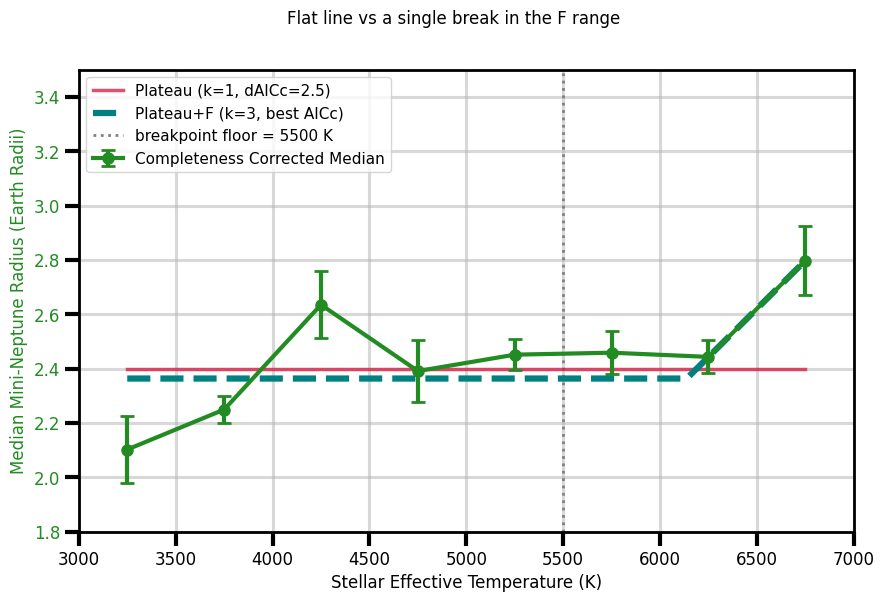

In [55]:
#### PLATEAU vs PLATEAU+F: DOES THE HOT END BREAK EARN ITS PARAMETERS? ####
# The five model comparison above is won by Slope, which hides what the F side
# break does on its own. This is the narrower question: against a flat line, is
# it worth letting the medians rise above a single breakpoint in the F range?
# The two models are nested, so the chi2 drop is reported as well, with the usual
# caveat that a breakpoint is not a regular parameter, so it should be read as
# descriptive rather than as a calibrated significance.
#
# Uses x, y, yerr, n_bins, plateau, plateau_F and plateau_F_min_break from the
# cell above.

pair = {
    'Plateau': {
        'func': plateau,
        'k': 1,
        'guesses': [[median_guess]],
        'bounds': (-np.inf, np.inf),
        'color': 'crimson',
        'linestyle': '-',
        'zorder': 3,
    },
    'Plateau+F': {
        'func': plateau_F,
        'k': 3,
        'guesses': [[median_guess, plateau_F_min_break + f * (x_max - plateau_F_min_break),
                     slope_guess] for f in (0.0, 0.2, 0.4, 0.6, 0.8)],
        'bounds': ([-np.inf, plateau_F_min_break, -np.inf], [np.inf, x_max, np.inf]),
        'color': 'teal',
        'linestyle': '--',
        'zorder': 4,
    },
}

# Fit each model, keeping the starting guess that gives the lowest chi2
for name, model in pair.items():
    best_chi2 = np.inf
    best_params = None

    for guess in model['guesses']:
        try:
            params, _ = curve_fit(model['func'], x, y, p0=guess, sigma=yerr,
                                  absolute_sigma=True, bounds=model['bounds'], maxfev=40000)
        except Exception:
            continue
        chi2 = np.sum(((y - model['func'](x, *params)) / yerr) ** 2)
        if chi2 < best_chi2:
            best_chi2 = chi2
            best_params = params

    k = model['k']
    model['chi2'] = best_chi2
    model['params'] = best_params
    model['AIC'] = best_chi2 + 2 * k
    model['AICc'] = model['AIC'] + 2 * k * (k + 1) / (n_bins - k - 1)
    model['BIC'] = best_chi2 + k * np.log(n_bins)

best_pair = min(pair, key=lambda name: pair[name]['AICc'])
best_aicc_pair = pair[best_pair]['AICc']
best_bic_pair = min(model['BIC'] for model in pair.values())

print(f"Plateau vs Plateau+F, {n_bins} bins, breakpoint held above "
      f"{plateau_F_min_break:.0f} K")
print("=" * 74)
print(f"{'Model':<12}{'k':>3}{'chi2':>9}{'dof':>5}{'red.chi2':>10}{'AIC':>9}{'AICc':>9}{'BIC':>9}")
print("-" * 74)
for name, model in pair.items():
    dof = n_bins - model['k']
    print(f"{name:<12}{model['k']:>3}{model['chi2']:>9.3f}{dof:>5}{model['chi2']/dof:>10.3f}"
          f"{model['AIC']:>9.3f}{model['AICc']:>9.3f}{model['BIC']:>9.3f}")

# Akaike weights over just these two models
raw_weights = {name: np.exp(-0.5 * (model['AICc'] - best_aicc_pair)) for name, model in pair.items()}
weight_sum = sum(raw_weights.values())

print(f"\n{'Model':<12}{'dAICc':>9}{'dBIC':>9}{'weight':>9}")
print("-" * 39)
for name, model in pair.items():
    print(f"{name:<12}{model['AICc']-best_aicc_pair:>9.3f}{model['BIC']-best_bic_pair:>9.3f}"
          f"{raw_weights[name]/weight_sum:>9.3f}")

print(f"\nPreferred by AICc: {best_pair}")

print("\nBest fit parameters (slopes per 1000 K):")
print(f"  Plateau:    c={pair['Plateau']['params'][0]:.3f}")
print(f"  Plateau+F:  c={pair['Plateau+F']['params'][0]:.3f}, "
      f"x2={pair['Plateau+F']['params'][1]:.0f} K, "
      f"s2={pair['Plateau+F']['params'][2]*1000:.4f}")

# Plateau is Plateau+F with the slope pinned to zero, so this is the whole cost
# of that restriction, bought with two extra parameters.
delta_chi2 = pair['Plateau']['chi2'] - pair['Plateau+F']['chi2']
print(f"\nchi2 drop from adding the break: {delta_chi2:.3f} for 2 extra parameters")

# Whether the breakpoint is chosen by the data or just sitting on its floor
x2_fit = pair['Plateau+F']['params'][1]
if np.isclose(x2_fit, plateau_F_min_break):
    print(f"Breakpoint is at the {plateau_F_min_break:.0f} K floor, so the fit is bounded, not chosen.")
else:
    print(f"Breakpoint is interior at {x2_fit:.0f} K, chosen by the data rather than by the bound.")


# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

x_line = np.linspace(x_min, x_max, 400)
for name, model in pair.items():
    is_best = name == best_pair
    if is_best:
        label = f"{name} (k={model['k']}, best AICc)"
    else:
        label = f"{name} (k={model['k']}, dAICc={model['AICc']-best_aicc_pair:.1f})"
    ax.plot(x_line, model['func'](x_line, *model['params']), color=model['color'],
            linestyle=model['linestyle'],
            linewidth=4.5 if is_best else 2.5, alpha=1.0 if is_best else 0.75,
            zorder=model['zorder'], label=label)

ax.axvline(plateau_F_min_break, color='grey', linestyle=':', linewidth=2, zorder=2,
           label=f'breakpoint floor = {plateau_F_min_break:.0f} K')

ax.errorbar(x, y, yerr=yerr, color='forestgreen', label='Completeness Corrected Median',
            marker='o', linestyle='-', markersize=8, linewidth=3, capsize=5,
            capthick=2, zorder=6)

ax.set_xlabel('Stellar Effective Temperature (K)', size=12)
ax.set_ylabel('Median Mini-Neptune Radius (Earth Radii)', color='forestgreen', size=12)
ax.tick_params(axis='y', labelcolor='forestgreen')
ax.set_ylim(1.8, 3.5)
ax.set_xlim(bins_teff_fit[0], bins_teff_fit[-1])

fig.suptitle('Flat line vs a single break in the F range', size=12)
ax.legend(loc='upper left', fontsize=11)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
ax.tick_params(axis='both', which='minor', width=2, length=6, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)
plt.show()

fig.savefig('statistical_analysis_teff_plateau_vs_plateau_F.png', dpi=300, bbox_inches='tight')

673
Teff 3000-3500 K: N=31, Median=2.10, Error=0.124 R_Earth
Teff 3500-4000 K: N=79, Median=2.25, Error=0.050 R_Earth
Teff 4000-4500 K: N=73, Median=2.64, Error=0.123 R_Earth
Teff 4500-5000 K: N=84, Median=2.39, Error=0.113 R_Earth
Teff 5000-5500 K: N=121, Median=2.45, Error=0.057 R_Earth
Teff 5500-6000 K: N=168, Median=2.46, Error=0.078 R_Earth
Teff 6000-6500 K: N=99, Median=2.44, Error=0.061 R_Earth
Teff 6500-7000 K: N=18, Median=2.80, Error=0.126 R_Earth

Radius vs Teff, 8 bins, upper breakpoint pinned at 6014 K (1.1 Msun)
Model         k     chi2  dof  red.chi2      AIC     AICc      BIC
--------------------------------------------------------------------------
Plateau       1   30.301    7     4.329   32.301   32.968   32.381
Slope         2   12.822    6     2.137   16.822   19.222   16.981
Plateau+M     3    9.535    5     1.907   15.535   21.535   15.773
Plateau+F     2   19.048    6     3.175   23.048   25.448   23.206
Symmetric     3    5.243    5     1.049   11.243   17.243 

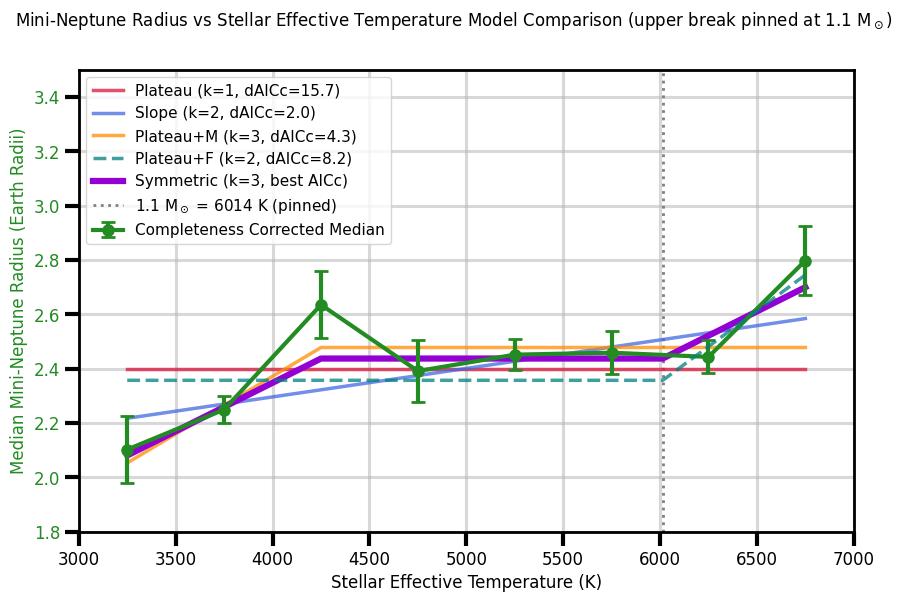

In [56]:
#### RADIUS vs TEFF: SECOND BREAKPOINT PINNED AT 1.1 SOLAR MASSES ####
# Same data, same fitting and same AIC/AICc/BIC as the cell above. The only
# change is the upper breakpoint of the Symmetric model: instead of being
# fitted it is pinned at the Teff of a 1.1 Msun dwarf, so that model drops from
# k=4 to k=3 and stops paying for a parameter we are choosing on physical
# grounds rather than reading off the data.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Upper breakpoint, pinned. 1.1 Msun interpolated onto the Mamajek (2022) dwarf
# sequence (mamajek_stellar_masses.txt, Msun vs Teff columns) gives 6014 K,
# between F9.5V (1.08 Msun, 5990 K) and F9V (1.13 Msun, 6050 K). The same
# interpolation reproduces the 4440 K / 6475 K used for 0.7 / 1.3 Msun earlier.
teff_1p1_msun = 6014.0

# Temperature bins and bootstrap settings
bins_teff_fit = [3000, 3500, 4000, 4500, 5000, 5500, 6000, 6500, 7000]
n_bootstrap_fit = 1000
rng = np.random.default_rng(11)
#merged_df = merged_df[merged_df['st_tmag'] < 13]
#print(merged_df.columns)
print(len(merged_df))
# Weighted median: value where the sorted cumulative weight passes half
def wmedian(vals, weights):
    vals = np.asarray(vals, dtype=float)
    weights = np.asarray(weights, dtype=float)
    keep = np.isfinite(vals) & np.isfinite(weights) & (weights > 0)
    if keep.sum() == 0:
        return np.nan
    vals, weights = vals[keep], weights[keep]
    order = np.argsort(vals)
    vals, weights = vals[order], weights[order]
    return float(vals[np.searchsorted(np.cumsum(weights), 0.5 * weights.sum())])


# Completeness-corrected median radius in each Teff bin.
# Each planet's `weight` says how many planets it represents, so the median is
# weighted. Errors come from bootstrap resampling the planets in the bin.
planets = merged_df.dropna(subset=['st_teff', 'pl_rade', 'weight'])

centers = []
medians = []
errors = []

for i in range(len(bins_teff_fit) - 1):
    bin_mask = (planets['st_teff'] >= bins_teff_fit[i]) & (planets['st_teff'] < bins_teff_fit[i + 1])
    radii = planets.loc[bin_mask, 'pl_rade'].values
    weights = planets.loc[bin_mask, 'weight'].values
    bin_center = (bins_teff_fit[i] + bins_teff_fit[i + 1]) / 2

    if len(radii) == 0 or np.nansum(weights) <= 0:
        centers.append(bin_center)
        medians.append(np.nan)
        errors.append(np.nan)
        continue

    bootstrap_medians = []
    for _ in range(n_bootstrap_fit):
        pick = rng.integers(0, len(radii), size=len(radii))
        bootstrap_medians.append(wmedian(radii[pick], weights[pick]))

    median = wmedian(radii, weights)
    error = np.nanstd(bootstrap_medians)

    print(f"Teff {bins_teff_fit[i]}-{bins_teff_fit[i+1]} K: N={len(radii)}, "
          f"Median={median:.2f}, Error={error:.3f} R_Earth")

    centers.append(bin_center)
    medians.append(median)
    errors.append(error)

centers = np.array(centers)
medians = np.array(medians)
errors = np.array(errors)

# Keep only bins with a usable median and error
good = ~(np.isnan(medians) | np.isnan(errors) | (errors == 0))
x = centers[good]
y = medians[good]
yerr = errors[good]
n_bins = len(y)


x_min = x.min()
x_max = x.max()
x_span = x_max - x_min
slope_guess = (y[-1] - y[0]) / x_span
median_guess = np.median(y)

# The five models. All are continuous: c is the plateau level, and it is also
# the value at the breakpoint, so the segments join without extra parameters.
def plateau(x, c):
    return np.full_like(np.asarray(x, dtype=float), c)


def slope(x, y0, s):
    return y0 + s * (np.asarray(x, dtype=float) - x_min)


def plateau_M(x, c, x1, s1):
    # Rises with slope s1 below x1, flat at c above it
    x = np.asarray(x, dtype=float)
    return np.where(x < x1, c + s1 * (x - x1), c)


def plateau_F_pinned(x, c, s):
    # Flat at c up to the pinned break, then rises with slope s above it. No
    # lower breakpoint, so this is Symmetric with the M side rise taken out.
    x = np.asarray(x, dtype=float)
    x2 = teff_1p1_msun
    return np.where(x > x2, c + s * (x - x2), c)


def symmetric_pinned(x, c, x1, s):
    # Rise, then flat between x1 and teff_1p1_msun, then rise again with the
    # same slope. Only x1 is fitted; the upper break is held at 1.1 Msun.
    x = np.asarray(x, dtype=float)
    x2 = teff_1p1_msun
    return np.select(
        [x < x1, (x >= x1) & (x <= x2), x > x2],
        [c + s * (x - x1), np.full_like(x, c), c + s * (x - x2)],
    )


# Breakpoint models get several starting guesses because their chi2 surface is
# multi-modal and one guess can land in a local minimum.
models = {
    'Plateau': {
        'func': plateau,
        'k': 1,
        'guesses': [[median_guess]],
        'bounds': (-np.inf, np.inf),
        'color': 'crimson',
        'linestyle': '-',
        'zorder': 3,
    },
    'Slope': {
        'func': slope,
        'k': 2,
        'guesses': [[y[0], slope_guess]],
        'bounds': (-np.inf, np.inf),
        'color': 'royalblue',
        'linestyle': '-',
        'zorder': 4,
    },
    'Plateau+M': {
        'func': plateau_M,
        'k': 3,
        'guesses': [[median_guess, x_min + f * x_span, slope_guess]
                    for f in (0.2, 0.35, 0.5, 0.65, 0.8)],
        'bounds': ([-np.inf, x_min, -np.inf], [np.inf, x_max, np.inf]),
        'color': 'darkorange',
        'linestyle': '-',
        'zorder': 5,
    },
    'Plateau+F': {
        'func': plateau_F_pinned,
        'k': 2,
        'guesses': [[median_guess, slope_guess]],
        'bounds': (-np.inf, np.inf),
        'color': 'teal',
        'linestyle': '--',
        'zorder': 7,
    },
    'Symmetric': {
        'func': symmetric_pinned,
        'k': 3,
        # x1 is bounded above by the pinned break so the two cannot cross
        'guesses': [[median_guess, x_min + f * (teff_1p1_msun - x_min), slope_guess]
                    for f in (0.2, 0.35, 0.5, 0.65, 0.8)],
        'bounds': ([-np.inf, x_min, -np.inf], [np.inf, teff_1p1_msun, np.inf]),
        'color': 'darkviolet',
        'linestyle': '-',
        'zorder': 6,
    },
}

# Fit each model, keeping the starting guess that gives the lowest chi2
for name, model in models.items():
    best_chi2 = np.inf
    best_params = None

    for guess in model['guesses']:
        try:
            params, _ = curve_fit(model['func'], x, y, p0=guess, sigma=yerr,
                                  absolute_sigma=True, bounds=model['bounds'], maxfev=40000)
        except Exception:
            continue
        chi2 = np.sum(((y - model['func'](x, *params)) / yerr) ** 2)
        if chi2 < best_chi2:
            best_chi2 = chi2
            best_params = params

    k = model['k']
    model['chi2'] = best_chi2
    model['params'] = best_params
    model['AIC'] = best_chi2 + 2 * k
    # AICc corrects AIC for small samples. With n=8 bins and up to k=4 it is the
    # one to read: plain AIC under-penalises complex models unless n/k > 40.
    model['AICc'] = model['AIC'] + 2 * k * (k + 1) / (n_bins - k - 1)
    model['BIC'] = best_chi2 + k * np.log(n_bins)

best_aic = min(m['AIC'] for m in models.values())
best_aicc = min(m['AICc'] for m in models.values())
best_bic = min(m['BIC'] for m in models.values())
best_model = min(models, key=lambda name: models[name]['AICc'])

print(f"\nRadius vs Teff, {n_bins} bins, upper breakpoint pinned at "
      f"{teff_1p1_msun:.0f} K (1.1 Msun)")
print("=" * 74)
print(f"{'Model':<12}{'k':>3}{'chi2':>9}{'dof':>5}{'red.chi2':>10}{'AIC':>9}{'AICc':>9}{'BIC':>9}")
print("-" * 74)
for name, model in models.items():
    dof = n_bins - model['k']
    print(f"{name:<12}{model['k']:>3}{model['chi2']:>9.3f}{dof:>5}{model['chi2']/dof:>10.3f}"
          f"{model['AIC']:>9.3f}{model['AICc']:>9.3f}{model['BIC']:>9.3f}")

# Akaike weights: relative likelihood of each model, normalised to sum to 1
raw_weights = {name: np.exp(-0.5 * (model['AICc'] - best_aicc)) for name, model in models.items()}
weight_sum = sum(raw_weights.values())

print(f"\n{'Model':<12}{'dAIC':>9}{'dAICc':>9}{'dBIC':>9}{'weight':>9}")
print("-" * 48)
for name in sorted(models, key=lambda name: models[name]['AICc']):
    model = models[name]
    print(f"{name:<12}{model['AIC']-best_aic:>9.3f}{model['AICc']-best_aicc:>9.3f}"
          f"{model['BIC']-best_bic:>9.3f}{raw_weights[name]/weight_sum:>9.3f}")

print(f"\nBest by AIC:  {min(models, key=lambda name: models[name]['AIC'])}")
print(f"Best by AICc: {best_model}   <- use this one")
print(f"Best by BIC:  {min(models, key=lambda name: models[name]['BIC'])}")

print("\nBest fit parameters (slopes per 1000 K):")
print(f"  Plateau:    c={models['Plateau']['params'][0]:.3f}")
print(f"  Slope:      y0={models['Slope']['params'][0]:.3f}, "
      f"s={models['Slope']['params'][1]*1000:.4f}")
print(f"  Plateau+M:  c={models['Plateau+M']['params'][0]:.3f}, "
      f"x1={models['Plateau+M']['params'][1]:.0f} K, "
      f"s1={models['Plateau+M']['params'][2]*1000:.4f}")
print(f"  Plateau+F:  c={models['Plateau+F']['params'][0]:.3f}, "
      f"x2={teff_1p1_msun:.0f} K (pinned), "
      f"s={models['Plateau+F']['params'][1]*1000:.4f}")
print(f"  Symmetric:  c={models['Symmetric']['params'][0]:.3f}, "
      f"x1={models['Symmetric']['params'][1]:.0f} K, "
      f"x2={teff_1p1_msun:.0f} K (pinned), "
      f"s={models['Symmetric']['params'][2]*1000:.4f}")

print("\ndAICc < 2: models are indistinguishable, 4-7: clearly worse, >10: no support.")
print("Note: pinning the upper break is only honest if 1.1 Msun was chosen before")
print("looking at the fit. Plateau+M still fits its breakpoint, so it keeps the")
print("usual caveat: a searched-for break buys more fit from noise than AICc charges.")


# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

# Individual planet radii as grey transparent dots
# ax.scatter(planets['st_teff'], planets['pl_rade'],
#            color='grey', alpha=0.25, s=20, zorder=1, label='Individual Planets')

# Model fits, with the AICc-preferred one drawn heavier
x_line = np.linspace(x_min, x_max, 400)
for name, model in models.items():
    is_best = name == best_model
    if is_best:
        label = f"{name} (k={model['k']}, best AICc)"
    else:
        label = f"{name} (k={model['k']}, dAICc={model['AICc']-best_aicc:.1f})"
    ax.plot(x_line, model['func'](x_line, *model['params']), color=model['color'],
            linestyle=model['linestyle'],
            linewidth=4.5 if is_best else 2.5, alpha=1.0 if is_best else 0.75,
            zorder=model['zorder'], label=label)

# Mark the pinned breakpoint
ax.axvline(teff_1p1_msun, color='grey', linestyle=':', linewidth=2, zorder=2,
           label=f'1.1 M$_\\odot$ = {teff_1p1_msun:.0f} K (pinned)')

ax.errorbar(x, y, yerr=yerr, color='forestgreen', label='Completeness Corrected Median',
            marker='o', linestyle='-', markersize=8, linewidth=3, capsize=5,
            capthick=2, zorder=6)

ax.set_xlabel('Stellar Effective Temperature (K)', size=12)
ax.set_ylabel('Median Mini-Neptune Radius (Earth Radii)', color='forestgreen', size=12)
ax.tick_params(axis='y', labelcolor='forestgreen')
ax.set_ylim(1.8, 3.5)
ax.set_xlim(bins_teff_fit[0], bins_teff_fit[-1])

fig.suptitle('Mini-Neptune Radius vs Stellar Effective Temperature Model Comparison'
             ' (upper break pinned at 1.1 M$_\\odot$)', size=12)
ax.legend(loc='upper left', fontsize=11)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
ax.tick_params(axis='both', which='minor', width=2, length=6, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)
plt.show()

fig.savefig('statistical_analysis_teff_x2_pinned.png', dpi=300, bbox_inches='tight')


1. SENSITIVITY TO THE PINNED BREAKPOINT
   Bar to clear: Slope at AICc = 19.222
   Swept x2 from 5600 to 6800 K
   Symmetric preferred for x2 = 5850 - 6600 K (63% of the swept range)
   dAICc at the 1.1 Msun pin (6014 K): -1.978
   worst dAICc inside the winning range: -0.040

2. PROFILE LIKELIHOOD ON A FREE x2
   best fit x2 = 6250 K   (chi2 = 3.574)
   dchi2 < 1.00 (68%): 6100 - 6375 K
   dchi2 < 2.71 (90%): 5925 - 6525 K
   1.1 Msun = 6014 K inside the 68% interval? no
   Teff bin width = 500 K, so x2 cannot be localised better than about +/- 250 K no matter what the fit says.
   Caveat: the dchi2 thresholds assume a regular parameter. A breakpoint
   is not one, so read these as indicative, not exact coverage.


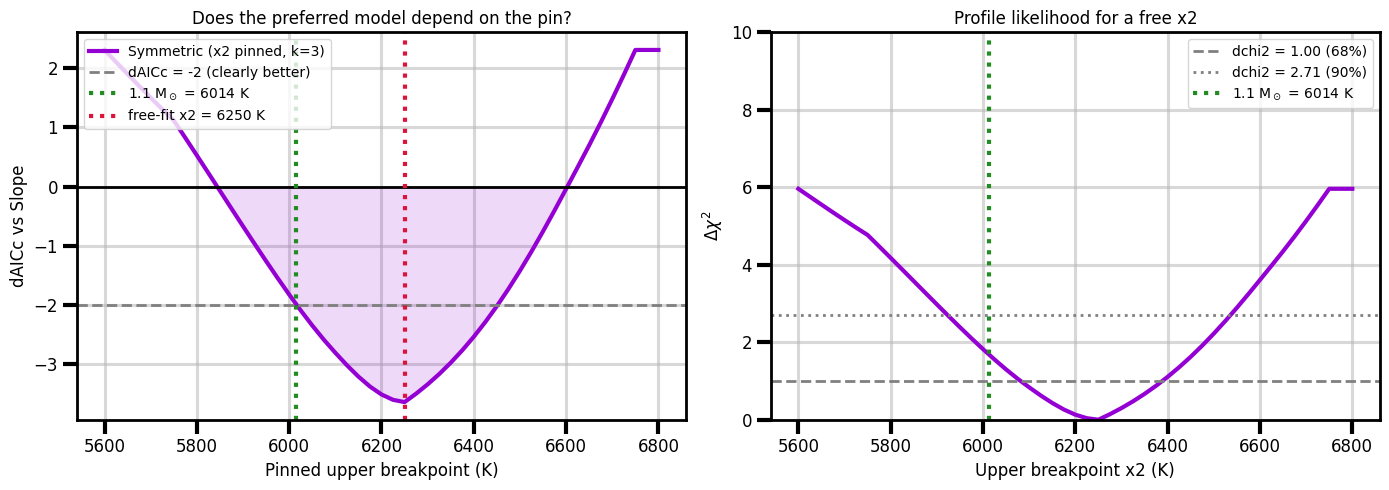

In [38]:
#### HOW MUCH DOES THE PINNED BREAKPOINT MATTER? ####
# Two checks on the 1.1 Msun (6014 K) pin used in the cell above, both aimed at
# the obvious referee question: the pin was read by eye off Fig. 18 of Johnstone
# et al. (2021), and it happens to land next to the 6250 K the free fit chose.
#
#   1. SENSITIVITY. Sweep the pinned x2 across the physically plausible range and
#      ask whether Symmetric stays the preferred model. If it wins everywhere,
#      the exact pin does not matter and the by-eye estimate is harmless. If it
#      only wins in a narrow window around the free-fit optimum, the result is an
#      artefact of the choice and should not be reported as support for a break.
#
#   2. PROFILE LIKELIHOOD. Let x2 be free (the k=4 model) and scan it, refitting
#      c, x1 and s at each step. The chi2 curve gives a confidence interval on
#      x2, which says how well the data localise the break at all, and whether
#      the independent physical value sits inside it.
#
# Both come from the same loop: fitting c, x1, s with x2 held at a value IS the
# pinned model, and collecting those chi2 values across x2 IS the profile.
#
# Uses x, y, yerr and the model functions from the cell above (seeded, so the
# binned points are reproducible).

teff_1p1_msun = 6014.0                      # 1.1 Msun on the Mamajek (2022) sequence
x2_scan = np.arange(5600, 6801, 25.0)       # plausible range for the upper break

# Bin width sets a floor on how well any breakpoint can be located: with 500 K
# bins, x2 cannot be pinned down better than about +/- 250 K, so anything finer
# than that is false precision.
bin_width = bins_teff_fit[1] - bins_teff_fit[0]


# Symmetric with x2 held at a chosen value. Returns a function of (x, c, x1, s),
# so curve_fit sees a k=3 model for each value of the pinned break.
def make_symmetric_at(x2_fixed):
    def model(x, c, x1, s):
        x = np.asarray(x, dtype=float)
        return np.select(
            [x < x1, (x >= x1) & (x <= x2_fixed), x > x2_fixed],
            [c + s * (x - x1), np.full_like(x, c), c + s * (x - x2_fixed)],
        )
    return model


# Fit c, x1, s for every candidate x2
scan_chi2 = []
scan_x1 = []

for x2_fixed in x2_scan:
    model_func = make_symmetric_at(x2_fixed)
    best_chi2 = np.inf
    best_params = None

    for f in (0.2, 0.35, 0.5, 0.65, 0.8):
        guess = [median_guess, x_min + f * (x2_fixed - x_min), slope_guess]
        try:
            params, _ = curve_fit(model_func, x, y, p0=guess, sigma=yerr,
                                  absolute_sigma=True, maxfev=40000,
                                  bounds=([-np.inf, x_min, -np.inf],
                                          [np.inf, x2_fixed, np.inf]))
        except Exception:
            continue
        chi2 = np.sum(((y - model_func(x, *params)) / yerr) ** 2)
        if chi2 < best_chi2:
            best_chi2 = chi2
            best_params = params

    scan_chi2.append(best_chi2)
    scan_x1.append(best_params[1])

scan_chi2 = np.array(scan_chi2)
scan_x1 = np.array(scan_x1)

# With x2 pinned the model has k=3; with x2 free it has k=4.
aicc_pinned = scan_chi2 + 2 * 3 + 2 * 3 * 4 / (n_bins - 3 - 1)
aicc_free = scan_chi2 + 2 * 4 + 2 * 4 * 5 / (n_bins - 4 - 1)

# Best of the models that do not involve x2 at all. These are unchanged by the
# sweep, so they are the bar Symmetric has to clear at every x2.
rival_aicc = min(models[name]['AICc'] for name in ['Plateau', 'Slope', 'Plateau+M'])
rival_name = min(['Plateau', 'Slope', 'Plateau+M'], key=lambda name: models[name]['AICc'])

delta_aicc = aicc_pinned - rival_aicc       # negative means Symmetric is preferred
wins = x2_scan[delta_aicc < 0]

print("1. SENSITIVITY TO THE PINNED BREAKPOINT")
print(f"   Bar to clear: {rival_name} at AICc = {rival_aicc:.3f}")
print(f"   Swept x2 from {x2_scan[0]:.0f} to {x2_scan[-1]:.0f} K")
if len(wins) == 0:
    print("   Symmetric is NOT preferred anywhere in this range.")
else:
    print(f"   Symmetric preferred for x2 = {wins.min():.0f} - {wins.max():.0f} K "
          f"({100 * len(wins) / len(x2_scan):.0f}% of the swept range)")
    print(f"   dAICc at the 1.1 Msun pin ({teff_1p1_msun:.0f} K): "
          f"{np.interp(teff_1p1_msun, x2_scan, delta_aicc):+.3f}")
    print(f"   worst dAICc inside the winning range: {delta_aicc[delta_aicc < 0].max():+.3f}")

# Profile likelihood: treat x2 as a fitted parameter and read off its interval
chi2_min = scan_chi2.min()
x2_best = x2_scan[np.argmin(scan_chi2)]
inside_1 = x2_scan[scan_chi2 - chi2_min <= 1.0]         # ~68% for one parameter
inside_2 = x2_scan[scan_chi2 - chi2_min <= 2.71]        # ~90% for one parameter

print("\n2. PROFILE LIKELIHOOD ON A FREE x2")
print(f"   best fit x2 = {x2_best:.0f} K   (chi2 = {chi2_min:.3f})")
print(f"   dchi2 < 1.00 (68%): {inside_1.min():.0f} - {inside_1.max():.0f} K")
print(f"   dchi2 < 2.71 (90%): {inside_2.min():.0f} - {inside_2.max():.0f} K")
print(f"   1.1 Msun = {teff_1p1_msun:.0f} K inside the 68% interval? "
      f"{'yes' if inside_1.min() <= teff_1p1_msun <= inside_1.max() else 'no'}")
print(f"   Teff bin width = {bin_width:.0f} K, so x2 cannot be localised "
      f"better than about +/- {bin_width/2:.0f} K no matter what the fit says.")
print("   Caveat: the dchi2 thresholds assume a regular parameter. A breakpoint")
print("   is not one, so read these as indicative, not exact coverage.")


# Create the plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: does the model choice survive a different pin?
ax = axes[0]
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)
ax.plot(x2_scan, delta_aicc, color='darkviolet', linewidth=3,
        label='Symmetric (x2 pinned, k=3)')
ax.axhline(0, color='black', linewidth=2, linestyle='-')
ax.axhline(-2, color='grey', linewidth=2, linestyle='--',
           label='dAICc = -2 (clearly better)')
ax.fill_between(x2_scan, delta_aicc, 0, where=(delta_aicc < 0),
                color='darkviolet', alpha=0.15)
ax.axvline(teff_1p1_msun, color='forestgreen', linewidth=3, linestyle=':',
           label=f'1.1 M$_\\odot$ = {teff_1p1_msun:.0f} K')
ax.axvline(x2_best, color='crimson', linewidth=3, linestyle=':',
           label=f'free-fit x2 = {x2_best:.0f} K')
ax.set_xlabel('Pinned upper breakpoint (K)', size=12)
ax.set_ylabel(f'dAICc vs {rival_name}', size=12)
ax.set_title('Does the preferred model depend on the pin?', size=12)
ax.legend(fontsize=10, loc='upper left')

# Right: how well do the data locate the break on their own?
ax = axes[1]
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)
ax.plot(x2_scan, scan_chi2 - chi2_min, color='darkviolet', linewidth=3)
ax.axhline(1.0, color='grey', linewidth=2, linestyle='--', label='dchi2 = 1.00 (68%)')
ax.axhline(2.71, color='grey', linewidth=2, linestyle=':', label='dchi2 = 2.71 (90%)')
ax.axvline(teff_1p1_msun, color='forestgreen', linewidth=3, linestyle=':',
           label=f'1.1 M$_\\odot$ = {teff_1p1_msun:.0f} K')
ax.set_xlabel('Upper breakpoint x2 (K)', size=12)
ax.set_ylabel(r'$\Delta\chi^2$', size=12)
ax.set_title('Profile likelihood for a free x2', size=12)
ax.set_ylim(0, 10)
ax.legend(fontsize=10)

for ax in axes:
    ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
    ax.tick_params(axis='both', which='minor', width=2, length=6, labelsize=12)
    for spine in ax.spines.values():
        spine.set_linewidth(2)

plt.tight_layout()
plt.show()

fig.savefig('statistical_analysis_teff_x2_sensitivity.png', dpi=300, bbox_inches='tight')


M break models, 8 bins, all breakpoints fitted
Model         k     chi2  dof  red.chi2      AIC     AICc      BIC
--------------------------------------------------------------------------
Plateau+M     3    9.535    5     1.907   15.535   21.535   15.773
Slope+M       4    9.050    4     2.262   17.050   30.383   17.368
Symmetric     4    3.574    4     0.893   11.574   24.907   11.891

Model            dAIC    dAICc     dBIC   weight
------------------------------------------------
Plateau+M       3.961    0.000    3.882    0.835
Symmetric       0.000    3.372    0.000    0.155
Slope+M         5.476    8.849    5.476    0.010

Preferred by AICc: Plateau+M

Best fit parameters (slopes per 1000 K):
  Plateau+M:  c=2.478, x1=4250 K, s1=0.4246
  Slope+M:    c=2.437, x1=4250 K, s1=0.3585, s2=0.0316
  Symmetric:  c=2.465, x1=4161 K, x2=6250 K, s=0.4903

chi2 drops from Plateau+M (1 extra parameter each):
  Slope+M:    0.485
  Symmetric:  5.961

Breakpoints:
  Plateau+M   x1=4250 K   (inter

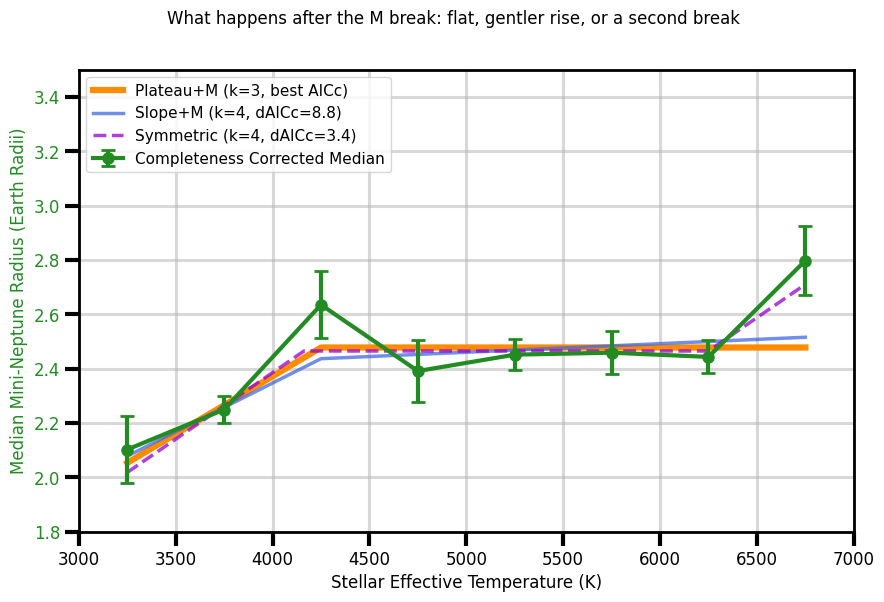

In [ ]:



#### M BREAK: PLATEAU vs SLOPE vs A SECOND BREAK IN F ####
# All three models agree that something changes on the M side and disagree only
# about what the curve does afterwards: it goes flat (Plateau+M), it keeps rising
# more gently (Slope+M), or it goes flat and then turns up again at a second
# break in the F range (Symmetric). Every breakpoint here is fitted, none pinned,
# so this compares the shapes rather than a choice of where to put the breaks.
#
# Plateau+M is nested inside both of the others -- Slope+M with s2 = 0, Symmetric
# with x2 pushed past the hottest bin -- so the chi2 drops at the bottom say what
# each extra parameter buys, with the usual caveat that a breakpoint is not a
# regular parameter and the drops should be read as descriptive.
#
# Uses x, y, yerr, n_bins, plateau_M, symmetric, median_guess, slope_guess,
# x_min, x_max and x_span from the fitting cell above.


def slope_M(x, c, x1, s1, s2):
    # Rises with slope s1 below x1, keeps rising with slope s2 above it
    x = np.asarray(x, dtype=float)
    return np.where(x < x1, c + s1 * (x - x1), c + s2 * (x - x1))


trio = {
    'Plateau+M': {
        'func': plateau_M,
        'k': 3,
        'guesses': [[median_guess, x_min + f * x_span, slope_guess]
                    for f in (0.2, 0.35, 0.5, 0.65, 0.8)],
        'bounds': ([-np.inf, x_min, -np.inf], [np.inf, x_max, np.inf]),
        'color': 'darkorange',
        'linestyle': '-',
        'zorder': 4,
    },
    'Slope+M': {
        'func': slope_M,
        'k': 4,
        'guesses': [[median_guess, x_min + f * x_span, slope_guess, slope_guess]
                    for f in (0.2, 0.35, 0.5, 0.65, 0.8)],
        'bounds': ([-np.inf, x_min, -np.inf, -np.inf], [np.inf, x_max, np.inf, np.inf]),
        'color': 'royalblue',
        'linestyle': '-',
        'zorder': 5,
    },
    'Symmetric': {
        'func': symmetric,
        'k': 4,
        'guesses': [[median_guess, x_min + a * x_span, x_min + b * x_span, slope_guess]
                    for a, b in ((0.2, 0.8), (0.3, 0.7), (0.15, 0.55),
                                 (0.45, 0.85), (0.35, 0.6))],
        'bounds': ([-np.inf, x_min, x_min, -np.inf], [np.inf, x_max, x_max, np.inf]),
        'color': 'darkviolet',
        'linestyle': '--',
        'zorder': 6,
    },
}

# Fit each model, keeping the starting guess that gives the lowest chi2
for name, model in trio.items():
    best_chi2 = np.inf
    best_params = None

    for guess in model['guesses']:
        try:
            params, _ = curve_fit(model['func'], x, y, p0=guess, sigma=yerr,
                                  absolute_sigma=True, bounds=model['bounds'], maxfev=40000)
        except Exception:
            continue
        # Symmetric can fit crossed breakpoints, which are meaningless
        if name == 'Symmetric' and params[1] > params[2]:
            continue
        chi2 = np.sum(((y - model['func'](x, *params)) / yerr) ** 2)
        if chi2 < best_chi2:
            best_chi2 = chi2
            best_params = params

    k = model['k']
    model['chi2'] = best_chi2
    model['params'] = best_params
    model['AIC'] = best_chi2 + 2 * k
    model['AICc'] = model['AIC'] + 2 * k * (k + 1) / (n_bins - k - 1)
    model['BIC'] = best_chi2 + k * np.log(n_bins)

best_trio = min(trio, key=lambda name: trio[name]['AICc'])
best_aicc_trio = trio[best_trio]['AICc']
best_aic_trio = min(model['AIC'] for model in trio.values())
best_bic_trio = min(model['BIC'] for model in trio.values())

print(f"M break models, {n_bins} bins, all breakpoints fitted")
print("=" * 74)
print(f"{'Model':<12}{'k':>3}{'chi2':>9}{'dof':>5}{'red.chi2':>10}{'AIC':>9}{'AICc':>9}{'BIC':>9}")
print("-" * 74)
for name, model in trio.items():
    dof = n_bins - model['k']
    print(f"{name:<12}{model['k']:>3}{model['chi2']:>9.3f}{dof:>5}{model['chi2']/dof:>10.3f}"
          f"{model['AIC']:>9.3f}{model['AICc']:>9.3f}{model['BIC']:>9.3f}")

# Akaike weights over just these three models
raw_weights = {name: np.exp(-0.5 * (model['AICc'] - best_aicc_trio)) for name, model in trio.items()}
weight_sum = sum(raw_weights.values())

print(f"\n{'Model':<12}{'dAIC':>9}{'dAICc':>9}{'dBIC':>9}{'weight':>9}")
print("-" * 48)
for name in sorted(trio, key=lambda name: trio[name]['AICc']):
    model = trio[name]
    print(f"{name:<12}{model['AIC']-best_aic_trio:>9.3f}{model['AICc']-best_aicc_trio:>9.3f}"
          f"{model['BIC']-best_bic_trio:>9.3f}{raw_weights[name]/weight_sum:>9.3f}")

print(f"\nPreferred by AICc: {best_trio}")

print("\nBest fit parameters (slopes per 1000 K):")
print(f"  Plateau+M:  c={trio['Plateau+M']['params'][0]:.3f}, "
      f"x1={trio['Plateau+M']['params'][1]:.0f} K, "
      f"s1={trio['Plateau+M']['params'][2]*1000:.4f}")
print(f"  Slope+M:    c={trio['Slope+M']['params'][0]:.3f}, "
      f"x1={trio['Slope+M']['params'][1]:.0f} K, "
      f"s1={trio['Slope+M']['params'][2]*1000:.4f}, "
      f"s2={trio['Slope+M']['params'][3]*1000:.4f}")
print(f"  Symmetric:  c={trio['Symmetric']['params'][0]:.3f}, "
      f"x1={trio['Symmetric']['params'][1]:.0f} K, "
      f"x2={trio['Symmetric']['params'][2]:.0f} K, "
      f"s={trio['Symmetric']['params'][3]*1000:.4f}")

# What the fourth parameter buys, relative to the flat-topped version
print("\nchi2 drops from Plateau+M (1 extra parameter each):")
print(f"  Slope+M:    {trio['Plateau+M']['chi2'] - trio['Slope+M']['chi2']:.3f}")
print(f"  Symmetric:  {trio['Plateau+M']['chi2'] - trio['Symmetric']['chi2']:.3f}")

# Whether the breakpoints are chosen by the data or just sitting on their bounds
print("\nBreakpoints:")
for name, model in trio.items():
    breaks = model['params'][1:3] if name == 'Symmetric' else model['params'][1:2]
    for i in range(len(breaks)):
        at_bound = np.isclose(breaks[i], x_min) or np.isclose(breaks[i], x_max)
        where = "on the bound, so bounded not chosen" if at_bound else "interior, chosen by the data"
        print(f"  {name:<12}x{i+1}={breaks[i]:.0f} K   ({where})")


# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

x_line = np.linspace(x_min, x_max, 400)
for name, model in trio.items():
    is_best = name == best_trio
    if is_best:
        label = f"{name} (k={model['k']}, best AICc)"
    else:
        label = f"{name} (k={model['k']}, dAICc={model['AICc']-best_aicc_trio:.1f})"
    ax.plot(x_line, model['func'](x_line, *model['params']), color=model['color'],
            linestyle=model['linestyle'],
            linewidth=4.5 if is_best else 2.5, alpha=1.0 if is_best else 0.75,
            zorder=model['zorder'], label=label)

ax.errorbar(x, y, yerr=yerr, color='forestgreen', label='Completeness Corrected Median',
            marker='o', linestyle='-', markersize=8, linewidth=3, capsize=5,
            capthick=2, zorder=7)

ax.set_xlabel('Stellar Effective Temperature (K)', size=12)
ax.set_ylabel('Median Mini-Neptune Radius (Earth Radii)', color='forestgreen', size=12)
ax.tick_params(axis='y', labelcolor='forestgreen')
ax.set_ylim(1.8, 3.5)
ax.set_xlim(bins_teff_fit[0], bins_teff_fit[-1])

fig.suptitle('What happens after the M break: flat, gentler rise, or a second break', size=12)
ax.legend(loc='upper left', fontsize=11)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
ax.tick_params(axis='both', which='minor', width=2, length=6, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)
plt.show()

fig.savefig('statistical_analysis_teff_M_break_comparison.png', dpi=300, bbox_inches='tight')


Plateau vs Plateau+M vs Symmetric, 8 bins, all breakpoints fitted
Model         k     chi2  dof  red.chi2      AIC     AICc      BIC
--------------------------------------------------------------------------
Plateau       1   30.301    7     4.329   32.301   32.968   32.381
Plateau+M     3    9.535    5     1.907   15.535   21.535   15.773
Symmetric     4    3.574    4     0.893   11.574   24.907   11.891

Model            dAIC    dAICc     dBIC   weight
------------------------------------------------
Plateau+M       3.961    0.000    3.882    0.841
Symmetric       0.000    3.372    0.000    0.156
Plateau        20.728   11.433   20.489    0.003

Preferred by AICc: Plateau+M

Best fit parameters (slopes per 1000 K):
  Plateau:    c=2.398
  Plateau+M:  c=2.478, x1=4250 K, s1=0.4246
  Symmetric:  c=2.465, x1=4161 K, x2=6250 K, s=0.4903

chi2 drops along the ladder:
  Plateau -> Plateau+M:    20.767 for 2 extra parameters
  Plateau+M -> Symmetric:  5.961 for 1 extra parameter

Breakpoint

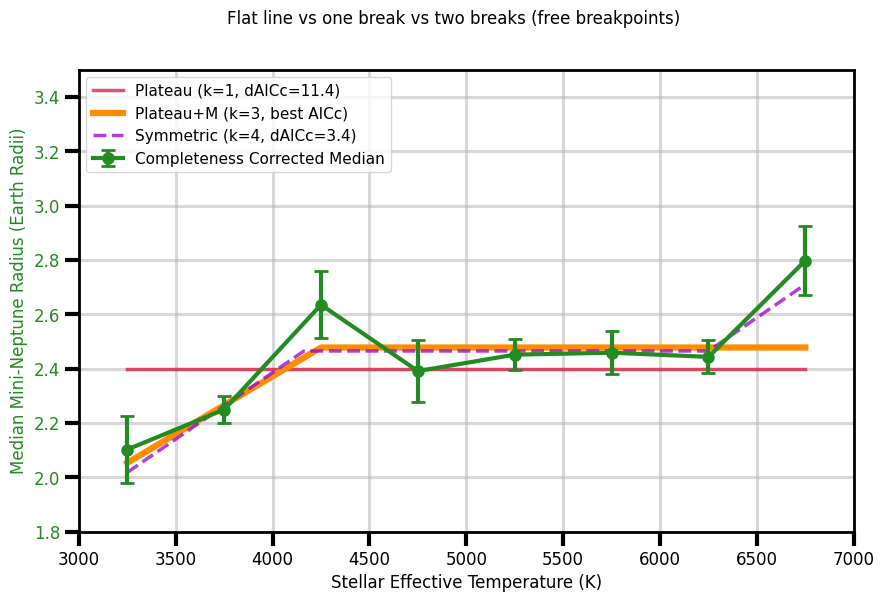

In [58]:
#### FLAT vs ONE BREAK vs TWO BREAKS ####
# The same question as the cell above but along the nesting instead of across it.
# These three are a ladder: Plateau is Plateau+M with s1 = 0, and Plateau+M is
# Symmetric with x2 pushed past the hottest bin. So each rung adds structure to
# the one below it and nothing else changes, and the chi2 drops at the bottom
# read as the cost of each restriction.
#
# Breakpoints are fitted, none pinned. Same caveat as before: a breakpoint is not
# a regular parameter, so the drops are descriptive rather than calibrated.
#
# Uses x, y, yerr, n_bins, plateau, plateau_M, symmetric, median_guess,
# slope_guess, x_min, x_max and x_span from the fitting cell above.

ladder = {
    'Plateau': {
        'func': plateau,
        'k': 1,
        'guesses': [[median_guess]],
        'bounds': (-np.inf, np.inf),
        'color': 'crimson',
        'linestyle': '-',
        'zorder': 4,
    },
    'Plateau+M': {
        'func': plateau_M,
        'k': 3,
        'guesses': [[median_guess, x_min + f * x_span, slope_guess]
                    for f in (0.2, 0.35, 0.5, 0.65, 0.8)],
        'bounds': ([-np.inf, x_min, -np.inf], [np.inf, x_max, np.inf]),
        'color': 'darkorange',
        'linestyle': '-',
        'zorder': 5,
    },
    'Symmetric': {
        'func': symmetric,
        'k': 4,
        'guesses': [[median_guess, x_min + a * x_span, x_min + b * x_span, slope_guess]
                    for a, b in ((0.2, 0.8), (0.3, 0.7), (0.15, 0.55),
                                 (0.45, 0.85), (0.35, 0.6))],
        'bounds': ([-np.inf, x_min, x_min, -np.inf], [np.inf, x_max, x_max, np.inf]),
        'color': 'darkviolet',
        'linestyle': '--',
        'zorder': 6,
    },
}

# Fit each model, keeping the starting guess that gives the lowest chi2
for name, model in ladder.items():
    best_chi2 = np.inf
    best_params = None

    for guess in model['guesses']:
        try:
            params, _ = curve_fit(model['func'], x, y, p0=guess, sigma=yerr,
                                  absolute_sigma=True, bounds=model['bounds'], maxfev=40000)
        except Exception:
            continue
        # Symmetric can fit crossed breakpoints, which are meaningless
        if name == 'Symmetric' and params[1] > params[2]:
            continue
        chi2 = np.sum(((y - model['func'](x, *params)) / yerr) ** 2)
        if chi2 < best_chi2:
            best_chi2 = chi2
            best_params = params

    k = model['k']
    model['chi2'] = best_chi2
    model['params'] = best_params
    model['AIC'] = best_chi2 + 2 * k
    model['AICc'] = model['AIC'] + 2 * k * (k + 1) / (n_bins - k - 1)
    model['BIC'] = best_chi2 + k * np.log(n_bins)

best_ladder = min(ladder, key=lambda name: ladder[name]['AICc'])
best_aicc_ladder = ladder[best_ladder]['AICc']
best_aic_ladder = min(model['AIC'] for model in ladder.values())
best_bic_ladder = min(model['BIC'] for model in ladder.values())

print(f"Plateau vs Plateau+M vs Symmetric, {n_bins} bins, all breakpoints fitted")
print("=" * 74)
print(f"{'Model':<12}{'k':>3}{'chi2':>9}{'dof':>5}{'red.chi2':>10}{'AIC':>9}{'AICc':>9}{'BIC':>9}")
print("-" * 74)
for name, model in ladder.items():
    dof = n_bins - model['k']
    print(f"{name:<12}{model['k']:>3}{model['chi2']:>9.3f}{dof:>5}{model['chi2']/dof:>10.3f}"
          f"{model['AIC']:>9.3f}{model['AICc']:>9.3f}{model['BIC']:>9.3f}")

# Akaike weights over just these three models
raw_weights = {name: np.exp(-0.5 * (model['AICc'] - best_aicc_ladder)) for name, model in ladder.items()}
weight_sum = sum(raw_weights.values())

print(f"\n{'Model':<12}{'dAIC':>9}{'dAICc':>9}{'dBIC':>9}{'weight':>9}")
print("-" * 48)
for name in sorted(ladder, key=lambda name: ladder[name]['AICc']):
    model = ladder[name]
    print(f"{name:<12}{model['AIC']-best_aic_ladder:>9.3f}{model['AICc']-best_aicc_ladder:>9.3f}"
          f"{model['BIC']-best_bic_ladder:>9.3f}{raw_weights[name]/weight_sum:>9.3f}")

print(f"\nPreferred by AICc: {best_ladder}")

print("\nBest fit parameters (slopes per 1000 K):")
print(f"  Plateau:    c={ladder['Plateau']['params'][0]:.3f}")
print(f"  Plateau+M:  c={ladder['Plateau+M']['params'][0]:.3f}, "
      f"x1={ladder['Plateau+M']['params'][1]:.0f} K, "
      f"s1={ladder['Plateau+M']['params'][2]*1000:.4f}")
print(f"  Symmetric:  c={ladder['Symmetric']['params'][0]:.3f}, "
      f"x1={ladder['Symmetric']['params'][1]:.0f} K, "
      f"x2={ladder['Symmetric']['params'][2]:.0f} K, "
      f"s={ladder['Symmetric']['params'][3]*1000:.4f}")

# One rung at a time, so each drop is bought with a stated number of parameters
print("\nchi2 drops along the ladder:")
print(f"  Plateau -> Plateau+M:    {ladder['Plateau']['chi2'] - ladder['Plateau+M']['chi2']:.3f} "
      f"for 2 extra parameters")
print(f"  Plateau+M -> Symmetric:  {ladder['Plateau+M']['chi2'] - ladder['Symmetric']['chi2']:.3f} "
      f"for 1 extra parameter")

# Whether the breakpoints are chosen by the data or just sitting on their bounds
print("\nBreakpoints:")
for name, model in ladder.items():
    if name == 'Plateau':
        continue
    breaks = model['params'][1:3] if name == 'Symmetric' else model['params'][1:2]
    for i in range(len(breaks)):
        at_bound = np.isclose(breaks[i], x_min) or np.isclose(breaks[i], x_max)
        where = "on the bound, so bounded not chosen" if at_bound else "interior, chosen by the data"
        print(f"  {name:<12}x{i+1}={breaks[i]:.0f} K   ({where})")


# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

x_line = np.linspace(x_min, x_max, 400)
for name, model in ladder.items():
    is_best = name == best_ladder
    if is_best:
        label = f"{name} (k={model['k']}, best AICc)"
    else:
        label = f"{name} (k={model['k']}, dAICc={model['AICc']-best_aicc_ladder:.1f})"
    ax.plot(x_line, model['func'](x_line, *model['params']), color=model['color'],
            linestyle=model['linestyle'],
            linewidth=4.5 if is_best else 2.5, alpha=1.0 if is_best else 0.75,
            zorder=model['zorder'], label=label)

ax.errorbar(x, y, yerr=yerr, color='forestgreen', label='Completeness Corrected Median',
            marker='o', linestyle='-', markersize=8, linewidth=3, capsize=5,
            capthick=2, zorder=7)

ax.set_xlabel('Stellar Effective Temperature (K)', size=12)
ax.set_ylabel('Median Mini-Neptune Radius (Earth Radii)', color='forestgreen', size=12)
ax.tick_params(axis='y', labelcolor='forestgreen')
ax.set_ylim(1.8, 3.5)
ax.set_xlim(bins_teff_fit[0], bins_teff_fit[-1])

fig.suptitle('Flat line vs one break vs two breaks (free breakpoints)', size=12)
ax.legend(loc='upper left', fontsize=11)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
ax.tick_params(axis='both', which='minor', width=2, length=6, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)
plt.show()

fig.savefig('statistical_analysis_teff_plateau_ladder.png', dpi=300, bbox_inches='tight')


Two steps against the simpler shapes, 8 bins
Model           k     chi2  dof  red.chi2      AIC     AICc      BIC
----------------------------------------------------------------------------
Plateau         1   30.301    7     4.329   32.301   32.968   32.381
One step        3   10.474    5     2.095   16.474   22.474   16.713
Broken line     3    9.535    5     1.907   15.535   21.535   15.773
Two steps       5    3.727    3     1.242   13.727   43.727   14.124

Model              dAIC    dAICc     dBIC   weight
--------------------------------------------------
Broken line       1.808    0.000    1.649    0.614
One step          2.747    0.940    2.588    0.384
Plateau          18.574   11.433   18.256    0.002
Two steps         0.000   22.192    0.000    0.000

Preferred by AICc: Broken line

Best fit parameters (slopes per 1000 K):
  Plateau:      c=2.398
  One step:     c_lo=2.229, x1=4000 K, c_hi=2.481
  Broken line:  c=2.478, x1=4250 K, s1=0.4246
  Two steps:    c_lo=2.229, x1=4

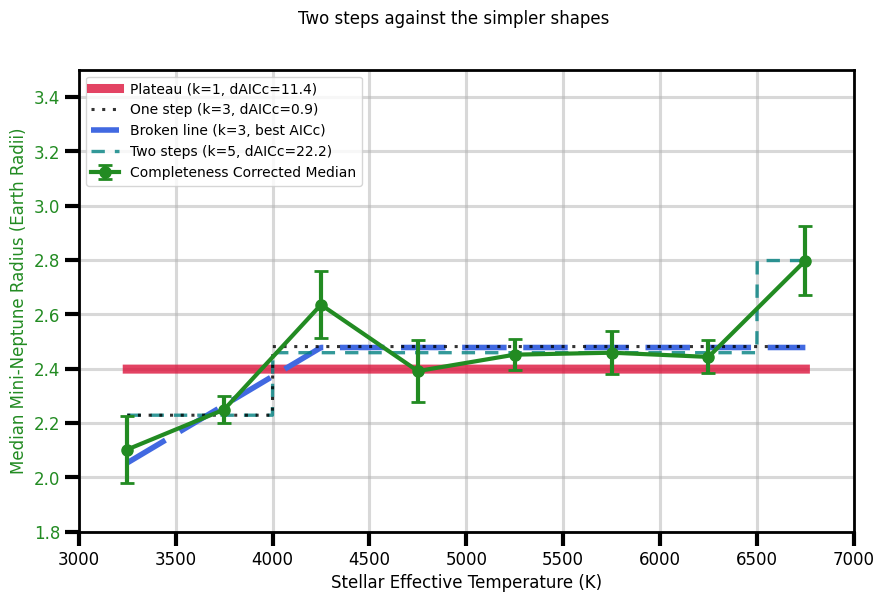

In [68]:
#### TWO STEPS vs THE SIMPLER SHAPES ####
# The referee question is whether the data need two changes of behaviour at all,
# and whether those changes are ramps or jumps. So this cell puts four shapes on
# the same 8 medians:
#
#   Plateau      k=1   one level everywhere
#   One step     k=3   a single jump, flat either side, location fitted
#   Broken line  k=3   the same rise-then-flat but with the break fitted
#   Two steps    k=5   three flat levels, two fitted jumps
#
# The two step models are discontinuous, so curve_fit cannot move their breakpoints:
# chi2 is piecewise constant in a jump location and the gradient is zero almost
# everywhere. Instead they are fitted by an exact grid search. A jump can only sit
# between two bins, which gives 7 places to put one, and for a fixed set of jumps
# the level of each flat segment that minimises chi2 is just the inverse-variance
# weighted mean of the bins in it. So the search below finds the global best fit
# rather than a local one, which curve_fit could not promise anyway.
#
# Uses x, y, yerr, n_bins, plateau, plateau_M, median_guess,
# slope_guess, x_min, x_max, x_span and bins_teff_fit from the fitting cell above.

# Jumps can only fall between adjacent bins, so these 7 edges are every distinct
# one-step fit there is
step_edges = []
for i in range(len(x) - 1):
    step_edges.append((x[i] + x[i + 1]) / 2)


def one_step(x, c_lo, x1, c_hi):
    # Flat at c_lo below x1, jumps to c_hi above it
    x = np.asarray(x, dtype=float)
    return np.where(x < x1, c_lo, c_hi)


def two_step(x, c_lo, x1, c_mid, x2, c_hi):
    # Three flat levels separated by jumps at x1 and x2
    x = np.asarray(x, dtype=float)
    return np.select([x < x1, (x >= x1) & (x < x2), x >= x2], [c_lo, c_mid, c_hi])


def weighted_level(values, sigmas):
    # Level that minimises chi2 for a flat segment: the inverse-variance mean
    weights = 1 / sigmas ** 2
    return np.sum(weights * values) / np.sum(weights)


# One step, searched over all 7 possible locations
one_step_chi2 = np.inf
one_step_params = None

for i in range(len(step_edges)):
    x1 = step_edges[i]
    below = x < x1
    params = [weighted_level(y[below], yerr[below]), x1,
              weighted_level(y[~below], yerr[~below])]
    chi2 = np.sum(((y - one_step(x, *params)) / yerr) ** 2)
    if chi2 < one_step_chi2:
        one_step_chi2 = chi2
        one_step_params = params

# Two steps, searched over all 21 ordered pairs of locations
two_step_chi2 = np.inf
two_step_params = None

for i in range(len(step_edges)):
    for j in range(i + 1, len(step_edges)):
        x1 = step_edges[i]
        x2 = step_edges[j]
        below = x < x1
        middle = (x >= x1) & (x < x2)
        above = x >= x2
        params = [weighted_level(y[below], yerr[below]), x1,
                  weighted_level(y[middle], yerr[middle]), x2,
                  weighted_level(y[above], yerr[above])]
        chi2 = np.sum(((y - two_step(x, *params)) / yerr) ** 2)
        if chi2 < two_step_chi2:
            two_step_chi2 = chi2
            two_step_params = params

# Three of these four sit on nearly the same plateau level between 4000 and 6250 K,
# so they are drawn as a ladder: thick and solid for the simplest shape, thinner
# and more finely dashed as k grows, each one layered over the ones below it. The
# dash periods are all different so that overlapping curves interleave instead of
# hiding each other, and the two step models are dashed and drawn last so their
# jumps stay visible where they cross the continuous shapes.
shapes = {
    'Plateau': {
        'func': plateau,
        'k': 1,
        'guesses': [[median_guess]],
        'bounds': (-np.inf, np.inf),
        'color': 'crimson',
        'linestyle': '-',
        'linewidth': 6.5,
        'zorder': 3,
    },
    'One step': {
        'func': one_step,
        'k': 3,
        'params': one_step_params,
        'chi2': one_step_chi2,
        'color': 'black',
        'linestyle': (0, (1, 2.5)),
        'linewidth': 2.2,
        'zorder': 8,
    },
    'Broken line': {
        'func': plateau_M,
        'k': 3,
        'guesses': [[median_guess, x_min + f * x_span, slope_guess]
                    for f in (0.2, 0.35, 0.5, 0.65, 0.8)],
        'bounds': ([-np.inf, x_min, -np.inf], [np.inf, x_max, np.inf]),
        'color': 'royalblue',
        'linestyle': (0, (8, 3)),
        'linewidth': 4.0,
        'zorder': 5,
    },
    'Two steps': {
        'func': two_step,
        'k': 5,
        'params': two_step_params,
        'chi2': two_step_chi2,
        'color': 'teal',
        'linestyle': (0, (4, 3)),
        'linewidth': 2.4,
        'zorder': 7,
    },
}

# Fit the continuous models, keeping the starting guess that gives the lowest chi2.
# The step models already have their params and chi2 from the grid search above.
for name, model in shapes.items():
    if 'chi2' in model:
        continue

    best_chi2 = np.inf
    best_params = None

    for guess in model['guesses']:
        try:
            params, _ = curve_fit(model['func'], x, y, p0=guess, sigma=yerr,
                                  absolute_sigma=True, bounds=model['bounds'], maxfev=40000)
        except Exception:
            continue
        chi2 = np.sum(((y - model['func'](x, *params)) / yerr) ** 2)
        if chi2 < best_chi2:
            best_chi2 = chi2
            best_params = params

    model['chi2'] = best_chi2
    model['params'] = best_params

for name, model in shapes.items():
    k = model['k']
    model['AIC'] = model['chi2'] + 2 * k
    model['AICc'] = model['AIC'] + 2 * k * (k + 1) / (n_bins - k - 1)
    model['BIC'] = model['chi2'] + k * np.log(n_bins)

best_shape = min(shapes, key=lambda name: shapes[name]['AICc'])
best_aicc_shape = shapes[best_shape]['AICc']
best_aic_shape = min(model['AIC'] for model in shapes.values())
best_bic_shape = min(model['BIC'] for model in shapes.values())

print(f"Two steps against the simpler shapes, {n_bins} bins")
print("=" * 76)
print(f"{'Model':<14}{'k':>3}{'chi2':>9}{'dof':>5}{'red.chi2':>10}{'AIC':>9}{'AICc':>9}{'BIC':>9}")
print("-" * 76)
for name, model in shapes.items():
    dof = n_bins - model['k']
    print(f"{name:<14}{model['k']:>3}{model['chi2']:>9.3f}{dof:>5}{model['chi2']/dof:>10.3f}"
          f"{model['AIC']:>9.3f}{model['AICc']:>9.3f}{model['BIC']:>9.3f}")

# Akaike weights over these four shapes
raw_weights = {name: np.exp(-0.5 * (model['AICc'] - best_aicc_shape)) for name, model in shapes.items()}
weight_sum = sum(raw_weights.values())

print(f"\n{'Model':<14}{'dAIC':>9}{'dAICc':>9}{'dBIC':>9}{'weight':>9}")
print("-" * 50)
for name in sorted(shapes, key=lambda name: shapes[name]['AICc']):
    model = shapes[name]
    print(f"{name:<14}{model['AIC']-best_aic_shape:>9.3f}{model['AICc']-best_aicc_shape:>9.3f}"
          f"{model['BIC']-best_bic_shape:>9.3f}{raw_weights[name]/weight_sum:>9.3f}")

print(f"\nPreferred by AICc: {best_shape}")

print("\nBest fit parameters (slopes per 1000 K):")
print(f"  Plateau:      c={shapes['Plateau']['params'][0]:.3f}")
print(f"  One step:     c_lo={one_step_params[0]:.3f}, x1={one_step_params[1]:.0f} K, "
      f"c_hi={one_step_params[2]:.3f}")
print(f"  Broken line:  c={shapes['Broken line']['params'][0]:.3f}, "
      f"x1={shapes['Broken line']['params'][1]:.0f} K, "
      f"s1={shapes['Broken line']['params'][2]*1000:.4f}")
print(f"  Two steps:    c_lo={two_step_params[0]:.3f}, x1={two_step_params[1]:.0f} K, "
      f"c_mid={two_step_params[2]:.3f}, x2={two_step_params[3]:.0f} K, "
      f"c_hi={two_step_params[4]:.3f}")

# What the second jump buys in chi2, against the one that keeps a single jump
print("\nWhat the second change of behaviour buys:")
print(f"  One step -> Two steps:      {one_step_chi2 - two_step_chi2:.3f} for 2 extra parameters")

# A step that isolates one or two bins is fitting those bins exactly rather than
# describing a population, so count what sits in each level
print("\nBins per flat level:")
print(f"  One step:    {np.sum(x < one_step_params[1])} below, "
      f"{np.sum(x >= one_step_params[1])} above")
print(f"  Two steps:   {np.sum(x < two_step_params[1])} below, "
      f"{np.sum((x >= two_step_params[1]) & (x < two_step_params[3]))} middle, "
      f"{np.sum(x >= two_step_params[3])} above")


# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

x_line = np.linspace(x_min, x_max, 2000)
for name, model in shapes.items():
    is_best = name == best_shape
    if is_best:
        label = f"{name} (k={model['k']}, best AICc)"
    else:
        label = f"{name} (k={model['k']}, dAICc={model['AICc']-best_aicc_shape:.1f})"
    ax.plot(x_line, model['func'](x_line, *model['params']), color=model['color'],
            linestyle=model['linestyle'], linewidth=model['linewidth'],
            alpha=1.0 if is_best else 0.8,
            zorder=model['zorder'], label=label)

ax.errorbar(x, y, yerr=yerr, color='forestgreen', label='Completeness Corrected Median',
            marker='o', linestyle='-', markersize=8, linewidth=3, capsize=5,
            capthick=2, zorder=9)

ax.set_xlabel('Stellar Effective Temperature (K)', size=12)
ax.set_ylabel('Median Mini-Neptune Radius (Earth Radii)', color='forestgreen', size=12)
ax.tick_params(axis='y', labelcolor='forestgreen')
ax.set_ylim(1.8, 3.5)
ax.set_xlim(bins_teff_fit[0], bins_teff_fit[-1])

fig.suptitle('Two steps against the simpler shapes', size=12)
ax.legend(loc='upper left', fontsize=10)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
ax.tick_params(axis='both', which='minor', width=2, length=6, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)
plt.show()

fig.savefig('statistical_analysis_teff_steps_vs_breaks.png', dpi=300, bbox_inches='tight')



500 K baseline: 8 bins, 0 dropped for no usable error
--------------------------------------------------------------
  Teff 3000-3500 K: N= 31, Median=2.10, Error=0.124 R_Earth
  Teff 3500-4000 K: N= 79, Median=2.25, Error=0.050 R_Earth
  Teff 4000-4500 K: N= 73, Median=2.64, Error=0.123 R_Earth
  Teff 4500-5000 K: N= 84, Median=2.39, Error=0.113 R_Earth
  Teff 5000-5500 K: N=121, Median=2.45, Error=0.057 R_Earth
  Teff 5500-6000 K: N=168, Median=2.46, Error=0.078 R_Earth  *** 1 with no completeness cell ***
  Teff 6000-6500 K: N= 99, Median=2.44, Error=0.061 R_Earth
  Teff 6500-7000 K: N= 18, Median=2.80, Error=0.126 R_Earth

Half-width 250 K: 16 bins, 0 dropped for no usable error
--------------------------------------------------------------
  Teff 3000-3250 K: N=  3, Median=1.84, Error=0.288 R_Earth
  Teff 3250-3500 K: N= 28, Median=2.11, Error=0.158 R_Earth
  Teff 3500-3750 K: N= 42, Median=2.25, Error=0.109 R_Earth
  Teff 3750-4000 K: N= 37, Median=2.25, Error=0.054 R_Earth
  Te

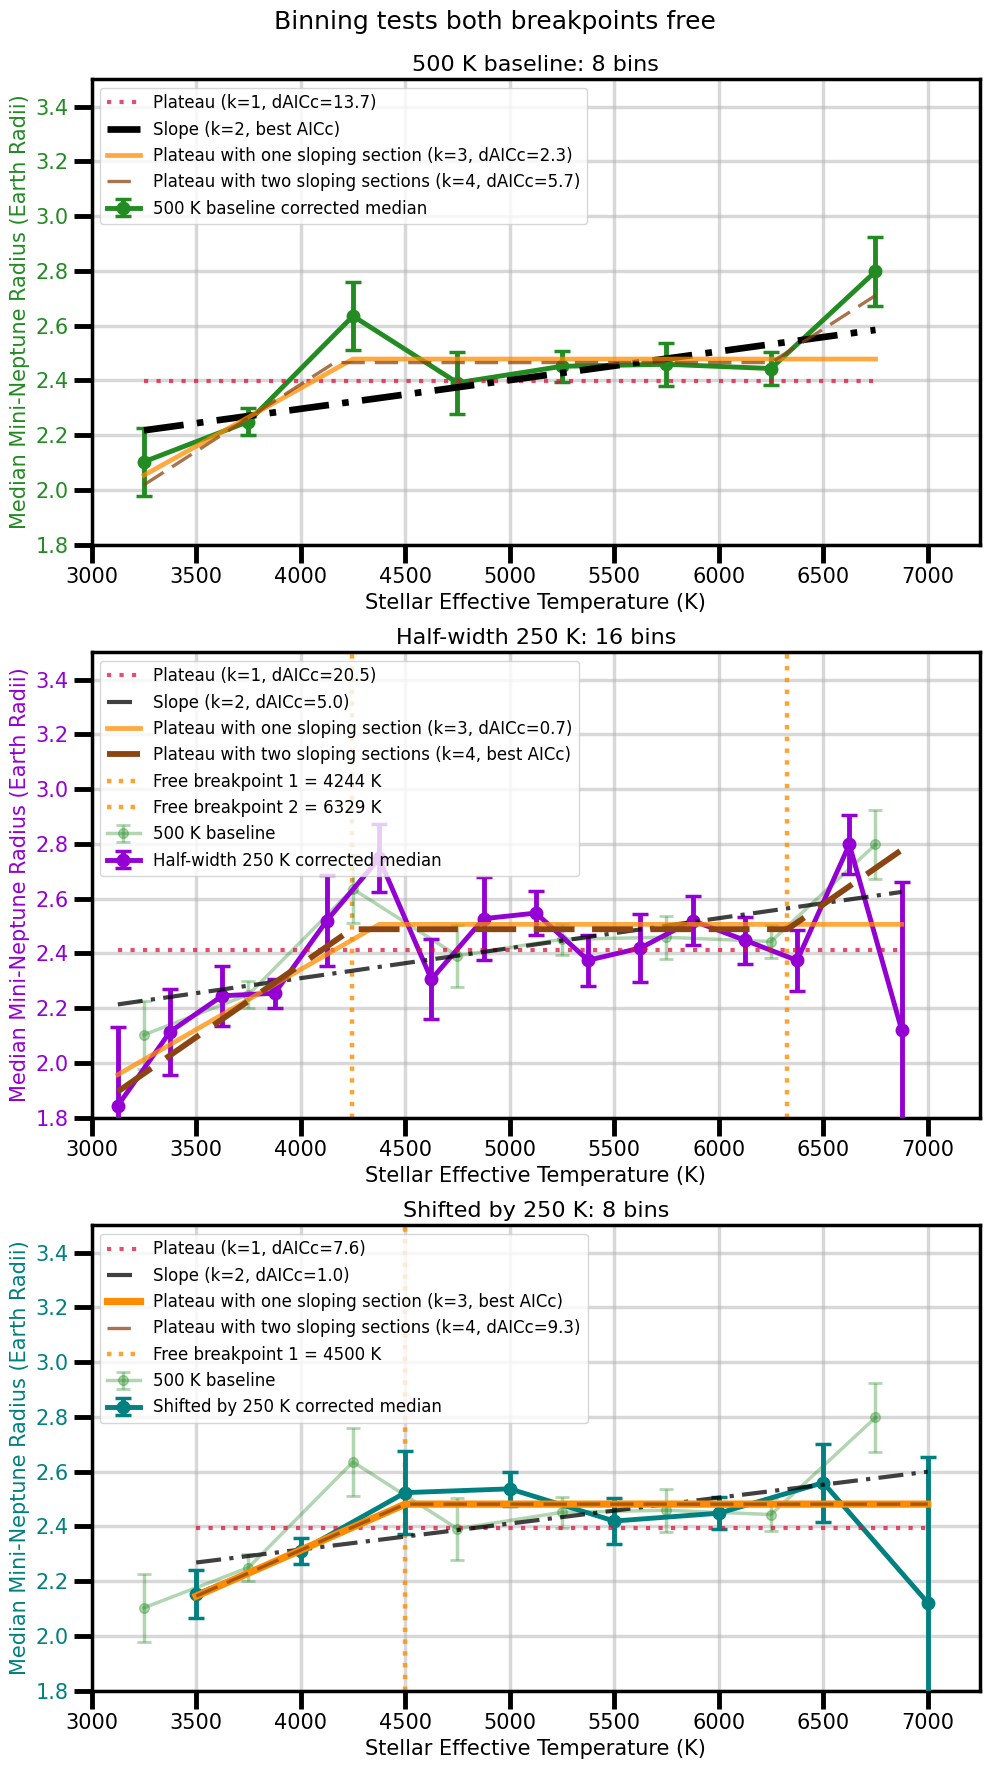

In [85]:
#### BINNING TESTS: HALF-WIDTH BINS AND A HALF-BIN SHIFT ####
# Everything above uses one Teff grid, 3000-7000 K in 500 K steps, and a referee is
# entitled to ask how much of the shape is the grid rather than the planets. So the
# same figure and the same model ladder are rebuilt twice more:
#
#   Half-width   250 K bins, 3000-7000 K   -- does the rise survive finer sampling
#   Shifted      500 K bins, 3250-7250 K   -- does it survive moving the edges
#
# The shifted grid runs to 7250 K rather than stopping at 6750 K. Ending it at the
# last whole bin would throw away the four hottest planets, and those four are
# exactly the ones the hot end of the baseline fit turns on, so the shifted test
# would answer an easier question than the one being asked. Nothing in the sample
# sits above 7000 K (the hottest star is 6920 K), so the bin reaches past the top
# of the completeness grid without ever picking up a planet that has no cell -- the
# count printed per bin below confirms it rather than assuming it.
#
# WHAT "RECALCULATING THE CORRECTIONS" CAN AND CANNOT MEAN HERE
# The completeness weight is a per-planet number: each TOI was matched to its own
# (Teff slice, radius bin, period bin) cell of the injection/recovery grid, and its
# weight is 1/detection_rate * 1/transit_prob for that cell. Regrouping planets into
# new Teff bins therefore recomputes the correction correctly -- every planet still
# carries the completeness of the cell it was actually measured in, and the weighted
# median of any grouping is well defined.
#
# What cannot be done without rerunning injection/recovery is refining the grid
# itself: the master heatmaps exist only in 500 K Teff slices. So a 250 K bin
# inherits the completeness of its parent 500 K slice and is blind to any variation
# of completeness inside that slice, and a shifted bin straddles two slices and
# mixes their grids. Neither biases the weighted median, but the corrections in the
# half-width test are not independent between neighbouring bin pairs.
#
# Uses merged_df, wmedian, plateau, plateau_M, symmetric and bins_teff_fit from
# the cells above.

planets_binning = merged_df.dropna(subset=['st_teff', 'pl_rade', 'weight'])

bins_half = list(range(3000, 7001, 250))
bins_shifted = list(range(3250, 7251, 500))


def corrected_medians(edges):
    # Completeness-corrected weighted median radius per Teff bin, with bootstrap
    # errors. Same procedure as the fitting cell, with the edges handed in. The
    # generator is reseeded per call so the binnings are compared on the same draws
    # and the 500 K case reproduces the numbers printed further up.
    rng = np.random.default_rng(11)

    centers = []
    medians = []
    errors = []
    counts = []
    no_cell = []

    for i in range(len(edges) - 1):
        bin_mask = (planets_binning['st_teff'] >= edges[i]) & (planets_binning['st_teff'] < edges[i + 1])
        radii = planets_binning.loc[bin_mask, 'pl_rade'].values
        weights = planets_binning.loc[bin_mask, 'weight'].values

        centers.append((edges[i] + edges[i + 1]) / 2)
        counts.append(len(radii))
        # A planet outside the 3000-7000 K completeness grid has no cell to match,
        # and its weight silently defaults to 1. Count them so a bin that reaches
        # past the grid cannot quietly mix corrected and uncorrected planets.
        no_cell.append(int(planets_binning.loc[bin_mask, 'detection_rate'].isna().sum()))

        if len(radii) == 0 or np.nansum(weights) <= 0:
            medians.append(np.nan)
            errors.append(np.nan)
            continue

        bootstrap_medians = []
        for _ in range(n_bootstrap_fit):
            pick = rng.integers(0, len(radii), size=len(radii))
            bootstrap_medians.append(wmedian(radii[pick], weights[pick]))

        medians.append(wmedian(radii, weights))
        errors.append(np.nanstd(bootstrap_medians))

    return np.array(centers), np.array(medians), np.array(errors), np.array(counts), np.array(no_cell)


def fit_ladder(x, y, yerr):
    # Flat, a straight slope, one sloping section, two sloping sections -- the
    # models from the fitting cell, refitted for whatever binning is handed in.
    # Guesses and breakpoint bounds come from this binning's own range, not the
    # 500 K one.
    n_bins = len(y)
    x_min = x.min()
    x_max = x.max()
    x_span = x_max - x_min
    median_guess = np.median(y)
    slope_guess = (y[-1] - y[0]) / x_span

    # The slope model in the fitting cell measures x from the global x_min of the
    # 500 K grid. Redefined here against this binning's own first bin centre so
    # that y0 always means the value at the cool end of the grid being fitted.
    # The fit is unchanged either way: moving the reference point only shifts what
    # y0 stands for, not the line it describes.
    def slope_here(x, y0, s):
        return y0 + s * (np.asarray(x, dtype=float) - x_min)

    ladder = {
        'Plateau': {
            'func': plateau,
            'k': 1,
            'guesses': [[median_guess]],
            'bounds': (-np.inf, np.inf),
        },
        'Slope': {
            'func': slope_here,
            'k': 2,
            'guesses': [[y[0], slope_guess]],
            'bounds': (-np.inf, np.inf),
        },
        'Plateau+M': {
            'func': plateau_M,
            'k': 3,
            'guesses': [[median_guess, x_min + f * x_span, slope_guess]
                        for f in (0.2, 0.35, 0.5, 0.65, 0.8)],
            'bounds': ([-np.inf, x_min, -np.inf], [np.inf, x_max, np.inf]),
        },
        'Symmetric': {
            'func': symmetric,
            'k': 4,
            'guesses': [[median_guess, x_min + a * x_span, x_min + b * x_span, slope_guess]
                        for a, b in ((0.2, 0.8), (0.3, 0.7), (0.15, 0.55),
                                     (0.45, 0.85), (0.35, 0.6))],
            'bounds': ([-np.inf, x_min, x_min, -np.inf], [np.inf, x_max, x_max, np.inf]),
        },
    }

    for name, model in ladder.items():
        best_chi2 = np.inf
        best_params = None

        for guess in model['guesses']:
            try:
                params, _ = curve_fit(model['func'], x, y, p0=guess, sigma=yerr,
                                      absolute_sigma=True, bounds=model['bounds'], maxfev=40000)
            except Exception:
                continue
            # Symmetric can fit crossed breakpoints, which are meaningless
            if name == 'Symmetric' and params[1] > params[2]:
                continue
            chi2 = np.sum(((y - model['func'](x, *params)) / yerr) ** 2)
            if chi2 < best_chi2:
                best_chi2 = chi2
                best_params = params

        k = model['k']
        model['chi2'] = best_chi2
        model['params'] = best_params
        model['AIC'] = best_chi2 + 2 * k
        model['AICc'] = model['AIC'] + 2 * k * (k + 1) / (n_bins - k - 1)
        model['BIC'] = best_chi2 + k * np.log(n_bins)

    return ladder


# The three binnings, baseline first so the tests can be read against it
tests = {
    '500 K baseline': {'edges': bins_teff_fit, 'color': 'forestgreen'},
    'Half-width 250 K': {'edges': bins_half, 'color': 'darkviolet'},
    'Shifted by 250 K': {'edges': bins_shifted, 'color': 'teal'},
}

for name, test in tests.items():
    centers, medians, errors, counts, no_cell = corrected_medians(test['edges'])

    # Keep only bins with a usable median and error, exactly as the fitting cell does
    good = ~(np.isnan(medians) | np.isnan(errors) | (errors == 0))
    test['x'] = centers[good]
    test['y'] = medians[good]
    test['yerr'] = errors[good]
    test['n_dropped'] = int((~good).sum())
    test['ladder'] = fit_ladder(test['x'], test['y'], test['yerr'])

    print(f"\n{name}: {len(test['edges']) - 1} bins, {test['n_dropped']} dropped for no usable error")
    print("-" * 62)
    for i in range(len(centers)):
        warn = f"  *** {no_cell[i]} with no completeness cell ***" if no_cell[i] else ""
        if good[i]:
            print(f"  Teff {test['edges'][i]}-{test['edges'][i+1]} K: N={counts[i]:>3}, "
                  f"Median={medians[i]:.2f}, Error={errors[i]:.3f} R_Earth{warn}")
        else:
            print(f"  Teff {test['edges'][i]}-{test['edges'][i+1]} K: N={counts[i]:>3}, dropped{warn}")

# One sloping section against two, in each binning
for name, test in tests.items():
    ladder = test['ladder']
    n_bins = len(test['y'])
    best_aicc = min(model['AICc'] for model in ladder.values())
    best_name = min(ladder, key=lambda name: ladder[name]['AICc'])

    print(f"\n{name}, {n_bins} bins fitted")
    print("=" * 62)
    print(f"{'Model':<12}{'k':>3}{'chi2':>9}{'dof':>5}{'red.chi2':>10}{'AICc':>9}{'dAICc':>9}")
    print("-" * 62)
    for model_name, model in ladder.items():
        dof = n_bins - model['k']
        print(f"{model_name:<12}{model['k']:>3}{model['chi2']:>9.3f}{dof:>5}"
              f"{model['chi2']/dof:>10.3f}{model['AICc']:>9.3f}{model['AICc']-best_aicc:>9.3f}")
    print(f"  Preferred by AICc: {best_name}")
    print(f"  Slope:             y0={ladder['Slope']['params'][0]:.3f}, "
          f"s={ladder['Slope']['params'][1]*1000:.4f} per 1000 K")
    print(f"  Plateau+M break:   x1={ladder['Plateau+M']['params'][1]:.0f} K, "
          f"s1={ladder['Plateau+M']['params'][2]*1000:.4f} per 1000 K")
    print(f"  Symmetric breaks:  x1={ladder['Symmetric']['params'][1]:.0f} K, "
          f"x2={ladder['Symmetric']['params'][2]:.0f} K, "
          f"s={ladder['Symmetric']['params'][3]*1000:.4f} per 1000 K")

    # A breakpoint sitting on the edge of the grid was not chosen by the data, the
    # fit just ran out of room. Symmetric with x2 on the bound is Plateau+M with a
    # wasted parameter, which is worth seeing before reading anything into x2.
    for label, value in (('x1', ladder['Symmetric']['params'][1]),
                         ('x2', ladder['Symmetric']['params'][2])):
        if np.isclose(value, test['x'].min()) or np.isclose(value, test['x'].max()):
            print(f"    Symmetric {label}={value:.0f} K sits on the grid bound, "
                  f"so it was bounded rather than chosen")

# Does the answer move when the grid moves? Read across the binnings, not down
print("\n\nDoes the result survive the rebinning?")
print("=" * 80)
print(f"{'Binning':<18}{'preferred':>12}{'M break':>10}{'x1':>8}{'x2':>8}"
      f"{'dAICc 2-1':>11}{'dAICc slope':>13}")
print("-" * 80)
for name, test in tests.items():
    ladder = test['ladder']
    best_name = min(ladder, key=lambda name: ladder[name]['AICc'])
    best_aicc = ladder[best_name]['AICc']
    # Positive means the one-slope model is preferred over the two-slope one
    delta = ladder['Symmetric']['AICc'] - ladder['Plateau+M']['AICc']
    print(f"{name:<18}{best_name:>12}{ladder['Plateau+M']['params'][1]:>10.0f}"
          f"{ladder['Symmetric']['params'][1]:>8.0f}{ladder['Symmetric']['params'][2]:>8.0f}"
          f"{delta:>11.2f}{ladder['Slope']['AICc']-best_aicc:>13.2f}")
print("\ndAICc 2-1 is Symmetric minus Plateau+M: positive favours one sloping section.")
print("dAICc slope is the straight line against the best model in that binning.")


# Create the plot
fig, axes = plt.subplots(3, 1, figsize=(10, 18))

baseline = tests['500 K baseline']

for ax, (name, test) in zip(axes, tests.items()):
    ladder = test['ladder']
    best_name = min(ladder, key=lambda name: ladder[name]['AICc'])
    best_aicc = ladder[best_name]['AICc']

    ax.grid(True, which='major', linewidth=2.5, alpha=0.5, color='0.7')
    ax.set_axisbelow(True)

    # The 500 K result faded underneath, so each test can be read against it. The
    # baseline panel is that result, so it does not need drawing twice.
    if name != '500 K baseline':
        ax.errorbar(baseline['x'], baseline['y'], yerr=baseline['yerr'],
                    color='forestgreen', alpha=0.35, label='500 K baseline',
                    marker='o', linestyle='-', markersize=7, linewidth=2.5,
                    capsize=5, capthick=2, zorder=2)

    ax.errorbar(test['x'], test['y'], yerr=test['yerr'], color=test['color'],
                label=f'{name} corrected median', marker='o', linestyle='-',
                markersize=9, linewidth=3.5, capsize=6, capthick=2.5, zorder=4)

    # All four models drawn, the AICc-preferred one heavier, so the comparison can
    # be read by eye as well as from the table above
    # Spelled-out names for the legend only; the keys and the printed tables keep the
    # shorthand so the code above stays readable
    model_labels = {
        'Plateau': 'Plateau',
        'Slope': 'Slope',
        'Plateau+M': 'Plateau with one sloping section',
        'Symmetric': 'Plateau with two sloping sections',
    }

    model_styles = {
        'Plateau': ('crimson', (0, (1, 2)), 3.0),
        'Slope': ('black', (0, (6, 2, 1, 2)), 3.0),
        'Plateau+M': ('darkorange', '-', 3.4),
        'Symmetric': ('saddlebrown', (0, (7, 3)), 2.4),
    }
    x_line = np.linspace(test['x'].min(), test['x'].max(), 400)
    for model_name, (color, linestyle, linewidth) in model_styles.items():
        model = ladder[model_name]
        is_best = model_name == best_name
        if is_best:
            label = f"{model_labels[model_name]} (k={model['k']}, best AICc)"
        else:
            label = (f"{model_labels[model_name]} (k={model['k']}, "
                     f"dAICc={model['AICc']-best_aicc:.1f})")
        ax.plot(x_line, model['func'](x_line, *model['params']), color=color,
                linestyle=linestyle, linewidth=linewidth + 1.8 if is_best else linewidth,
                alpha=1.0 if is_best else 0.75, zorder=5, label=label)

    # Fitted breakpoints of the preferred model, when it has any. Plateau and Slope
    # have none, and their second parameter is a level or a gradient, not a Teff.
    if best_name == 'Symmetric':
        breaks = ladder['Symmetric']['params'][1:3]
    elif best_name == 'Plateau+M':
        breaks = ladder['Plateau+M']['params'][1:2]
    else:
        breaks = []
    break_labels = ['Free breakpoint 1', 'Free breakpoint 2']
    for i in range(len(breaks)):
        ax.axvline(breaks[i], color='darkorange', linestyle=':', linewidth=3.2, alpha=0.8,
                   zorder=1, label=f"{break_labels[i]} = {breaks[i]:.0f} K")

    ax.set_xlabel('Stellar Effective Temperature (K)', size=15)
    ax.set_ylabel('Median Mini-Neptune Radius (Earth Radii)', color=test['color'], size=15)
    ax.tick_params(axis='y', labelcolor=test['color'])
    ax.set_xlim(3000, 7250)
    ax.set_ylim(1.8, 3.5)

    ax.set_title(f"{name}: {len(test['y'])} bins", size=16)
    ax.legend(loc='upper left', fontsize=12)
    ax.tick_params(axis='both', which='major', width=3.5, length=13, labelsize=15)
    ax.tick_params(axis='both', which='minor', width=2.5, length=8, labelsize=15)
    for spine in ax.spines.values():
        spine.set_linewidth(2.5)

fig.suptitle('Binning tests both breakpoints free', size=18)
# Leave room for the suptitle, which tight_layout otherwise runs the first panel into
fig.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()


fig.savefig('statistical_analysis_teff_binning_tests.png', dpi=300, bbox_inches='tight')



Pin 1.10 Msun = 6014 K, swept 1.03-1.17 Msun = 5860-6154 K

500 K baseline, 8 bins, x2 pinned at 6014 K
Model               k     chi2  dof  red.chi2     AICc    dAICc
------------------------------------------------------------------
Plateau             1   30.301    7     4.329   32.968   15.725
Slope               2   12.822    6     2.137   19.222    1.979
Plateau+M           3    9.535    5     1.907   21.535    4.291
Symmetric pinned    3    5.243    5     1.049   17.243    0.000
Symmetric free      4    3.574    4     0.893   24.907    7.664
  Pinned fit: c=2.437, x1=4250 K, s=0.3566 per 1000 K

Half-width 250 K, 16 bins, x2 pinned at 6014 K
Model               k     chi2  dof  red.chi2     AICc    dAICc
------------------------------------------------------------------
Plateau             1   45.285   15     3.019   47.571   22.038
Slope               2   27.190   14     1.942   32.113    6.580
Plateau+M           3   19.747   13     1.519   27.747    2.215
Symmetric pinned    

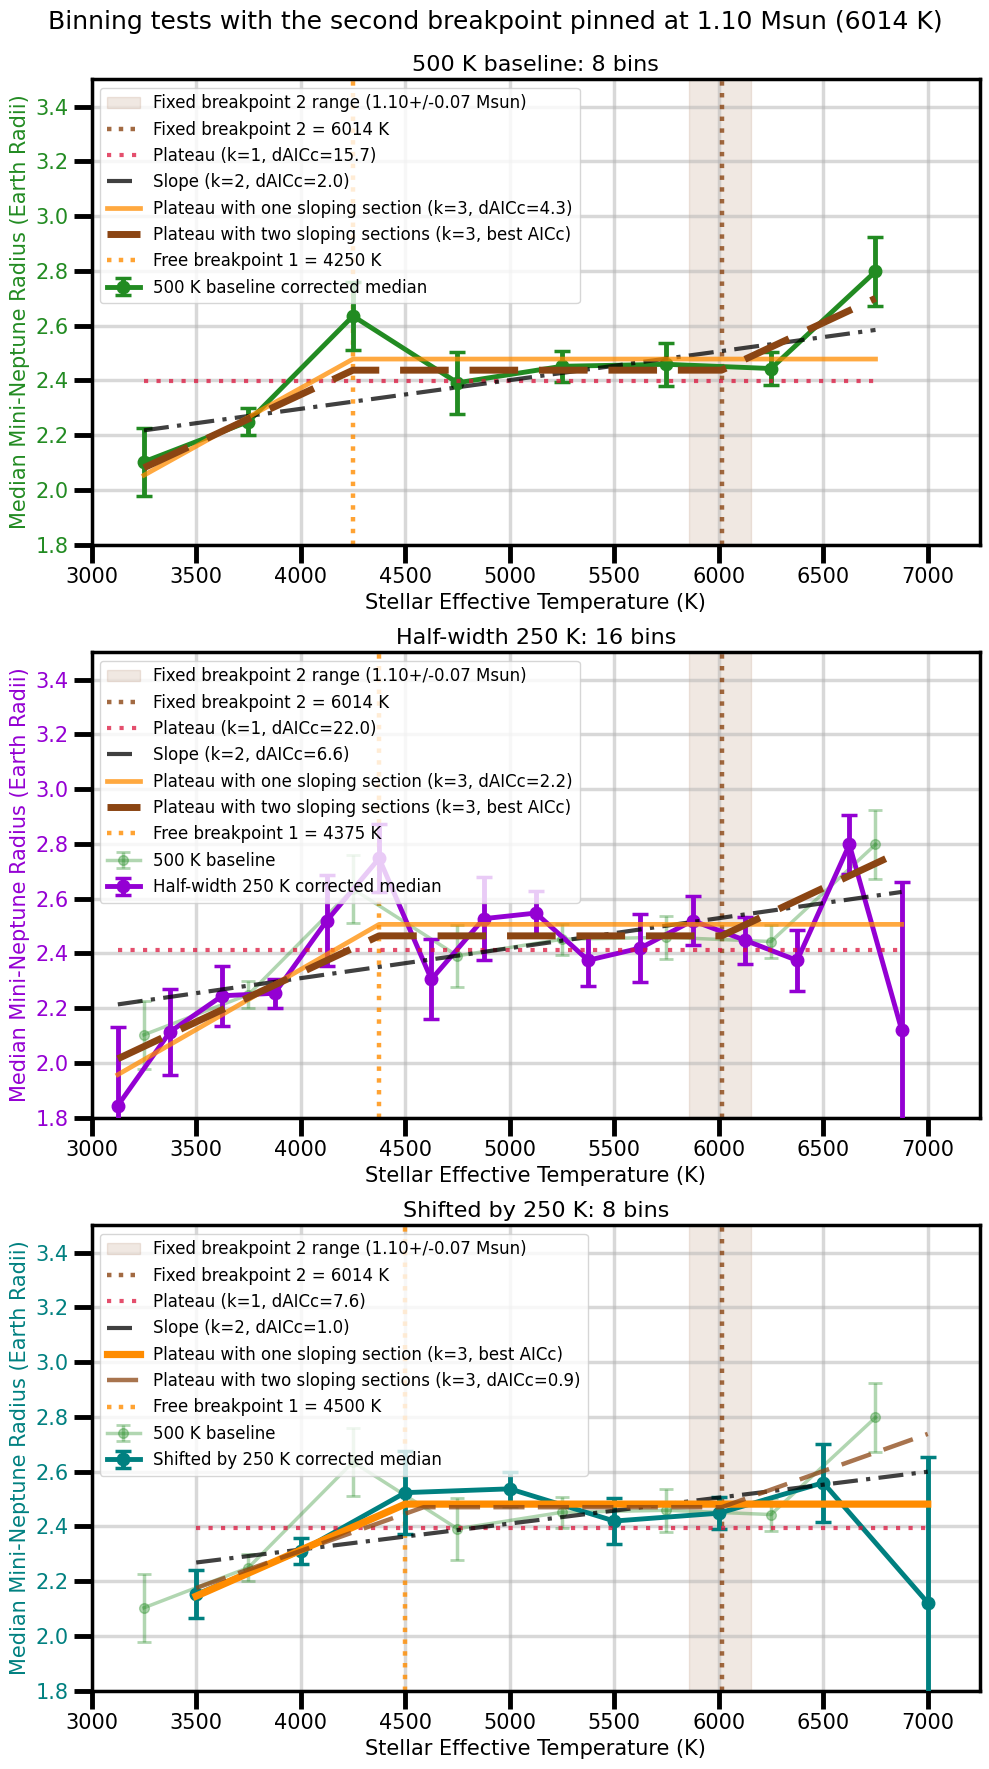

In [86]:
#### BINNING TESTS WITH THE SECOND BREAKPOINT PINNED AT 1.1 MSUN ####
# In the cell above both breakpoints float, and the hot one is the unstable part of
# the answer: free, it lands at 6250 K on the 500 K grid, 6329 K on the half-width
# grid, and on the bound at 7000 K on the shifted grid, where it bought nothing.
# Pinning it on physical grounds, as was done for the 500 K grid earlier, takes that
# freedom away and drops Symmetric from k=4 to k=3 -- the same cost as Plateau+M, so
# one sloping section and two can finally be compared at equal price.
#
# The pin is 1.1 Msun on the Mamajek (2022) dwarf sequence, the same value and the
# same interpolation used before. It is swept over +/- 0.07 Msun so that the answer
# cannot rest on a single by-eye number: if pinned Symmetric only wins in a narrow
# window, that is an artefact of where the pin was put, not evidence of a break.
#
# Uses tests (with x, y, yerr and the free-breakpoint ladder already fitted),
# plateau, plateau_M and curve_fit from the cells above.

# Mamajek (2022) dwarf sequence, the rows spanning the pin range. Interpolating
# 1.10 Msun in this table gives 6014 K, which is the value pinned earlier.
mamajek_mass = [1.00, 1.03, 1.06, 1.08, 1.13, 1.18, 1.21]
mamajek_teff = [5770, 5860, 5930, 5990, 6050, 6180, 6280]


def teff_for_mass(mass):
    # Linear interpolation onto the dwarf sequence, as used for the earlier pin
    return float(np.interp(mass, mamajek_mass, mamajek_teff))


pin_mass = 1.10
pin_spread = 0.07
pin_masses = np.round(np.arange(pin_mass - pin_spread, pin_mass + pin_spread + 0.001, 0.01), 2)

teff_pin = teff_for_mass(pin_mass)
teff_pin_low = teff_for_mass(pin_mass - pin_spread)
teff_pin_high = teff_for_mass(pin_mass + pin_spread)

print(f"Pin {pin_mass:.2f} Msun = {teff_pin:.0f} K, swept "
      f"{pin_mass - pin_spread:.2f}-{pin_mass + pin_spread:.2f} Msun = "
      f"{teff_pin_low:.0f}-{teff_pin_high:.0f} K")


def make_symmetric_pinned(x2_fixed):
    # Symmetric with the upper break held at x2_fixed, so only c, x1 and s are
    # fitted and the model costs k=3 rather than k=4
    def model(x, c, x1, s):
        x = np.asarray(x, dtype=float)
        return np.select(
            [x < x1, (x >= x1) & (x <= x2_fixed), x > x2_fixed],
            [c + s * (x - x1), np.full_like(x, c), c + s * (x - x2_fixed)],
        )
    return model


def fit_symmetric_pinned(x, y, yerr, x2_fixed):
    # x1 is bounded above by the pin so the two breakpoints cannot cross, and it
    # gets several starting guesses because the chi2 surface is multi-modal
    model_func = make_symmetric_pinned(x2_fixed)
    x_min = x.min()
    median_guess = np.median(y)
    slope_guess = (y[-1] - y[0]) / (x.max() - x_min)

    best_chi2 = np.inf
    best_params = None

    for f in (0.2, 0.35, 0.5, 0.65, 0.8):
        guess = [median_guess, x_min + f * (x2_fixed - x_min), slope_guess]
        try:
            params, _ = curve_fit(model_func, x, y, p0=guess, sigma=yerr,
                                  absolute_sigma=True, maxfev=40000,
                                  bounds=([-np.inf, x_min, -np.inf],
                                          [np.inf, x2_fixed, np.inf]))
        except Exception:
            continue
        chi2 = np.sum(((y - model_func(x, *params)) / yerr) ** 2)
        if chi2 < best_chi2:
            best_chi2 = chi2
            best_params = params

    return best_chi2, best_params, model_func


# Fit the pinned model in each binning at the central pin, and keep the rivals that
# do not involve x2 at all -- Plateau, Slope and Plateau+M are unchanged from the
# cell above, so they are the bar the pinned model has to clear.
rivals = ['Plateau', 'Slope', 'Plateau+M']

for name, test in tests.items():
    x = test['x']
    y = test['y']
    yerr = test['yerr']
    n_bins = len(y)

    chi2_pin, params_pin, func_pin = fit_symmetric_pinned(x, y, yerr, teff_pin)
    k_pin = 3
    aicc_pin = chi2_pin + 2 * k_pin + 2 * k_pin * (k_pin + 1) / (n_bins - k_pin - 1)

    test['pin_chi2'] = chi2_pin
    test['pin_params'] = params_pin
    test['pin_func'] = func_pin
    test['pin_AICc'] = aicc_pin

    ladder = test['ladder']
    entries = [(rival, ladder[rival]['k'], ladder[rival]['chi2'], ladder[rival]['AICc'])
               for rival in rivals]
    entries.append(('Symmetric pinned', k_pin, chi2_pin, aicc_pin))
    entries.append(('Symmetric free', 4, ladder['Symmetric']['chi2'], ladder['Symmetric']['AICc']))
    best_aicc = min(entry[3] for entry in entries)

    print(f"\n{name}, {n_bins} bins, x2 pinned at {teff_pin:.0f} K")
    print("=" * 66)
    print(f"{'Model':<18}{'k':>3}{'chi2':>9}{'dof':>5}{'red.chi2':>10}{'AICc':>9}{'dAICc':>9}")
    print("-" * 66)
    for model_name, k, chi2, aicc in entries:
        dof = n_bins - k
        print(f"{model_name:<18}{k:>3}{chi2:>9.3f}{dof:>5}{chi2/dof:>10.3f}"
              f"{aicc:>9.3f}{aicc - best_aicc:>9.3f}")
    print(f"  Pinned fit: c={params_pin[0]:.3f}, x1={params_pin[1]:.0f} K, "
          f"s={params_pin[2]*1000:.4f} per 1000 K")

# Sweep the pin across +/- 0.07 Msun. The rivals do not depend on x2, so their AICc
# is fixed while the pinned model's moves, and the question is whether it clears them
# everywhere in the range, somewhere, or nowhere.
print("\n\nDoes pinning survive the sweep?")
print("=" * 84)
print(f"{'Binning':<18}{'rival':>12}{'rival AICc':>12}{'pinned best':>13}"
      f"{'pinned worst':>14}{'wins at':>11}")
print("-" * 84)

for name, test in tests.items():
    x = test['x']
    y = test['y']
    yerr = test['yerr']
    n_bins = len(y)
    ladder = test['ladder']

    rival_name = min(rivals, key=lambda rival: ladder[rival]['AICc'])
    rival_aicc = ladder[rival_name]['AICc']

    sweep_aicc = []
    for mass in pin_masses:
        chi2, params, func = fit_symmetric_pinned(x, y, yerr, teff_for_mass(mass))
        k = 3
        sweep_aicc.append(chi2 + 2 * k + 2 * k * (k + 1) / (n_bins - k - 1))
    sweep_aicc = np.array(sweep_aicc)

    test['sweep_aicc'] = sweep_aicc
    wins = int((sweep_aicc < rival_aicc).sum())

    print(f"{name:<18}{rival_name:>12}{rival_aicc:>12.3f}{sweep_aicc.min():>13.3f}"
          f"{sweep_aicc.max():>14.3f}{wins:>7}/{len(pin_masses)}")

print("\nPinned best/worst are the AICc of the pinned model over the swept range.")
print("'wins at' counts the pins where it beats the best model that has no x2.")


# Create the plot
fig, axes = plt.subplots(3, 1, figsize=(10, 18))

baseline = tests['500 K baseline']

for ax, (name, test) in zip(axes, tests.items()):
    ladder = test['ladder']

    # Everything here is k=3 except Plateau and Slope, so the AICc winner is chosen
    # across the rivals and the pinned model together
    candidates = {rival: ladder[rival]['AICc'] for rival in rivals}
    candidates['Symmetric pinned'] = test['pin_AICc']
    best_name = min(candidates, key=lambda model_name: candidates[model_name])
    best_aicc = candidates[best_name]

    ax.grid(True, which='major', linewidth=2.5, alpha=0.5, color='0.7')
    ax.set_axisbelow(True)

    # The band of pinned breakpoints, so the sweep is visible rather than described
    ax.axvspan(teff_pin_low, teff_pin_high, color='saddlebrown', alpha=0.12, zorder=0,
               label=f'Fixed breakpoint 2 range ({pin_mass:.2f}+/-{pin_spread:.2f} Msun)')
    ax.axvline(teff_pin, color='saddlebrown', linestyle=':', linewidth=3.2, alpha=0.8,
               zorder=1, label=f'Fixed breakpoint 2 = {teff_pin:.0f} K')

    if name != '500 K baseline':
        ax.errorbar(baseline['x'], baseline['y'], yerr=baseline['yerr'],
                    color='forestgreen', alpha=0.35, label='500 K baseline',
                    marker='o', linestyle='-', markersize=7, linewidth=2.5,
                    capsize=5, capthick=2, zorder=2)

    ax.errorbar(test['x'], test['y'], yerr=test['yerr'], color=test['color'],
                label=f'{name} corrected median', marker='o', linestyle='-',
                markersize=9, linewidth=3.5, capsize=6, capthick=2.5, zorder=4)

    # Spelled-out names for the legend only; the keys and the printed tables keep the
    # shorthand so the code above stays readable
    model_labels = {
        'Plateau': 'Plateau',
        'Slope': 'Slope',
        'Plateau+M': 'Plateau with one sloping section',
        'Symmetric': 'Plateau with two sloping sections',
    }

    model_styles = {
        'Plateau': ('crimson', (0, (1, 2)), 3.0),
        'Slope': ('black', (0, (6, 2, 1, 2)), 3.0),
        'Plateau+M': ('darkorange', '-', 3.4),
    }
    x_line = np.linspace(test['x'].min(), test['x'].max(), 400)
    for model_name, (color, linestyle, linewidth) in model_styles.items():
        model = ladder[model_name]
        is_best = model_name == best_name
        if is_best:
            label = f"{model_labels[model_name]} (k={model['k']}, best AICc)"
        else:
            label = (f"{model_labels[model_name]} (k={model['k']}, "
                     f"dAICc={model['AICc']-best_aicc:.1f})")
        ax.plot(x_line, model['func'](x_line, *model['params']), color=color,
                linestyle=linestyle, linewidth=linewidth + 1.8 if is_best else linewidth,
                alpha=1.0 if is_best else 0.75, zorder=5, label=label)

    is_best = best_name == 'Symmetric pinned'
    if is_best:
        label = f"{model_labels['Symmetric']} (k=3, best AICc)"
    else:
        label = (f"{model_labels['Symmetric']} (k=3, "
                 f"dAICc={test['pin_AICc']-best_aicc:.1f})")
    ax.plot(x_line, test['pin_func'](x_line, *test['pin_params']), color='saddlebrown',
            linestyle=(0, (7, 3)), linewidth=5.0 if is_best else 3.2,
            alpha=1.0 if is_best else 0.75, zorder=6, label=label)

    # The cool-end breakpoint is still fitted even when the hot one is held, so it is
    # drawn like the free breakpoints in the cell above. Plateau and Slope have none.
    if best_name == 'Symmetric pinned':
        free_break = test['pin_params'][1]
    elif best_name == 'Plateau+M':
        free_break = ladder['Plateau+M']['params'][1]
    else:
        free_break = None
    if free_break is not None:
        ax.axvline(free_break, color='darkorange', linestyle=':', linewidth=3.2, alpha=0.8,
                   zorder=1, label=f'Free breakpoint 1 = {free_break:.0f} K')

    ax.set_xlabel('Stellar Effective Temperature (K)', size=15)
    ax.set_ylabel('Median Mini-Neptune Radius (Earth Radii)', color=test['color'], size=15)
    ax.tick_params(axis='y', labelcolor=test['color'])
    ax.set_xlim(3000, 7250)
    ax.set_ylim(1.8, 3.5)

    ax.set_title(f"{name}: {len(test['y'])} bins", size=16)
    ax.legend(loc='upper left', fontsize=12)
    ax.tick_params(axis='both', which='major', width=3.5, length=13, labelsize=15)
    ax.tick_params(axis='both', which='minor', width=2.5, length=8, labelsize=15)
    for spine in ax.spines.values():
        spine.set_linewidth(2.5)

fig.suptitle(f'Binning tests with the second breakpoint pinned at {pin_mass:.2f} Msun '
             f'({teff_pin:.0f} K)', size=18)
# Leave room for the suptitle, which tight_layout otherwise runs the first panel into
fig.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()

fig.savefig('statistical_analysis_teff_binning_tests_pinned.png', dpi=300, bbox_inches='tight')
